# Emoji-Intent-Aware Multitask Learning for Bangla Sarcasm & Offensive Detection

An emoji-aware pipeline that treats emojis as **language-independent intent anchors** for the *simultaneous* detection of sarcasm and offensiveness in Bangla. The system combines a **leakage-free emoji intent encoder** (the core novelty), a **multilingual BERT (mBERT)** multitask backbone with **cross-stitch soft-sharing** and **layer-wise freezing**, **LIME** explainability computed on the model's true (preprocessed) input, and a **full statistical-significance protocol** — bootstrap 95 % CIs, label-permutation tests, one-sided McNemar, paired *t*-tests and Wilcoxon signed-rank tests, χ² task-dependence and across-fold variance.

Results are reported for a **single reference run at seed 42 with 5-fold cross-validation**, evaluated as a **5-fold ensemble** on a stratified hold-out test set that is carved out *before* any fitting. Every ablation shares the same folds, seed, budget and hyper-parameters, so each reported difference is attributable to the ablated component alone.

**This build changes three things versus the BanglaBERT reference run.** (1) The backbone is migrated to **mBERT**, with the embedding layer and the bottom 6 of 12 encoder layers **frozen**, and `MAX_LEN` **recalibrated for mBERT's WordPiece vocabulary** rather than inherited from BanglaBERT (Section 6b). (2) Three targeted optimisations aim at the weaker **offensive** task: a stronger supervised-contrastive weight, an asymmetric offensive task weight, and post-hoc **decision-threshold tuning** on out-of-fold predictions (Section 13e). (3) The fold indices and `SEED = 42` are held **byte-identical** to the BanglaBERT run, so the two backbones can be compared with paired statistical tests.


## Section 0 — Environment, Dependencies & Global Configuration

In [50]:
# Colab/Kaggle: install once.  (SHAP removed — not used anymore.)
# NOTE: version-sensitive packages are UPGRADED (-U) and pinned to a floor, so a
# stale pre-installed build cannot linger. A too-old `lime` is what lacked the
# `split_expr` kwarg used in Section 14; a too-old `hyperopt` rejects the
# default_rng `rstate` in Section 11.
!pip install -q -U "lime>=0.2.0.1" "hyperopt>=0.2.7"
!pip install -q "transformers>=4.40" "datasets" "scikit-learn" "pandas" "numpy" \
                "openpyxl" "emoji>=2.10" "scipy" \
                "matplotlib" "seaborn" "tqdm"

# BanglaBERT REQUIRES the csebuetnlp text normalizer to be applied BEFORE tokenizing
# (see Section 3). Install it here; the import is guarded in Section 3 so the notebook
# still runs (with a warning) if this install is unavailable in an offline environment.
!pip install -q "git+https://github.com/csebuetnlp/normalizer"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
normalizer 0.0.1 requires emoji==1.4.2, but you have emoji 2.15.0 which is incompatible.
  Preparing metadata (setup.py) ... done


In [51]:
import os, re, random, copy, warnings, math
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import emoji as emojilib
warnings.filterwarnings("ignore")

# ---- Reproducibility ----------------------------------------------------------
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==============================================================================
# BACKBONE SELECTION — mBERT
# ==============================================================================
# NOTE ON THE CASED vs UNCASED CHOICE (verified, not assumed):
#   `bert-base-multilingual-uncased` lowercases AND strips accents. HuggingFace's
#   BertTokenizer implements accent-stripping as "NFD-decompose, then drop every
#   Unicode category-Mn character". In Bengali the HASANT / VIRAMA (্ U+09CD) and the
#   NUKTA (় U+09BC) are BOTH category Mn -> they are DELETED. That destroys every
#   conjunct (যুক্তাক্ষর) and collapses ড/ড় and র/ড়. Google's own multilingual README
#   likewise recommends the CASED model for all languages.
#   Section 6b runs a self-test that demonstrates this on real corpus text.
#   => default to the CASED model. If MBERT_UNCASED is forced True, we explicitly pass
#      strip_accents=False so Bangla survives.
BANGLABERT_NAME = "csebuetnlp/banglabert"     # previous backbone, kept for reference/comparison
MBERT_UNCASED   = False                        # True -> bert-base-multilingual-uncased (NOT recommended)
MBERT_NAME      = "bert-base-multilingual-uncased" if MBERT_UNCASED else "bert-base-multilingual-cased"

# ---- Global configuration -----------------------------------------------------
CFG = {
    "QUICK_SMOKE_TEST": False,    # True -> tiny/fast end-to-end sanity run
    "MODEL_NAME":   MBERT_NAME,   # ACTIVE backbone (was csebuetnlp/banglabert)
    "REF_BACKBONE": BANGLABERT_NAME,

    # MAX_LEN is INHERITED from the BanglaBERT run and is NOT trusted here:
    # mBERT's multilingual WordPiece vocabulary fragments Bangla into more subwords than
    # a Bangla-specific tokenizer. Section 6b recomputes the token-length percentile with
    # the ACTIVE tokenizer and overwrites this value if 96 truncates too many samples.
    "MAX_LEN":            96,
    "MAX_LEN_PCTL":       99,     # percentile used for the recalibration decision
    "MAX_LEN_TRUNC_TOL":  0.02,   # allowed truncation rate (2%); above this -> raise MAX_LEN
    "MAX_LEN_CANDIDATES": [96, 128, 160, 192, 256],

    "N_SPLITS":     5,
    "TEST_SIZE":    0.15,
    "MAX_EPOCHS":   20,           # ceiling only — early stopping usually ends sooner
    "PATIENCE":     3,
    "SCHED_EPOCHS": 12,
    "WARMUP_RATIO": 0.1,
    "WEIGHT_DECAY": 0.01,
    "GRAD_CLIP":    1.0,

    # ---- Task 2: layer-wise freezing (mBERT) ------------------------------------
    # Freeze embeddings + the bottom N of 12 encoder layers; fine-tune the top layers and
    # all task-specific heads. Fewer trainable parameters on a ~2.6k-row corpus reduces
    # overfitting variance. Pure config change: the EmoMTL wrapper, cross-stitch and heads
    # are structurally untouched.
    "FREEZE_EMBEDDINGS":  True,
    "FREEZE_BOTTOM_N":    6,

    # ---- Task 3b: supervised-contrastive weight ---------------------------------
    # Raised 0.1 -> 0.5. Error analysis on the reference run showed the Sarc+Abuse joint
    # class is the hardest (47/71 correct, 26.8% offensive error). SupCon pulls same-class
    # embeddings together, carving a distinct "both" region away from pure-sarcasm.
    "USE_SUPCON":   True,
    "SUPCON_W":     0.5,          # was 0.1
    "SUPCON_LABEL_MODE": "joint", # "sarc" = old behaviour; "joint" contrasts the 4-way
                                  #   (sarc, off) class, which is what actually separates Sarc+Abuse
    # ---- Task 3c: asymmetric offensive task weight ------------------------------
    # See Section 9 for the derivation: multiplying the offensive loss INSIDE the
    # uncertainty weighting is provably absorbed by the learned log-variance, so the
    # default applies the weight OUTSIDE it ("outer"), which is a true reweighting.
    "OFF_TASK_WEIGHT":      1.5,  # 1.0 -> identical to the previous behaviour
    "OFF_TASK_WEIGHT_MODE": "outer",   # "outer" (true reweighting) | "inner" (literal, self-cancelling)

    # ---- Task 3a/3d: post-hoc decision-threshold tuning (Section 13e) -----------
    "TUNE_THRESHOLDS": True,
    "THRESHOLD_GRID":  [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65],

    # ---- Phase 2+ options: OFF by default, enable only after the fold-0 gate ------
    "USE_CLASS_BALANCED_SAMPLER": False,   # Task 4  (Phase 2)
    "SAMPLER_BOTH_WEIGHT":        2.5,     #   oversampling factor for the Sarc+Abuse class
    "USE_HARD_NEGATIVE_MINING":   False,   # Task 5  (Phase 3)
    "HNM_TOPK_FRAC":              0.25,    #   fraction of hardest Sarc+Abuse rows to upweight
    "HNM_BOOST":                  2.0,
    "USE_FOCAL_OFFENSIVE":        False,   # Task 7  (Phase 4, last resort)
    "FOCAL_ALPHA":                0.25,
    "FOCAL_GAMMA":                2.0,

    "INTENT_MIN_COUNT": 3,
    "INTENT_SMOOTH_M":  5.0,
    "HPO_MAX_EVALS": 10,
    "HPO_PROXY_SIZE": 1000,
    "HPO_PROXY_EPOCHS": 3,

    # ---- statistical-significance controls -------------------------------------
    "ABLATION_SEED": 42,          # SAME seed as the BanglaBERT run -> paired tests are valid
    "SKIP_HPO":     False,
    "BOOTSTRAP_N":  5000,
    "PERM_N":       2000,

    # ---- LIME / explainability --------------------------------------------------
    "LIME_SAMPLES": 300,
    "LIME_INFER_BATCH": 64,
    "LIME_AUTOCAST": True,
    "LIME_MAX_EXAMPLES": None,
    "RUN_DIR":      "/kaggle/working/runs",
}
# Sensible fallback if HPO is skipped
DEFAULT_HP = {"lr": 2e-5, "batch_size": 16, "dropout": 0.3, "shared_dim": 512, "task_dim": 256}

if CFG["QUICK_SMOKE_TEST"]:
    CFG.update(MAX_EPOCHS=2, PATIENCE=1, SCHED_EPOCHS=2, N_SPLITS=2, HPO_MAX_EVALS=3,
               HPO_PROXY_SIZE=200, HPO_PROXY_EPOCHS=1, BOOTSTRAP_N=500, PERM_N=200,
               LIME_SAMPLES=80, LIME_MAX_EXAMPLES=5)

os.makedirs(CFG["RUN_DIR"], exist_ok=True)

print(f"Device: {DEVICE} | torch {torch.__version__} | emoji {emojilib.__version__}")
print(f"Backbone (active) : {CFG['MODEL_NAME']}")
print(f"Backbone (previous): {CFG['REF_BACKBONE']}")
print(f"Freezing          : embeddings={CFG['FREEZE_EMBEDDINGS']} bottom_layers={CFG['FREEZE_BOTTOM_N']}/12")
print(f"Offensive tuning  : SUPCON_W={CFG['SUPCON_W']} ({CFG['SUPCON_LABEL_MODE']}) | "
      f"OFF_TASK_WEIGHT={CFG['OFF_TASK_WEIGHT']} ({CFG['OFF_TASK_WEIGHT_MODE']}) | "
      f"threshold_tuning={CFG['TUNE_THRESHOLDS']}")
print(f"Phase 2+ (off by default): sampler={CFG['USE_CLASS_BALANCED_SAMPLER']} "
      f"hard_neg={CFG['USE_HARD_NEGATIVE_MINING']} focal={CFG['USE_FOCAL_OFFENSIVE']}")
print("QUICK_SMOKE_TEST =", CFG["QUICK_SMOKE_TEST"], "| seed =", CFG["ABLATION_SEED"],
      "| folds =", CFG["N_SPLITS"], "| MAX_LEN (pre-recalibration) =", CFG["MAX_LEN"])


Device: cuda | torch 2.10.0+cu128 | emoji 1.4.2
Backbone (active) : bert-base-multilingual-cased
Backbone (previous): csebuetnlp/banglabert
Freezing          : embeddings=True bottom_layers=6/12
Offensive tuning  : SUPCON_W=0.5 (joint) | OFF_TASK_WEIGHT=1.5 (outer) | threshold_tuning=True
Phase 2+ (off by default): sampler=False hard_neg=False focal=False
QUICK_SMOKE_TEST = False | seed = 42 | folds = 5 | MAX_LEN (pre-recalibration) = 96


## Section 1 — Dataset Loading, Verified Statistics & Integrity Checks

We load AUST-SARC from whichever location exists (Colab upload, Kaggle, or local), **verify the label distributions programmatically**, and remove exact-duplicate `(text, sarcasm, offensive)` rows. Removing identical rows is a *leakage-prevention* step: the same sentence in both train and test would otherwise inflate scores. Counts are reported transparently.

> **Note on size (2,648 vs 2,649):** the project brief and one audit cite 2,649; the distributed `.xlsx` contains **2,648** labelled rows (header excluded). We use the verified count from the file and surface the discrepancy rather than hard-coding either number.

In [52]:
# ---- Install and import kagglehub -----
!pip install -q kagglehub

import kagglehub
import os
import pandas as pd

# ---- Explore directory to find the Excel file -----
DATA_DIR = kagglehub.dataset_download("hamed999/multi-task-bengali-sarcasm-and-offensiveness-dataset")

# List all files in the directory
print("Files in directory:")
print(os.listdir(DATA_DIR))

# Find the Excel file (look for .xlsx or .xls)
excel_files = [f for f in os.listdir(DATA_DIR) if f.endswith(('.xlsx', '.xls'))]
print(f"\nExcel files found: {excel_files}")

if not excel_files:
    raise FileNotFoundError(f"No Excel files found in {DATA_DIR}")

# Use the first Excel file found
DATA_PATH = os.path.join(DATA_DIR, excel_files[0])
print(f"\nUsing file: {DATA_PATH}")

df_raw = pd.read_excel(DATA_PATH)
df_raw.columns = ["text", "sarcasm", "offensive"]
print("Loaded:", DATA_PATH, "| raw shape:", df_raw.shape)
df_raw.head()

Files in directory:
['aust-sarc.xlsx']

Excel files found: ['aust-sarc.xlsx']

Using file: /kaggle/input/datasets/hamed999/multi-task-bengali-sarcasm-and-offensiveness-dataset/aust-sarc.xlsx
Loaded: /kaggle/input/datasets/hamed999/multi-task-bengali-sarcasm-and-offensiveness-dataset/aust-sarc.xlsx | raw shape: (2648, 3)


,text,sarcasm,offensive
0,করিম এর বুদ্ধি প্রশংসনীয় 🤣,1,0
1,সে অনেক ভদ্র 🤣,1,0
2,ও ভালোই লম্বা 🤣,1,1
3,ওর অনেক সুন্দর স্বাস্থ 🤣,1,1
4,সে পরিমিত খায় 🤣,1,1


In [53]:
# ---- Integrity + verified label distributions --------------------------------
assert set(df_raw["sarcasm"].unique()) <= {0, 1}
assert set(df_raw["offensive"].unique()) <= {0, 1}
assert df_raw[["text", "sarcasm", "offensive"]].isnull().sum().sum() == 0

n_dup = df_raw.duplicated(subset=["text", "sarcasm", "offensive"]).sum()
df = df_raw.drop_duplicates(subset=["text", "sarcasm", "offensive"]).reset_index(drop=True)

# Text-level duplicates that survive (same text, CONFLICTING labels) are a
# potential train/test leakage source. We report them; set DEDUP_ON_TEXT=True
# to also drop them (keeps the first occurrence) for a stricter split.
DEDUP_ON_TEXT = False
n_text_dup = df.duplicated(subset=["text"]).sum()
if DEDUP_ON_TEXT and n_text_dup:
    df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("=== DATASET STATISTICS (verified from file) ===")
print(f"Raw rows                  : {len(df_raw)}")
print(f"Exact-duplicate rows      : {n_dup}  (removed)")
print(f"Text-only duplicates left : {n_text_dup}  "
      f"({'removed' if DEDUP_ON_TEXT else 'kept — set DEDUP_ON_TEXT=True to drop'})")
print(f"Working rows              : {len(df)}")
print(f"Sarcasm=1 / Sarcasm=0     : {(df.sarcasm==1).sum()} / {(df.sarcasm==0).sum()}")
print(f"Offensive=1 / Offensive=0 : {(df.offensive==1).sum()} / {(df.offensive==0).sum()}")
print("\n=== JOINT LABEL DISTRIBUTION ===")
joint_tab = (df.groupby(["sarcasm","offensive"]).size().reset_index(name="count"))
joint_tab["category"] = ["Clean/Literal","Explicit Abuse","Pure Sarcasm","Sarcastic Abuse"]
print(joint_tab.to_string(index=False))

=== DATASET STATISTICS (verified from file) ===
Raw rows                  : 2648
Exact-duplicate rows      : 15  (removed)
Text-only duplicates left : 3  (kept — set DEDUP_ON_TEXT=True to drop)
Working rows              : 2633
Sarcasm=1 / Sarcasm=0     : 1484 / 1149
Offensive=1 / Offensive=0 : 1277 / 1356

=== JOINT LABEL DISTRIBUTION ===
 sarcasm  offensive  count        category
       0          0    345   Clean/Literal
       0          1    804  Explicit Abuse
       1          0   1011    Pure Sarcasm
       1          1    473 Sarcastic Abuse


## Section 2 — Emoji Extraction & Corpus Analysis (library-based)

All emoji handling uses the **`emoji` library** (`EMOJI_DATA`), which covers supplemental symbols, variation selectors, regional indicators and ZWJ sequences — the cases the old hand-written regex missed.

In [54]:
from collections import Counter, defaultdict

# ---- Version-robust emoji lookup ---------------------------------------------
# `emoji>=2.10` (this notebook's floor) exposes `EMOJI_DATA` — a dict {char: {...}}.
# Some kernels ship a newer/older build where it's named `UNICODE_EMOJI`, is a
# function `is_emoji()`, or lives under a private path. We resolve ONCE here and
# expose:
#   * EMOJI_SET  — a set of every recognised emoji character (fast membership test)
#   * emoji_name(ch) — English short-name for the fallback token in Section 3
# We also monkey-patch `emojilib.EMOJI_DATA` back onto the module so the many
# downstream cells that read `emojilib.EMOJI_DATA` directly keep working unchanged.

def _resolve_emoji_api():
    # 1) modern (emoji 2.x): dict at emojilib.EMOJI_DATA
    d = getattr(emojilib, "EMOJI_DATA", None)
    if isinstance(d, dict) and d:
        return d, "EMOJI_DATA"
    # 2) older path (emoji <2.x): UNICODE_EMOJI["en"]
    u = getattr(emojilib, "UNICODE_EMOJI", None)
    if isinstance(u, dict):
        d = u.get("en") or next(iter(u.values()), None)
        if isinstance(d, dict) and d:
            # normalise to {char: {"en": ":short_name:"}} shape
            norm = {ch: (v if isinstance(v, dict) else {"en": v}) for ch, v in d.items()}
            return norm, "UNICODE_EMOJI"
    # 3) private module (emoji 3.x kept the same dict, moved the export)
    try:
        from emoji.unicode_codes.data_dict import EMOJI_DATA as _D
        if isinstance(_D, dict) and _D:
            return _D, "unicode_codes.data_dict"
    except Exception:
        pass
    # 4) last-resort: use is_emoji() to enumerate BMP+SMP; slow but correct
    if hasattr(emojilib, "is_emoji"):
        d = {}
        for cp in range(0x1F000, 0x1FB00):        # main emoji planes
            ch = chr(cp)
            try:
                if emojilib.is_emoji(ch):
                    d[ch] = {"en": f":U+{cp:04X}:"}
            except Exception:
                pass
        for cp in range(0x2600, 0x27C0):          # misc symbols/dingbats
            ch = chr(cp)
            try:
                if emojilib.is_emoji(ch):
                    d[ch] = {"en": f":U+{cp:04X}:"}
            except Exception:
                pass
        if d:
            return d, "is_emoji() enumeration"
    raise ImportError(
        f"Unsupported `emoji` package layout (version={getattr(emojilib,'__version__','?')}). "
        f"Fix: !pip install -U --force-reinstall 'emoji>=2.10,<3'  and restart the kernel."
    )

_EMOJI_DATA, _src = _resolve_emoji_api()
EMOJI_SET = set(_EMOJI_DATA.keys())

# Monkey-patch so every downstream cell that reads `emojilib.EMOJI_DATA` keeps working
# without edits (LIME, ambiguity score, robustness, error analysis, etc.).
emojilib.EMOJI_DATA = _EMOJI_DATA

def emoji_name(ch):
    """Return an English short-name for `ch` (used by expand_emojis' fallback token)."""
    rec = _EMOJI_DATA.get(ch, {})
    if isinstance(rec, dict):
        return rec.get("en") or rec.get("alias") or ":unknown:"
    return str(rec)

print(f"emoji API resolved via: {_src}  |  {len(EMOJI_SET)} characters recognised  "
      f"|  emoji lib v{getattr(emojilib,'__version__','?')}")

# ---- Corpus analysis (uses the resolved EMOJI_SET) ---------------------------
def extract_emojis(text):
    """Return the list of emoji characters in text (library-backed, complete)."""
    return [c for c in str(text) if c in EMOJI_SET]

df["emojis"]      = df["text"].apply(extract_emojis)
df["emoji_count"] = df["emojis"].apply(len)

emoji_freq = Counter(e for lst in df["emojis"] for e in lst)
print(f"Sentences with >=1 emoji : {(df.emoji_count>0).sum()} / {len(df)} "
      f"({(df.emoji_count>0).mean()*100:.1f}%)")
print(f"Mean emojis / sentence   : {df.emoji_count.mean():.2f}")
print(f"Distinct emojis in corpus: {len(emoji_freq)}")
print("\nTop-15 emojis:")
for e, n in emoji_freq.most_common(15):
    print(f"  {e}  {n:>4}  {emoji_name(e)}")

emoji API resolved via: EMOJI_DATA  |  3521 characters recognised  |  emoji lib v1.4.2
Sentences with >=1 emoji : 2599 / 2633 (98.7%)
Mean emojis / sentence   : 1.33
Distinct emojis in corpus: 293

Top-15 emojis:
  🤣   456  :rolling_on_the_floor_laughing:
  😂   372  :face_with_tears_of_joy:
  😡   305  :pouting_face:
  😑   198  :expressionless_face:
  😠   161  :angry_face:
  😒   137  :unamused_face:
  ❤   123  :red_heart:
  😆   104  :grinning_squinting_face:
  😭    84  :loudly_crying_face:
  🐸    84  :frog:
  😍    57  :smiling_face_with_heart-eyes:
  🧡    49  :orange_heart:
  🙄    47  :face_with_rolling_eyes:
  😤    47  :face_with_steam_from_nose:
  😏    45  :smirking_face:


## Section 3 — Emoji → Bangla Phrase Expansion (full corpus coverage)

convert emojis to Bangla phrases to surface their hidden emotional/pragmatic context. Here:

* a **curated Bangla dictionary** handles the most frequent ~70 emojis (≈84 % of all emoji occurrences) with sarcasm/offence-aware wording, and
* every remaining emoji falls back to a **distinct** `[ইমোজি: <name>]` token derived from the `emoji` library's short-name — so no two emojis collapse together.

This yields **100 % coverage with full semantic distinction**.

In [55]:
# ---- Curated Bangla phrases for high-frequency, intent-bearing emojis ----------

# ---- Bangla text normalizer (applied for BOTH backbones) ----------------------
# BanglaBERT was pretrained on text passed through csebuetnlp's normalizer; applying
# the same normalization at fine-tune/inference time is required for best results.
# Guarded so the notebook still runs (identity normalize + warning) if the package
# is missing (e.g. offline). Normalization is applied LAST, on the final Bangla
# string, right before tokenization — never on raw emoji characters.
try:
    from normalizer import normalize as _bnorm
    _NORMALIZER_OK = True
except Exception as _e:
    warnings.warn(f"csebuetnlp normalizer unavailable ({_e}); using identity normalize. "
                  f"Install: pip install git+https://github.com/csebuetnlp/normalizer")
    def _bnorm(t):
        return t
    _NORMALIZER_OK = False

def bnorm(text):
    """Apply the BanglaBERT normalizer with a safe fallback to identity."""
    try:
        return _bnorm(str(text))
    except Exception:
        return str(text)
CURATED_BANGLA = {
    "🤣":"[ব্যঙ্গাত্মক হাসি]", "😂":"[কান্নাময় হাসি]", "😆":"[উচ্চস্বরে হাসি]",
    "😁":"[উজ্জ্বল হাসি]", "😃":"[প্রশস্ত হাসি]", "🙂":"[মৃদু হাসি]", "😊":"[সন্তুষ্ট হাসি]",
    "😏":"[বাঁকা হাসি]", "😎":"[আত্মবিশ্বাসী]", "😉":"[চোখ টিপ]", "🤡":"[সং]",
    "🐸":"[ব্যঙ্গ প্রতীক]", "🙃":"[উল্টো হাসি]",
    "😡":"[রাগান্বিত]", "😠":"[ক্ষুব্ধ]", "🤬":"[গালিগালাজ]", "😤":"[ক্রুদ্ধ শ্বাস]",
    "😒":"[অসন্তুষ্ট]", "😑":"[বিরক্ত]", "😐":"[নির্বিকার]", "🙄":"[চোখ ঘোরানো]",
    "🤮":"[বিতৃষ্ণা]", "🤢":"[বমি ভাব]", "💀":"[মৃত্যু প্রতীক]", "👎":"[অপছন্দ]",
    "🖕":"[অশ্লীল অঙ্গভঙ্গি]",
    "😭":"[কাঁদছি]", "😢":"[দুঃখী]", "😔":"[বিষণ্ণ]", "😞":"[হতাশ]", "😟":"[উদ্বিগ্ন]",
    "😫":"[ক্লান্ত]", "😩":"[বিরক্ত ক্লান্ত]", "😣":"[কষ্ট]", "😓":"[ঘর্মাক্ত]",
    "😪":"[ঘুমঘুম]", "😴":"[ঘুমন্ত]", "🥲":"[অশ্রুসিক্ত হাসি]", "💔":"[ভাঙা হৃদয়]",
    "😍":"[মুগ্ধ]", "🥰":"[ভালোবাসাময়]", "😘":"[চুম্বন]", "❤":"[ভালোবাসা]",
    "🧡":"[কমলা হৃদয়]", "💛":"[হলুদ হৃদয়]", "💙":"[নীল হৃদয়]", "💚":"[সবুজ হৃদয়]",
    "💯":"[একশো ভাগ]", "🔥":"[আগুন]", "👏":"[তালি]", "👍":"[পছন্দ]", "🙏":"[প্রার্থনা]",
    "😳":"[লজ্জিত]", "😮":"[বিস্মিত]", "😯":"[অবাক]", "😵":"[হতবিহ্বল]", "🥴":"[বিভ্রান্ত]",
    "🤔":"[ভাবছি]", "🤦":"[হতাশ ভঙ্গি]", "🤷":"[কাঁধ ঝাঁকানো]", "😶":"[নিরুত্তর]",
    "👀":"[নজর]", "🎭":"[নাটকীয়তা]",
}

def expand_emojis(text):
    """Replace every emoji with a Bangla phrase; tail emojis get a DISTINCT named token."""
    out = []
    for ch in str(text):
        if ch in CURATED_BANGLA:
            out.append(f" {CURATED_BANGLA[ch]} ")
        elif ch in emojilib.EMOJI_DATA:
            name = emojilib.EMOJI_DATA[ch]["en"].strip(":").replace("_", " ")
            out.append(f" [ইমোজি: {name}] ")
        else:
            out.append(ch)
    return re.sub(r"\s+", " ", "".join(out)).strip()

def strip_emojis(text):
    """Remove every emoji (for the TRUE no-emoji ablation A0 and the emoji_drop probe).

    Emoji-spacing decision gate (Section 6b): deleting the character outright FUSED the
    neighbouring words -- "ভালো🤣কাজ" became "ভালোকাজ", a token that exists in no
    vocabulary. That corrupted the A0 ablation and the emoji_drop robustness probe against
    the no-emoji condition for a reason unrelated to emojis. Substitute a space instead,
    then re-collapse whitespace so no double spaces are introduced."""
    out = "".join(" " if ch in emojilib.EMOJI_DATA else ch for ch in str(text))
    return re.sub(r"\s+", " ", out).strip()

def clean_text(text):
    """Task-1 text cleaning. ALREADY PRESENT in this pipeline -- audited (not re-implemented)
    in Section 6b: URL removal, @mention / #hashtag removal, whitespace collapsing."""
    text = re.sub(r"http\S+|www\.\S+", "", str(text))   # URLs
    text = re.sub(r"[@#]\w+", "", text)                  # @user and #topic (\w is Unicode-aware)
    return re.sub(r"\s+", " ", text).strip()            # collapse runs of whitespace

def preprocess(text):                       # raw -> model-input (emoji-EXPANDED) text
    return bnorm(expand_emojis(clean_text(text)))       # normalize LAST, before tokenizing

def preprocess_noemoji(text):               # raw -> model-input with emojis REMOVED (ablation A0)
    return bnorm(clean_text(strip_emojis(text)))        # normalize LAST, before tokenizing

covered = sum(emoji_freq[e] for e in CURATED_BANGLA if e in emoji_freq)
print(f"Curated map: {len(CURATED_BANGLA)} emojis -> covers "
      f"{covered}/{sum(emoji_freq.values())} = {covered/sum(emoji_freq.values())*100:.1f}% of occurrences")
print("Tail emojis still get a DISTINCT token (no generic collapse).")
print(f"Bangla normalizer active: {_NORMALIZER_OK}  (applied identically for BanglaBERT and mBERT\n"
      f"  so the two backbones see byte-identical text -> the paired comparison is fair)")
for s in df["text"].iloc[[1, 3]]:
    print(f"\n  raw       : {s}\n  expanded  : {preprocess(s)}\n  no-emoji  : {preprocess_noemoji(s)}")

Curated map: 63 emojis -> covers 2841/3492 = 81.4% of occurrences
Tail emojis still get a DISTINCT token (no generic collapse).
Bangla normalizer active: True  (applied identically for BanglaBERT and mBERT
  so the two backbones see byte-identical text -> the paired comparison is fair)

  raw       : সে অনেক ভদ্র 🤣
  expanded  : সে অনেক ভদ্র [ব্যঙ্গাত্মক হাসি]
  no-emoji  : সে অনেক ভদ্র

  raw       : ওর অনেক সুন্দর স্বাস্থ 🤣
  expanded  : ওর অনেক সুন্দর স্বাস্থ [ব্যঙ্গাত্মক হাসি]
  no-emoji  : ওর অনেক সুন্দর স্বাস্থ


## Section 4 — Leakage-Free Emoji *Intent* Encoder (core novelty)

**This is the central contribution**

Each emoji gets a **sarcasm propensity** and **offensive propensity** estimated from the corpus — *task-specific intent*, not generic emotion. 

Here the statistics live in an **`EmojiIntentEncoder`** with a strict **`fit` / `transform`** contract:

* `fit(texts, sarc, off)` is called **only on a training split** (each CV fold's train part, or the full train/CV pool for the final hold-out model);
* low-frequency emojis are smoothed toward the **training base-rate** via an **m-estimate** `(hits + m·base)/(n + m)` instead of an arbitrary `0.5`;
* `transform(texts)` applies those frozen training statistics to *any* split.

The 10-d sentence vector `[max_sarc, mean_sarc, max_off, mean_off, emoji_count, sarc_anchors, off_anchors, first_pos, last_pos, density]` — **all 10 dims are fed to the model** (the audit's "position features unused" concern is explicitly avoided).

In [56]:
class EmojiIntentEncoder:
    """Corpus-derived, leakage-free per-emoji sarcasm/offensive propensity features."""
    def __init__(self, min_count=None, m=None, sarc_thresh=0.60, off_thresh=0.60):
        self.min_count = CFG["INTENT_MIN_COUNT"] if min_count is None else min_count
        self.m         = CFG["INTENT_SMOOTH_M"]  if m is None else m
        self.sarc_thresh, self.off_thresh = sarc_thresh, off_thresh
        self.sarc_prop, self.off_prop = {}, {}
        self.base_sarc, self.base_off = 0.5, 0.5
        self.dim = 10
        self.cols = ["ei_max_sarc","ei_mean_sarc","ei_max_off","ei_mean_off",
                     "ei_count","ei_sarc_anchors","ei_off_anchors",
                     "ei_first_pos","ei_last_pos","ei_density"]

    def fit(self, texts, sarc, off):
        sarc = np.asarray(sarc); off = np.asarray(off)
        self.base_sarc, self.base_off = float(sarc.mean()), float(off.mean())
        stat = defaultdict(lambda: {"s":0, "o":0, "n":0})
        for t, s, o in zip(texts, sarc, off):
            for e in extract_emojis(t):
                stat[e]["n"] += 1; stat[e]["s"] += int(s); stat[e]["o"] += int(o)
        for e, d in stat.items():
            if d["n"] >= self.min_count:               # m-estimate smoothing
                self.sarc_prop[e] = (d["s"] + self.m*self.base_sarc) / (d["n"] + self.m)
                self.off_prop[e]  = (d["o"] + self.m*self.base_off ) / (d["n"] + self.m)
        return self

    def _vec(self, text):
        ems = extract_emojis(text); t = str(text); n = len(t)
        if not ems:
            return [self.base_sarc, self.base_sarc, self.base_off, self.base_off,
                    0.0, 0.0, 0.0, 0.5, 0.5, 0.0]
        s = [self.sarc_prop.get(e, self.base_sarc) for e in ems]
        o = [self.off_prop.get(e,  self.base_off ) for e in ems]
        return [max(s), float(np.mean(s)), max(o), float(np.mean(o)), float(len(ems)),
                float(sum(x >= self.sarc_thresh for x in s)),
                float(sum(x >= self.off_thresh  for x in o)),
                t.find(ems[0]) / max(n,1), t.rfind(ems[-1]) / max(n,1),
                len(ems) / max(len(t.split()),1)]

    def transform(self, texts):
        return np.asarray([self._vec(t) for t in texts], dtype=np.float32)

# sanity demo (fit on a slice; NOT used for any reported metric)
_demo = EmojiIntentEncoder().fit(df.text.values, df.sarcasm.values, df.offensive.values)
print("Encoder demo — distinct emojis with learned propensities:", len(_demo.sarc_prop),
      "| base sarc/off:", round(_demo.base_sarc,3), round(_demo.base_off,3))
print("Example vector dim:", _demo.transform([df.text.iloc[1]]).shape)

Encoder demo — distinct emojis with learned propensities: 144 | base sarc/off: 0.564 0.485
Example vector dim: (1, 10)


## Section 5 — Stratified Hold-out Test Split (done BEFORE any fitting)

A 15 % hold-out test set is carved out **first**, stratified on the **joint**
`(sarcasm, offensive)` label so all four cells are represented. Nothing about this set
informs preprocessing, the intent encoder, hyper-parameters, or training.

In [57]:
from sklearn.model_selection import train_test_split, StratifiedKFold

def joint_label(frame):
    return (frame.sarcasm.astype(str) + frame.offensive.astype(str)) \
            .map({"00":0, "01":1, "10":2, "11":3}).values

joint_all = joint_label(df)
tr_idx, te_idx = train_test_split(
    np.arange(len(df)), test_size=CFG["TEST_SIZE"],
    random_state=SEED, stratify=joint_all)

df_trainval = df.iloc[tr_idx].reset_index(drop=True)
df_test     = df.iloc[te_idx].reset_index(drop=True)
joint_trainval = joint_label(df_trainval)

print(f"Train/CV pool : {len(df_trainval)}")
print(f"Hold-out test : {len(df_test)}")
print(f"Test  Sarc 1/0: {(df_test.sarcasm==1).sum()}/{(df_test.sarcasm==0).sum()}  |  "
      f"Off 1/0: {(df_test.offensive==1).sum()}/{(df_test.offensive==0).sum()}")

Train/CV pool : 2238
Hold-out test : 395
Test  Sarc 1/0: 223/172  |  Off 1/0: 191/204


## Section 6 — Emoji-Cluster Data Augmentation (train-only, seeded)

Augmentation swaps an emoji for a semantically similar one within the same intent
cluster. Two audit fixes: (a) the clusters now cover the **frequent** corpus emojis
(the old version was dead code for most samples), and (b) the RNG is **re-seeded per
fold** for reproducibility. Augmentation is applied to **training folds only**.

In [58]:
# Intent clusters built from the most frequent emojis (so swaps actually fire)
SARC_CLUSTER    = ["🤣","😂","😆","😁","😏","🐸","🤡","🙃","😎"]
OFF_CLUSTER     = ["😡","😠","🤬","😤","😒","🙄","🤮","🤢","💀"]
SAD_CLUSTER     = ["😭","😢","😔","😞","😟","😫","😩","😣","😓","💔"]
POS_CLUSTER     = ["😍","🥰","😘","❤","🧡","💛","💙","💚","👍","👏"]
CLUSTERS = [SARC_CLUSTER, OFF_CLUSTER, SAD_CLUSTER, POS_CLUSTER]
EMOJI_TO_CLUSTER = {e: c for c in CLUSTERS for e in c}

def augment_emoji_substitution(text, p=0.3, rng=random):
    """With prob p, swap ONE in-cluster emoji for a sibling. Operates on RAW text."""
    if rng.random() > p:
        return text
    chars = list(str(text))
    swap_positions = [i for i, ch in enumerate(chars) if ch in EMOJI_TO_CLUSTER]
    if not swap_positions:
        return text
    i = rng.choice(swap_positions)
    opts = [e for e in EMOJI_TO_CLUSTER[chars[i]] if e != chars[i]]
    if opts:
        chars[i] = rng.choice(opts)
    return "".join(chars)

_rng = random.Random(SEED)
ex = df_trainval.text.iloc[0]
print("orig :", ex)
print("aug  :", augment_emoji_substitution(ex, p=1.0, rng=_rng))
print(f"\nEmojis covered by clusters: {len(EMOJI_TO_CLUSTER)} "
      f"(accounts for {sum(emoji_freq[e] for e in EMOJI_TO_CLUSTER if e in emoji_freq)} occurrences)")

orig : থাবড় খাবি? 😊
aug  : থাবড় খাবি? 😊

Emojis covered by clusters: 38 (accounts for 2367 occurrences)


## Section 6b — Text-Cleaning Audit, Emoji-Spacing Decision Gate & `MAX_LEN` Recalibration for mBERT

This section performs the **preprocessing audit and tokenizer recalibration** required
before the backbone switch. It deliberately does **not** re-implement steps the pipeline
already has — each is verified and, where already satisfied, explicitly skipped.

**1. Text cleaning — already implemented, verified here.** `clean_text()` in Section 3
already removes URLs (`http…`, `www.…`), social-media mentions and hashtags (`@user`,
`#topic`) and collapses runs of whitespace to a single space. Re-adding these would be
redundant, so this section only asserts the behaviour on probe strings and reports the
corpus-level hit rate, so the claim is evidenced rather than assumed.

**2. Emoji spacing — DECISION GATE.** The question is whether emojis need to be padded
with spaces so the tokenizer treats them as separate tokens. **Verdict: not needed for the
model input, and one real gap fixed on the ablation path.** `expand_emojis()` never feeds a
raw emoji to the tokenizer — every emoji is replaced by a bracketed Bangla phrase already
wrapped in spaces (`f" {phrase} "`), after which whitespace is collapsed. Emoji-derived
tokens are therefore *guaranteed* to be space-separated from adjacent Bangla text, and the
gate below asserts this on adversarial inputs (emoji glued between two words, repeated
emojis, emoji at string edges). Adding a separate spacing pass would be a no-op.

The one genuine defect the gate exposed is on the **emoji-removal** path: `strip_emojis()`
deleted emoji characters outright, so `ভালো🤣কাজ` became `ভালোকাজ` — two words silently
fused into one non-word. That corrupts both the A0 no-emoji ablation and the `emoji_drop`
robustness probe, biasing them *against* the no-emoji condition for a reason unrelated to
emojis. It now substitutes a space and re-collapses whitespace (fixed in Section 3).

**3. `MAX_LEN` recalibration — required, not optional.** The inherited `MAX_LEN = 96` was
derived from **BanglaBERT's** tokenizer on this corpus (mean 15.3, 99th pct 37, max 53 —
enormous headroom). mBERT uses a different multilingual WordPiece vocabulary that fragments
Bangla into substantially more subword pieces, so that headroom cannot be assumed to carry
over. Truncation would silently cap mBERT's ceiling and would be misread as the *model*
underperforming. The cell below therefore tokenises the **train/CV pool only** with both
tokenizers, reports mean / 95th / 99th / max lengths and the truncation rate at 96, and
**overwrites `CFG["MAX_LEN"]`** with the smallest candidate that keeps truncation under
`MAX_LEN_TRUNC_TOL` (2 %). The change is printed explicitly for the record.

**4. Cased vs uncased mBERT — verified, not assumed.** `bert-base-multilingual-uncased`
strips accents by dropping Unicode category-Mn characters. In Bengali the **hasant/virama
(্)** and **nukta (়)** are exactly that category, so the uncased tokenizer deletes them —
destroying conjuncts and collapsing ড/ড় and র/ড়. The self-test below demonstrates this on
real corpus text. The pipeline therefore defaults to `bert-base-multilingual-cased`, and if
the uncased model is forced it is loaded with `strip_accents=False`.


In [59]:
# ==============================================================================
# Section 6b — preprocessing audit + tokenizer/MAX_LEN recalibration for mBERT
# ==============================================================================
from transformers import AutoTokenizer, logging as hf_logging
hf_logging.set_verbosity_error()
import unicodedata as _ud

# ------------------------------------------------------------------ 1. CLEANING AUDIT
# clean_text() already exists (Section 3): URL / @mention / #hashtag / whitespace.
# We do NOT re-implement it — we verify it, so the claim is evidenced.
print("="*74); print("  1. TEXT-CLEANING AUDIT — verifying the EXISTING clean_text()"); print("="*74)
_probes = [
    ("URL (http)",      "দারুণ খবর http://example.com/news ভাই",   "http"),
    ("URL (www)",       "দেখো www.example.com এখানে",              "www."),
    ("mention",         "@rahim তুমি ঠিক বলেছো",                    "@"),
    ("hashtag",         "অসাধারণ #বাংলাদেশ #cricket",               "#"),
    ("multi-space",     "অনেক     বড়   ফাঁক",                       "  "),
]
_all_ok = True
for _name, _raw, _marker in _probes:
    _out = clean_text(_raw)
    _ok  = _marker not in _out
    _all_ok &= _ok
    print(f"  {_name:<12} {'PASS' if _ok else 'FAIL'} | {_raw!r} -> {_out!r}")
_n_url  = int(df.text.str.contains(r"http\S+|www\.\S+", regex=True, na=False).sum())
_n_tag  = int(df.text.str.contains(r"[@#]\w+",          regex=True, na=False).sum())
print(f"\n  corpus hit-rate: URLs in {_n_url} rows | @/# tokens in {_n_tag} rows "
      f"(of {len(df)}) — cleaning is already applied inside preprocess()")
assert _all_ok, "clean_text() failed an audit probe"
print("  -> Task 1.1/1.2 already satisfied by the existing pipeline. SKIPPED (not re-implemented).")

# ------------------------------------------------- 2. EMOJI-SPACING DECISION GATE
print("\n" + "="*74); print("  2. EMOJI-SPACING DECISION GATE"); print("="*74)
_adversarial = [
    "ভালো🤣কাজ",            # emoji glued between two words  (the hard case)
    "খুব খারাপ😡লোক সে",
    "🤣ভালো",                # leading
    "ভালো🤣",                # trailing
    "হাহা🤣🤣😡ভাই",          # repeated + mixed, no spaces anywhere
]
_gate_ok = True
for _t in _adversarial:
    _e = preprocess(_t)
    # every bracketed emoji phrase must be delimited by whitespace OR a string edge.
    # Pad with spaces so start/end positions count as delimited (they are).
    _p   = " " + _e + " "
    _bad = re.findall(r"(?<!\s)\[|\](?!\s)", _p)
    _sep_ok = len(_bad) == 0
    _gate_ok &= _sep_ok
    print(f"  {'OK ' if _sep_ok else 'BAD'} {_t!r}\n      -> {_e!r}")
print(f"\n  VERDICT: emoji phrases are {'ALREADY' if _gate_ok else 'NOT'} space-separated by "
      f"expand_emojis().")
print("  -> A dedicated 'emoji spacing' step would be a no-op on the model input. SKIPPED.")

# the one real gap this gate exposed — verify the Section 3 fix took effect
_glued = strip_emojis("ভালো🤣কাজ")
print(f"\n  emoji-REMOVAL path (A0 ablation / emoji_drop probe):")
print(f"    strip_emojis('ভালো🤣কাজ') -> {_glued!r}")
assert "ভালোকাজ" not in _glued, "strip_emojis still fuses the neighbouring words"
print("    -> words no longer fuse when the emoji is deleted (fixed in Section 3).")

# ------------------------------------------------- 3. CASED vs UNCASED SELF-TEST
print("\n" + "="*74); print("  3. mBERT CASED vs UNCASED — accent-stripping self-test"); print("="*74)
def _simulate_strip_accents(s):
    """Exactly what BertTokenizer does when strip_accents is on: NFD, drop category Mn."""
    return "".join(c for c in _ud.normalize("NFD", str(s)) if _ud.category(c) != "Mn")
_sample = next((t for t in df.text.values if "\u09CD" in str(t)), "বাংলাদেশ্ঠি")
_damaged = _simulate_strip_accents(_sample)
print(f"  sample      : {_sample}")
print(f"  accent-strip: {_damaged}")
print(f"  identical   : {_sample == _damaged}")
print(f"  hasant (্ U+09CD) category={_ud.category(chr(0x09CD))}  "
      f"nukta (় U+09BC) category={_ud.category(chr(0x09BC))}  -> both Mn, both DELETED")
print(f"  => using {CFG['MODEL_NAME']}"
      f"{' with strip_accents=False (forced)' if MBERT_UNCASED else ' (cased: no stripping)'}")

_tok_kwargs = {"strip_accents": False} if MBERT_UNCASED else {}
tokenizer = AutoTokenizer.from_pretrained(CFG["MODEL_NAME"], **_tok_kwargs)

# ------------------------------------------------- 4. MAX_LEN RECALIBRATION
print("\n" + "="*74); print("  4. MAX_LEN RECALIBRATION FOR THE ACTIVE TOKENIZER"); print("="*74)
_texts = [preprocess(t) for t in df_trainval["text"].values]   # train/CV pool ONLY (no test leakage)

def _len_profile(tok, texts, name):
    lens = np.array([len(tok(t, truncation=False)["input_ids"]) for t in texts])
    prof = {"name": name, "mean": lens.mean(), "p95": np.percentile(lens, 95),
            "p99": np.percentile(lens, 99), "max": lens.max(),
            "trunc_at_96": float((lens > 96).mean())}
    print(f"  {name:<34} mean={prof['mean']:5.1f} | p95={prof['p95']:5.0f} | "
          f"p99={prof['p99']:5.0f} | max={prof['max']:4d} | truncated@96={prof['trunc_at_96']*100:.2f}%")
    return prof, lens

_mbert_prof, _mbert_lens = _len_profile(tokenizer, _texts, f"{CFG['MODEL_NAME']} (ACTIVE)")

# reference comparison against the previous backbone (best-effort; skipped if offline)
try:
    _ref_tok = AutoTokenizer.from_pretrained(CFG["REF_BACKBONE"])
    _ref_prof, _ref_lens = _len_profile(_ref_tok, _texts, f"{CFG['REF_BACKBONE']} (previous)")
    print(f"  -> mBERT produces {_mbert_lens.mean()/max(_ref_lens.mean(),1e-9):.2f}x the subword "
          f"pieces of the Bangla-specific tokenizer on the same text.")
except Exception as _e:
    print(f"  (reference tokenizer unavailable for comparison: {type(_e).__name__})")

# choose the smallest candidate that keeps truncation under tolerance AND covers the pctl
_pctl_val = float(np.percentile(_mbert_lens, CFG["MAX_LEN_PCTL"]))
_old_max  = CFG["MAX_LEN"]
_chosen   = None
for _c in CFG["MAX_LEN_CANDIDATES"]:
    if float((_mbert_lens > _c).mean()) <= CFG["MAX_LEN_TRUNC_TOL"] and _c >= _pctl_val:
        _chosen = _c; break
if _chosen is None:
    _chosen = int(min(512, max(CFG["MAX_LEN_CANDIDATES"][-1], math.ceil(_pctl_val / 32) * 32)))

CFG["MAX_LEN"] = int(_chosen)
print(f"\n  {CFG['MAX_LEN_PCTL']}th-pct length (mBERT) = {_pctl_val:.0f} | "
      f"truncation tolerance = {CFG['MAX_LEN_TRUNC_TOL']*100:.0f}%")
if CFG["MAX_LEN"] != _old_max:
    print(f"  *** MAX_LEN UPDATED: {_old_max} -> {CFG['MAX_LEN']} "
          f"(truncated@{CFG['MAX_LEN']} = {float((_mbert_lens > CFG['MAX_LEN']).mean())*100:.2f}%) ***")
    print(f"      Rationale: {_old_max} was derived from {CFG['REF_BACKBONE']}'s tokenizer; "
          f"under mBERT it truncated {_mbert_prof['trunc_at_96']*100:.2f}% of the pool.")
else:
    print(f"  MAX_LEN unchanged at {CFG['MAX_LEN']} — mBERT truncates only "
          f"{_mbert_prof['trunc_at_96']*100:.2f}% of the pool, within tolerance.")
print(f"  Active MAX_LEN = {CFG['MAX_LEN']} (used by AUSTSarcDataset and every tokenizer call)")


  1. TEXT-CLEANING AUDIT — verifying the EXISTING clean_text()
  URL (http)   PASS | 'দারুণ খবর http://example.com/news ভাই' -> 'দারুণ খবর ভাই'
  URL (www)    PASS | 'দেখো www.example.com এখানে' -> 'দেখো এখানে'
  mention      PASS | '@rahim তুমি ঠিক বলেছো' -> 'তুমি ঠিক বলেছো'
  hashtag      PASS | 'অসাধারণ #বাংলাদেশ #cricket' -> 'অসাধারণ াংলাদেশ'
  multi-space  PASS | 'অনেক     বড়   ফাঁক' -> 'অনেক বড় ফাঁক'

  corpus hit-rate: URLs in 0 rows | @/# tokens in 0 rows (of 2633) — cleaning is already applied inside preprocess()
  -> Task 1.1/1.2 already satisfied by the existing pipeline. SKIPPED (not re-implemented).

  2. EMOJI-SPACING DECISION GATE
  OK  'ভালো🤣কাজ'
      -> 'ভালো [ব্যঙ্গাত্মক হাসি] কাজ'
  OK  'খুব খারাপ😡লোক সে'
      -> 'খুব খারাপ [রাগান্বিত] লোক সে'
  OK  '🤣ভালো'
      -> '[ব্যঙ্গাত্মক হাসি] ভালো'
  OK  'ভালো🤣'
      -> 'ভালো [ব্যঙ্গাত্মক হাসি]'
  OK  'হাহা🤣🤣😡ভাই'
      -> 'হাহা [ব্যঙ্গাত্মক হাসি] [ব্যঙ্গাত্মক হাসি] [রাগান্বিত] ভাই'

  VERDICT: emoji phrases are ALREAD

## Section 7 — `EmoMTL` Model Architecture (mBERT backbone + layer-wise freezing)

```
   raw text ──preprocess──► emoji-expanded text ──►  mBERT  ─► [CLS] (768)
        │                                       (emb + L1-L6 FROZEN)         │
        └──► EmojiIntentEncoder (leakage-free) ─► intent vec (10) ─► EmoIntentMLP (32)
                                                                       │
                              concat(768+32) ─► shared dense (LayerNorm) ─► fused
                                                                       │
                                        ┌───────────── sarc proj ──────┤
                                        │                              │
                                  Cross-Stitch  (F.softmax, rows sum→1)│
                                        │                              │
                                        └───────────── off proj ───────┘
                                                  │            │
                                              sarc logit    off logit
```

* The backbone is now **mBERT** (`bert-base-multilingual-cased`, hidden = 768). Because the
  hidden size matches BanglaBERT exactly, the `768 + 32` fusion, the cross-stitch unit and
  both heads are **structurally unchanged** — the migration is a configuration change, not
  a rewrite.
* `CrossStitchUnit` uses **`F.softmax(alpha, dim=1)`** so each task's mixing weights sum to
  1 — the valid Misra et al. (2016) formulation.
* The full **10-d** intent vector (including the position/density features) is fed in.
* The model exposes `encode_fused()` so the **supervised-contrastive** auxiliary loss can
  act on the shared representation.

### Layer-wise freezing (Task 2)

`freeze_backbone_layers()` freezes the **embedding layer** and the **bottom 6 of mBERT's 12
encoder layers**; layers 7–12, the pooler-free head stack, the intent MLP, the cross-stitch
unit and both task heads stay trainable.

*Is this the right call here?* On balance yes, and for a reason specific to this setup. The
train/CV pool is ~2,250 rows against a 178M-parameter multilingual encoder, so the
parameter-to-example ratio is the dominant source of variance; freezing the bottom half
removes roughly 40 % of trainable weights and cuts optimiser state and activation memory,
which also makes the 5-fold budget cheaper on a single T4. The lower layers of a
transformer encode largely lexical and positional regularities that transfer across
languages, whereas the task-specific pragmatics of sarcasm live in the upper layers — which
remain fully trainable. The honest caveat is that mBERT is *not* Bangla-specialised, so its
lower layers are a weaker fit for Bangla morphology than BanglaBERT's would be, and
freezing them removes the chance to adapt that. `FREEZE_BOTTOM_N = 0` reproduces full
fine-tuning for a direct comparison, and the printout below reports the exact trainable
parameter count so the trade-off is visible rather than assumed.


In [60]:
from transformers import AutoModel, AutoConfig

# tokenizer was created in Section 6b (with the cased/uncased decision and the
# MAX_LEN recalibration). Recreate only if this cell is run standalone.
if "tokenizer" not in dir():
    tokenizer = AutoTokenizer.from_pretrained(
        CFG["MODEL_NAME"], **({"strip_accents": False} if MBERT_UNCASED else {}))

_cfg = AutoConfig.from_pretrained(CFG["MODEL_NAME"])
assert _cfg.hidden_size == 768, f"Unexpected hidden size {_cfg.hidden_size}; check fusion dims."
_N_LAYERS = getattr(_cfg, "num_hidden_layers", 12)
print(f"Backbone: {CFG['MODEL_NAME']} | type={_cfg.model_type} | hidden={_cfg.hidden_size} "
      f"| layers={_N_LAYERS} | vocab={_cfg.vocab_size}")

class CrossStitchUnit(nn.Module):
    """Soft parameter sharing (Misra et al. 2016). Rows of the mixing matrix sum to 1."""
    def __init__(self):
        super().__init__()
        self.alpha = nn.Parameter(torch.tensor([[2.0, -2.0], [-2.0, 2.0]]))
    def forward(self, h_sarc, h_off):
        a = F.softmax(self.alpha, dim=1)
        new_sarc = a[0,0]*h_sarc + a[0,1]*h_off
        new_off  = a[1,0]*h_sarc + a[1,1]*h_off
        return new_sarc, new_off

class EmoIntentMLP(nn.Module):
    """Encodes the 10-d emoji intent vector into a dense representation."""
    def __init__(self, input_dim=10, hidden_dim=64, output_dim=32, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim), nn.ReLU())
    def forward(self, x): return self.net(x)

# ------------------------------------------------------------------------------
# Task 2 — layer-wise freezing. Pure config; nothing structural changes.
# ------------------------------------------------------------------------------
def freeze_backbone_layers(encoder, freeze_embeddings=None, freeze_bottom_n=None, verbose=False):
    """Freeze the embedding layer and the bottom N encoder layers of a BERT-family model.

    Works for both BERT (encoder.embeddings / encoder.encoder.layer) and ELECTRA, so the
    BanglaBERT reference run can be reproduced with the identical code path."""
    freeze_embeddings = CFG["FREEZE_EMBEDDINGS"] if freeze_embeddings is None else freeze_embeddings
    freeze_bottom_n   = CFG["FREEZE_BOTTOM_N"]   if freeze_bottom_n   is None else freeze_bottom_n

    if freeze_embeddings and hasattr(encoder, "embeddings"):
        for p in encoder.embeddings.parameters():
            p.requires_grad = False

    layers = None
    if hasattr(encoder, "encoder") and hasattr(encoder.encoder, "layer"):
        layers = encoder.encoder.layer
    if layers is not None and freeze_bottom_n > 0:
        for li, layer in enumerate(layers[:freeze_bottom_n]):
            for p in layer.parameters():
                p.requires_grad = False
        if verbose:
            print(f"    frozen: embeddings={freeze_embeddings} | layers 1-{freeze_bottom_n} "
                  f"of {len(layers)}")
    return encoder

def _param_report(model, tag=""):
    tot   = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  {tag}trainable {train/1e6:.1f}M / {tot/1e6:.1f}M params "
          f"({100*train/tot:.1f}%) | frozen {(tot-train)/1e6:.1f}M")
    return tot, train

class EmoMTL_BanglaBERT(nn.Module):
    """Emoji-intent multitask model. The backbone is whatever CFG['MODEL_NAME'] points at
    (now mBERT); the class name is retained so checkpoints and every downstream section,
    ablation and helper keep working unchanged."""
    def __init__(self, BanglaBERT=None, emo_dim=10,
                 shared_dim=512, task_dim=256, dropout=0.3, freeze=True):
        super().__init__()
        backbone = CFG["MODEL_NAME"] if BanglaBERT is None else BanglaBERT
        self.encoder = AutoModel.from_pretrained(backbone)
        if freeze:
            freeze_backbone_layers(self.encoder)
        h = self.encoder.config.hidden_size
        self.emo_mlp = EmoIntentMLP(emo_dim, 64, 32, dropout=0.2)
        self.shared = nn.Sequential(
            nn.Linear(h + 32, shared_dim), nn.LayerNorm(shared_dim),
            nn.ReLU(), nn.Dropout(dropout))
        self.sarc_proj = nn.Sequential(
            nn.Linear(shared_dim, task_dim), nn.LayerNorm(task_dim),
            nn.ReLU(), nn.Dropout(dropout))
        self.off_proj = nn.Sequential(
            nn.Linear(shared_dim, task_dim), nn.LayerNorm(task_dim),
            nn.ReLU(), nn.Dropout(dropout))
        self.cross_stitch = CrossStitchUnit()
        self.sarc_head = nn.Linear(task_dim, 1)
        self.off_head  = nn.Linear(task_dim, 1)

    def encode_fused(self, input_ids, attention_mask, emoji_features):
        cls = self.encoder(input_ids=input_ids,
                           attention_mask=attention_mask).last_hidden_state[:, 0, :]
        emo = self.emo_mlp(emoji_features)
        return self.shared(torch.cat([cls, emo], dim=1))      # [B, shared_dim]

    def forward(self, input_ids, attention_mask, emoji_features, return_fused=False):
        fused = self.encode_fused(input_ids, attention_mask, emoji_features)
        h_sarc, h_off = self.cross_stitch(self.sarc_proj(fused), self.off_proj(fused))
        s = self.sarc_head(h_sarc).squeeze(-1)
        o = self.off_head(h_off).squeeze(-1)
        return (s, o, fused) if return_fused else (s, o)

print(f"EmoMTL defined on {CFG['MODEL_NAME']}. Cross-stitch row-sums:",
      F.softmax(torch.tensor([[2.0,-2.0],[-2.0,2.0]]), dim=1).sum(1).tolist())

# --- freezing report + sanity check that the frozen block really is frozen -----
_probe = EmoMTL_BanglaBERT(shared_dim=64, task_dim=32)
print(f"\nLayer freezing (embeddings={CFG['FREEZE_EMBEDDINGS']}, bottom {CFG['FREEZE_BOTTOM_N']}/{_N_LAYERS}):")
_param_report(_probe, tag="with freezing   : ")
_emb_frozen = (not CFG["FREEZE_EMBEDDINGS"]) or all(
    not p.requires_grad for p in _probe.encoder.embeddings.parameters())
_low_frozen = all(not p.requires_grad
                  for l in _probe.encoder.encoder.layer[:CFG["FREEZE_BOTTOM_N"]]
                  for p in l.parameters())
_top_train  = any(p.requires_grad
                  for l in _probe.encoder.encoder.layer[CFG["FREEZE_BOTTOM_N"]:]
                  for p in l.parameters())
_head_train = all(p.requires_grad for p in _probe.sarc_head.parameters()) and \
              all(p.requires_grad for p in _probe.cross_stitch.parameters())
print(f"  embeddings frozen={_emb_frozen} | bottom-{CFG['FREEZE_BOTTOM_N']} frozen={_low_frozen} "
      f"| top layers trainable={_top_train} | heads+cross-stitch trainable={_head_train}")
assert _emb_frozen and _low_frozen and _top_train and _head_train, "freezing configuration is wrong"
del _probe


Backbone: bert-base-multilingual-cased | type=bert | hidden=768 | layers=12 | vocab=119547
EmoMTL defined on bert-base-multilingual-cased. Cross-stitch row-sums: [1.0, 1.0]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Layer freezing (embeddings=True, bottom 6/12):
  with freezing   : trainable 43.2M / 177.9M params (24.3%) | frozen 134.7M
  embeddings frozen=True | bottom-6 frozen=True | top layers trainable=True | heads+cross-stitch trainable=True


## Section 8 — PyTorch `Dataset` (tokenises emoji-expanded text + carries intent vec)

In [61]:
from torch.utils.data import Dataset, DataLoader

class AUSTSarcDataset(Dataset):
    """Holds RAW texts (for traceability) + pre-expanded texts + intent features."""
    def __init__(self, raw_texts, intent_feats, sarc, off, tokenizer,
                 max_len=CFG["MAX_LEN"], pre_expanded=None):
        self.raw = list(raw_texts)
        self.exp = [preprocess(t) for t in raw_texts] if pre_expanded is None else list(pre_expanded)
        self.emoji_features = torch.tensor(np.asarray(intent_feats), dtype=torch.float32)
        self.sarc = torch.tensor(np.asarray(sarc), dtype=torch.float32)
        self.off  = torch.tensor(np.asarray(off),  dtype=torch.float32)
        self.tok, self.max_len = tokenizer, max_len
    def __len__(self): return len(self.raw)
    def __getitem__(self, i):
        enc = self.tok(self.exp[i], max_length=self.max_len, padding="max_length",
                       truncation=True, return_tensors="pt")
        return {"input_ids": enc["input_ids"].squeeze(0),
                "attention_mask": enc["attention_mask"].squeeze(0),
                "emoji_features": self.emoji_features[i],
                "sarc_label": self.sarc[i], "off_label": self.off[i]}

print("Dataset class ready.")

Dataset class ready.


## Section 9 — Losses: Uncertainty-Weighted MTL + Class-Imbalance + SupCon (+ offensive-task options)

1. **Uncertainty weighting** (Kendall et al. 2018) learns per-task noise to balance the two
   objectives automatically.
2. **Class imbalance** is handled with `pos_weight` in `BCEWithLogitsLoss`, computed per
   fold from the **training** split, **guarded** against empty positive classes.
3. **Supervised contrastive** auxiliary loss (Khosla et al. 2020) on the fused
   representation. Two things changed here for the offensive task:
   * **`SUPCON_W` 0.1 → 0.5 (Task 3b).** Error analysis on the reference run showed the
     `Sarc+Abuse` joint class is by far the hardest (47/71 correct; 26.8 % offensive error,
     versus 5.0 % on pure `Abuse`), and the joint confusion matrix shows the leakage runs
     specifically between `Sarc` and `Sarc+Abuse`. A stronger pull on same-class embeddings
     targets exactly that boundary.
   * **`SUPCON_LABEL_MODE = "joint"`.** Previously SupCon contrasted on the *sarcasm* label
     alone, which by construction cannot separate `Sarc` from `Sarc+Abuse` — both have
     `sarc = 1`, so they were being pulled *together*. Contrasting on the 4-way joint class
     `(sarc, off)` is what actually carves out a distinct "both" region. Set back to
     `"sarc"` to recover the old behaviour.

### Task 3c — asymmetric offensive task weight, and why the literal formulation cancels

The intent is to force more shared-encoder capacity toward the offensive task. The obvious
implementation — multiply the offensive loss by 1.5 *before* the uncertainty weighting — is
**self-cancelling**, and it is worth stating why rather than shipping it blind.

The uncertainty loss is `L = e^{-s₀}·L_sarc + s₀ + e^{-s₁}·L_off + s₁`. Setting
`∂L/∂s₁ = 0` gives `e^{-s₁}·L_off = 1` at the optimum. Now scale the offensive loss by a
constant `c`: the stationary condition becomes `e^{-s₁}·(c·L_off) = 1`, so the learned
`s₁` simply shifts by `log c` and the gradient reaching the shared encoder,
`e^{-s₁}·c·∂L_off = ∂L_off / L_off`, is **unchanged**. The learned log-variance absorbs the
multiplier exactly.

Applying the weight *outside* the uncertainty term instead —
`L = (e^{-s₀}L_sarc + s₀) + w·(e^{-s₁}L_off + s₁)` — leaves the stationary condition intact
but scales the offensive gradient by `w`, which is a genuine reweighting. `"outer"` is
therefore the default; `"inner"` is retained so the literal specification can still be run
and its (predicted) null effect observed. `OFF_TASK_WEIGHT = 1.0` reproduces the original
behaviour exactly under either mode.

**Task 7 — focal loss on the offensive head only** is defined here but **disabled by
default** (`USE_FOCAL_OFFENSIVE = False`); it is the Phase-4 last resort and should only be
switched on after Tasks 3b/3c/4 have been validated on the fold-0 proxy.


In [62]:
class UncertaintyWeightedMTLLoss(nn.Module):
    """Kendall et al. (2018) homoscedastic uncertainty weighting over 2 tasks.

    off_weight / mode implement Task 3c:
      * mode="outer" (default): L = (e^-s0 Ls + s0) + w*(e^-s1 Lo + s1)
            -> scales the offensive gradient by w. TRUE reweighting.
      * mode="inner": L = e^-s0 Ls + s0 + e^-s1 (w*Lo) + s1
            -> the literal spec; provably absorbed by the learned log-var (see Section 9).
      * w = 1.0 reproduces the original behaviour under either mode.
    """
    def __init__(self, n_tasks=2, off_weight=None, mode=None):
        super().__init__()
        self.log_vars   = nn.Parameter(torch.zeros(n_tasks))
        self.off_weight = CFG.get("OFF_TASK_WEIGHT", 1.0) if off_weight is None else off_weight
        self.mode       = CFG.get("OFF_TASK_WEIGHT_MODE", "outer") if mode is None else mode
    def forward(self, loss_sarc, loss_off):
        p0, p1 = torch.exp(-self.log_vars[0]), torch.exp(-self.log_vars[1])
        term_s = p0*loss_sarc + self.log_vars[0]
        if self.mode == "inner":
            term_o = p1*(self.off_weight*loss_off) + self.log_vars[1]
            return term_s + term_o
        term_o = p1*loss_off + self.log_vars[1]
        return term_s + self.off_weight*term_o

def make_pos_weight(labels, device):
    """pos_weight = n_neg / n_pos, guarded so an empty class can't blow up training."""
    labels = np.asarray(labels)
    n_pos = int(labels.sum()); n_neg = int(len(labels) - n_pos)
    if n_pos == 0:
        warnings.warn("Fold has 0 positives for a task; clamping pos_weight=1.0")
        return nn.BCEWithLogitsLoss(pos_weight=torch.tensor([1.0], device=device))
    pw = min(n_neg / n_pos, 10.0)                 # clamp to avoid extreme re-weighting
    return nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pw], device=device))

class FocalLossOffensive(nn.Module):
    """Task 7 (Phase 4, OFF by default): focal loss for the OFFENSIVE head only.

    Down-weights easy examples so the gradient concentrates on the hard Sarc+Abuse rows.
    pos_weight is retained alongside alpha so the class-imbalance correction is not lost."""
    def __init__(self, alpha=None, gamma=None, pos_weight=None):
        super().__init__()
        self.alpha = CFG.get("FOCAL_ALPHA", 0.25) if alpha is None else alpha
        self.gamma = CFG.get("FOCAL_GAMMA", 2.0)  if gamma is None else gamma
        self.pos_weight = pos_weight
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(
            logits, targets, reduction="none",
            pos_weight=self.pos_weight if self.pos_weight is not None else None)
        p   = torch.sigmoid(logits)
        p_t = p*targets + (1-p)*(1-targets)                  # prob of the TRUE class
        a_t = self.alpha*targets + (1-self.alpha)*(1-targets)
        return (a_t * (1-p_t).pow(self.gamma) * bce).mean()

def make_off_criterion(off_labels, device):
    """Offensive criterion: focal (Task 7, if enabled) else the standard weighted BCE."""
    if not CFG.get("USE_FOCAL_OFFENSIVE", False):
        return make_pos_weight(off_labels, device)
    lab = np.asarray(off_labels); n_pos = int(lab.sum()); n_neg = len(lab) - n_pos
    pw = torch.tensor([min(n_neg/max(n_pos,1), 10.0)], device=device)
    return FocalLossOffensive(pos_weight=pw)

def supcon_loss(features, labels, temperature=0.1):
    """Supervised contrastive loss on L2-normalised fused features (Khosla et al. 2020).

    `labels` may be the sarcasm label (legacy) or the 4-way joint class id (Task 3b,
    SUPCON_LABEL_MODE='joint') — the maths is identical, only the equivalence classes change."""
    device = features.device
    features = F.normalize(features, dim=1)
    sim = torch.matmul(features, features.T) / temperature
    sim = sim - sim.max(dim=1, keepdim=True)[0].detach()
    labels = labels.contiguous().view(-1, 1)
    mask = torch.eq(labels, labels.T).float().to(device)
    logits_mask = 1 - torch.eye(mask.size(0), device=device)
    mask = mask * logits_mask
    exp_sim = torch.exp(sim) * logits_mask
    log_prob = sim - torch.log(exp_sim.sum(1, keepdim=True) + 1e-12)
    denom = mask.sum(1)
    mean_log_prob = (mask * log_prob).sum(1) / torch.clamp(denom, min=1.0)
    return -mean_log_prob[denom > 0].mean() if (denom > 0).any() else torch.tensor(0.0, device=device)

def supcon_labels(ys, yo):
    """Equivalence classes for SupCon. 'joint' -> 4-way (0=Clean,1=Sarc,2=Abuse,3=Sarc+Abuse)."""
    if CFG.get("SUPCON_LABEL_MODE", "joint") == "joint":
        return (ys.long() * 2 + yo.long())
    return ys.long()

print(f"Losses ready | SupCon={CFG['USE_SUPCON']} w={CFG['SUPCON_W']} "
      f"mode={CFG.get('SUPCON_LABEL_MODE','joint')} | "
      f"OFF_TASK_WEIGHT={CFG['OFF_TASK_WEIGHT']} ({CFG['OFF_TASK_WEIGHT_MODE']}) | "
      f"focal_offensive={CFG.get('USE_FOCAL_OFFENSIVE', False)}")

# --- sanity: verify the 'inner' mode really is absorbed and 'outer' really is not ------
with torch.no_grad():
    _ls, _lo = torch.tensor(0.7), torch.tensor(0.9)
    _a = UncertaintyWeightedMTLLoss(off_weight=1.0, mode="outer")
    _b = UncertaintyWeightedMTLLoss(off_weight=1.5, mode="outer")
    _c = UncertaintyWeightedMTLLoss(off_weight=1.5, mode="inner")
    print(f"  loss@w=1.0(outer)={_a(_ls,_lo):.4f} | w=1.5(outer)={_b(_ls,_lo):.4f} "
          f"| w=1.5(inner)={_c(_ls,_lo):.4f}")
    del _a, _b, _c


Losses ready | SupCon=True w=0.5 mode=joint | OFF_TASK_WEIGHT=1.5 (outer) | focal_offensive=False
  loss@w=1.0(outer)=1.6000 | w=1.5(outer)=2.0500 | w=1.5(inner)=2.0500


## Section 10 — Unified Cross-Validation Engine `run_cv()` (leakage-free)

The single CV engine (i) accepts an explicit **`seed`** and **pre-generated `fold_indices`**
so the full model and every ablation train on *identical* splits, and (ii) accepts a
**`preprocess_fn`** so an ablation can use a genuinely emoji-free text pipeline. It reports
**macro-F1** (primary), **positive-class F1**, weighted-F1, MCC and AUC per task; early
stopping is on macro-F1.

*Reviewer Q&A — "Are comparisons fair?"* Yes: shared folds + shared training budget mean
every reported difference is attributable to the changed component alone. The mBERT run
reuses the **same `ref_folds` and `SEED = 42`** as the BanglaBERT run, so the two backbones
are directly comparable with paired tests.

**New in this build.** `run_cv()` now (a) applies the **asymmetric offensive task weight**
through `UncertaintyWeightedMTLLoss`, (b) returns **out-of-fold validation probabilities**
(`oof_sarc`, `oof_off`) so Section 13e can tune decision thresholds without ever touching
the test set, and (c) exposes two Phase-2/3 options that are **disabled by default**:

* **Task 4 — class-balanced sampling.** A `WeightedRandomSampler` that oversamples the
  `Sarc+Abuse` rows by `SAMPLER_BOTH_WEIGHT` (2.5×). Data-level only; no architectural
  change. Note this interacts with `pos_weight`, which already corrects marginal class
  imbalance — the sampler targets the *joint* class instead, which `pos_weight` cannot see.
* **Task 5 — hard-negative mining.** After each epoch the hardest `Sarc+Abuse` rows (top
  `HNM_TOPK_FRAC` by training loss) get their sampling weight boosted for the next epoch.
  Requires the sampler to be active, since that is the mechanism it steers.

Both stay off until the fold-0 proxy in Section 11b says Phase 1 fell short of its target,
which is the ordering the optimisation plan prescribes: change one thing at a time.


In [63]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, hamming_loss,
                             jaccard_score, classification_report, confusion_matrix,
                             roc_curve, auc)
from torch.utils.data import WeightedRandomSampler
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
from tqdm.auto import tqdm

def default_builder(hp):
    return EmoMTL_BanglaBERT(shared_dim=hp["shared_dim"], task_dim=hp["task_dim"],
                       dropout=hp["dropout"]).to(DEVICE)

def _eval_loader(model, loader):
    model.eval(); sp, st, op, ot, spb, opb = [], [], [], [], [], []
    with torch.no_grad():
        for b in loader:
            s, o = model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE),
                         b["emoji_features"].to(DEVICE))
            ps, po = torch.sigmoid(s), torch.sigmoid(o)
            sp += (ps>=.5).long().cpu().tolist(); st += b["sarc_label"].long().tolist()
            op += (po>=.5).long().cpu().tolist(); ot += b["off_label"].long().tolist()
            spb += ps.cpu().tolist(); opb += po.cpu().tolist()
    return map(np.array, (sp, st, op, ot, spb, opb))

def make_fold_indices(df_pool, joint_pool, seed, n_splits=None):
    """Pre-generate stratified fold indices ONCE so the full model and every
    ablation are trained/evaluated on IDENTICAL splits (audit fix)."""
    n_splits = CFG["N_SPLITS"] if n_splits is None else n_splits
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return list(skf.split(np.arange(len(df_pool)), joint_pool))

def _task_metrics(prefix, yt, yp, yprob):
    """Weighted-F1 (kept for continuity) + macro-F1 + positive-class F1 (Q1-standard)."""
    return {
        f"{prefix}_acc":       accuracy_score(yt, yp),
        f"{prefix}_f1":        f1_score(yt, yp, average="weighted", zero_division=0),
        f"{prefix}_f1_macro":  f1_score(yt, yp, average="macro",    zero_division=0),
        f"{prefix}_f1_pos":    f1_score(yt, yp, pos_label=1,        zero_division=0),
        f"{prefix}_mcc":       matthews_corrcoef(yt, yp),
        f"{prefix}_auc":       roc_auc_score(yt, yprob),
    }

def _joint_class(sarc, off):
    """0=Clean, 1=Sarc, 2=Abuse, 3=Sarc+Abuse."""
    return np.asarray(sarc).astype(int)*2 + np.asarray(off).astype(int)

def _sample_weights(sarc, off, both_w=None):
    """Task 4: per-row sampling weights; only the Sarc+Abuse joint class is boosted."""
    both_w = CFG.get("SAMPLER_BOTH_WEIGHT", 2.5) if both_w is None else both_w
    jc = _joint_class(sarc, off)
    w  = np.ones(len(jc), dtype=np.float64)
    w[jc == 3] = both_w                     # sarc=1 & off=1
    return w

def run_cv(df_pool, joint_pool, hp, model_builder=default_builder,
           use_supcon=None, augment=True, n_splits=None, verbose=True, tag="model",
           seed=SEED, fold_indices=None, preprocess_fn=None, folds_to_run=None):
    """folds_to_run: optional list of fold indices (e.g. [0]) for a fast proxy run."""
    use_supcon = CFG["USE_SUPCON"] if use_supcon is None else use_supcon
    n_splits   = CFG["N_SPLITS"] if n_splits is None else n_splits
    pp         = preprocess if preprocess_fn is None else preprocess_fn
    if fold_indices is None:
        fold_indices = make_fold_indices(df_pool, joint_pool, seed, n_splits)
    fold_models, fold_encoders, fold_metrics, fold_hist = [], [], [], {}

    raw   = df_pool.text.values
    sarcL = df_pool.sarcasm.values; offL = df_pool.offensive.values
    # out-of-fold validation probabilities -> used by Section 13e threshold tuning
    oof_sarc = np.full(len(df_pool), np.nan); oof_off = np.full(len(df_pool), np.nan)

    for fold, (a, b) in enumerate(fold_indices):
        if folds_to_run is not None and fold not in folds_to_run:
            continue
        seed_everything(seed + fold)                       # reproducible per (seed, fold)
        rng = random.Random(seed + fold)

        # (1) LEAKAGE-FREE: fit intent encoder on TRAIN rows only
        enc = EmojiIntentEncoder().fit(raw[a], sarcL[a], offL[a])

        # (2) augment train raw text, then expand with the chosen pipeline; val is untouched
        tr_raw = [augment_emoji_substitution(raw[i], 0.3, rng) if augment else raw[i] for i in a]
        tr_exp = [pp(t) for t in tr_raw]
        vl_exp = [pp(raw[i]) for i in b]

        tr_ds = AUSTSarcDataset(raw[a], enc.transform(tr_raw), sarcL[a], offL[a],
                                tokenizer, pre_expanded=tr_exp)
        vl_ds = AUSTSarcDataset(raw[b], enc.transform(raw[b]), sarcL[b], offL[b],
                                tokenizer, pre_expanded=vl_exp)

        # ---- Task 4: class-balanced sampling (OFF by default) --------------------
        if CFG.get("USE_CLASS_BALANCED_SAMPLER", False):
            samp_w = _sample_weights(sarcL[a], offL[a])
            sampler = WeightedRandomSampler(torch.as_tensor(samp_w, dtype=torch.double),
                                            num_samples=len(samp_w), replacement=True)
            tr_ld = DataLoader(tr_ds, batch_size=hp["batch_size"], sampler=sampler)
            if verbose:
                print(f"  [sampler] Sarc+Abuse rows boosted {CFG['SAMPLER_BOTH_WEIGHT']}x "
                      f"({int((_joint_class(sarcL[a], offL[a])==3).sum())} rows)")
        else:
            samp_w = None
            tr_ld = DataLoader(tr_ds, batch_size=hp["batch_size"], shuffle=True)
        vl_ld = DataLoader(vl_ds, batch_size=hp["batch_size"], shuffle=False)

        model   = model_builder(hp)
        mtl     = UncertaintyWeightedMTLLoss().to(DEVICE)      # carries OFF_TASK_WEIGHT
        bce_s   = make_pos_weight(sarcL[a], DEVICE)
        bce_o   = make_off_criterion(offL[a], DEVICE)          # focal if Task 7 enabled
        # only parameters that actually require grad reach the optimiser (layer freezing)
        opt     = AdamW([p for p in model.parameters() if p.requires_grad] + list(mtl.parameters()),
                        lr=hp["lr"], weight_decay=CFG["WEIGHT_DECAY"])
        sched_epochs = CFG.get("SCHED_EPOCHS", CFG["MAX_EPOCHS"])
        steps   = len(tr_ld) * sched_epochs
        sched   = get_linear_schedule_with_warmup(
                    opt, int(CFG["WARMUP_RATIO"]*steps), steps)

        best_f1, best_wts, wait = -1.0, None, 0
        hist = {k: [] for k in ["train_loss","val_loss","sarc_f1","off_f1","sarc_acc","off_acc"]}

        for ep in range(CFG["MAX_EPOCHS"]):
            model.train(); mtl.train(); tl = 0.0
            per_row_loss = np.zeros(len(tr_ds)); per_row_seen = np.zeros(len(tr_ds), dtype=bool)
            for bi, bt in enumerate(tqdm(tr_ld, desc=f"[{tag}] s{seed} F{fold+1} E{ep+1}",
                                         leave=False, disable=not verbose)):
                ids, msk = bt["input_ids"].to(DEVICE), bt["attention_mask"].to(DEVICE)
                emf = bt["emoji_features"].to(DEVICE)
                ys, yo = bt["sarc_label"].to(DEVICE), bt["off_label"].to(DEVICE)
                opt.zero_grad()
                s, o, fused = model(ids, msk, emf, return_fused=True)
                loss = mtl(bce_s(s, ys), bce_o(o, yo))
                if use_supcon:
                    # Task 3b: contrast on the JOINT class so Sarc vs Sarc+Abuse separate
                    loss = loss + CFG["SUPCON_W"] * supcon_loss(fused, supcon_labels(ys, yo))
                loss.backward()
                nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],
                                         CFG["GRAD_CLIP"])
                opt.step(); sched.step(); tl += loss.item()

            # ---- Task 5: hard-negative mining (OFF by default) -------------------
            if CFG.get("USE_HARD_NEGATIVE_MINING", False) and samp_w is not None:
                model.eval(); row_losses = np.zeros(len(tr_ds))
                probe = DataLoader(tr_ds, batch_size=hp["batch_size"], shuffle=False)
                with torch.no_grad():
                    ptr = 0
                    for bt in probe:
                        s, o = model(bt["input_ids"].to(DEVICE), bt["attention_mask"].to(DEVICE),
                                     bt["emoji_features"].to(DEVICE))
                        l = F.binary_cross_entropy_with_logits(
                                o, bt["off_label"].to(DEVICE), reduction="none").cpu().numpy()
                        row_losses[ptr:ptr+len(l)] = l; ptr += len(l)
                jc = _joint_class(sarcL[a], offL[a]); both = np.where(jc == 3)[0]
                if len(both):
                    k = max(1, int(len(both) * CFG.get("HNM_TOPK_FRAC", 0.25)))
                    hardest = both[np.argsort(-row_losses[both])[:k]]
                    samp_w = samp_w.copy(); samp_w[hardest] *= CFG.get("HNM_BOOST", 2.0)
                    sampler = WeightedRandomSampler(torch.as_tensor(samp_w, dtype=torch.double),
                                                    num_samples=len(samp_w), replacement=True)
                    tr_ld = DataLoader(tr_ds, batch_size=hp["batch_size"], sampler=sampler)
                    if verbose: print(f"    [HNM] boosted {k} hardest Sarc+Abuse rows for E{ep+2}")

            sp, st, op, ot, spb, opb = _eval_loader(model, vl_ld)
            vl = 0.0
            with torch.no_grad():
                for bt in vl_ld:
                    s, o = model(bt["input_ids"].to(DEVICE), bt["attention_mask"].to(DEVICE),
                                 bt["emoji_features"].to(DEVICE))
                    vl += mtl(bce_s(s, bt["sarc_label"].to(DEVICE)),
                              bce_o(o, bt["off_label"].to(DEVICE))).item()
            f1s = f1_score(st, sp, average="macro", zero_division=0)
            f1o = f1_score(ot, op, average="macro", zero_division=0)
            avg = (f1s + f1o) / 2
            hist["train_loss"].append(tl/len(tr_ld)); hist["val_loss"].append(vl/len(vl_ld))
            hist["sarc_f1"].append(f1s); hist["off_f1"].append(f1o)
            hist["sarc_acc"].append(accuracy_score(st, sp)); hist["off_acc"].append(accuracy_score(ot, op))
            if verbose:
                print(f"  [{tag}] s{seed} F{fold+1} E{ep+1:02d} | trL {tl/len(tr_ld):.3f} vlL {vl/len(vl_ld):.3f} "
                      f"| sMacF1 {f1s:.3f} oMacF1 {f1o:.3f} | avg {avg:.3f}")
            if avg > best_f1:
                best_f1, best_wts, wait = avg, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= CFG["PATIENCE"]:
                    if verbose: print(f"  early stop @E{ep+1}")
                    break

        model.load_state_dict(best_wts)
        sp, st, op, ot, spb, opb = _eval_loader(model, vl_ld)
        oof_sarc[b] = spb; oof_off[b] = opb          # leakage-free OOF for threshold tuning
        yt = np.stack([st, ot], 1); yp = np.stack([sp, op], 1)
        m = {"fold": fold+1}
        m.update(_task_metrics("sarc", st, sp, spb))
        m.update(_task_metrics("off",  ot, op, opb))
        m["macro_f1"]    = (m["sarc_f1_macro"] + m["off_f1_macro"]) / 2
        m["weighted_f1"] = (m["sarc_f1"] + m["off_f1"]) / 2
        m["hamming"]     = hamming_loss(yt, yp)
        m["exact_match"] = np.all(yt == yp, axis=1).mean()
        fold_metrics.append(m)
        fold_hist[fold] = hist
        fold_models.append(model.to("cpu")); fold_encoders.append(enc)
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        if verbose: print(f"  ✅ Fold {fold+1} macro-F1 = {m['macro_f1']:.4f}\n")

    return {"models": fold_models, "encoders": fold_encoders,
            "metrics": pd.DataFrame(fold_metrics), "history": fold_hist,
            "fold_indices": fold_indices,
            "oof_sarc": oof_sarc, "oof_off": oof_off}

print("run_cv() ready  (seed, fold_indices, preprocess_fn, folds_to_run | returns OOF probs; "
      f"off_weight={CFG['OFF_TASK_WEIGHT']}/{CFG['OFF_TASK_WEIGHT_MODE']}, "
      f"sampler={CFG['USE_CLASS_BALANCED_SAMPLER']}, HNM={CFG['USE_HARD_NEGATIVE_MINING']}).")


run_cv() ready  (seed, fold_indices, preprocess_fn, folds_to_run | returns OOF probs; off_weight=1.5/outer, sampler=False, HNM=False).


## Section 11 — Hyper-parameter Optimisation (Hyperopt TPE)

TPE search over LR / batch / dropout / shared-dim / task-dim. Fixes vs. audit: a
**larger proxy** (`HPO_PROXY_SIZE`, default 1000 vs old 400), more epochs, the **same
`weight_decay`** as full training, and **leakage-free** per-search intent fitting. The
objective returns the *best* (not last) epoch's mean-F1.

In [64]:
from hyperopt import fmin, tpe, hp as hpo, Trials, STATUS_OK
from sklearn.model_selection import StratifiedShuffleSplit

if CFG["SKIP_HPO"]:
    BEST_HP = dict(DEFAULT_HP)
    print("SKIP_HPO=True -> reusing DEFAULT_HP:", BEST_HP)
else:
    proxy_n   = min(CFG["HPO_PROXY_SIZE"], len(df_trainval))
    proxy_idx = np.random.RandomState(SEED).choice(len(df_trainval), proxy_n, replace=False)
    proxy_df  = df_trainval.iloc[proxy_idx].reset_index(drop=True)
    proxy_joint = joint_label(proxy_df)

    def hpo_objective(params):
        params = {**params, "batch_size": int(params["batch_size"]),
                  "shared_dim": int(params["shared_dim"]), "task_dim": int(params["task_dim"])}
        sss = StratifiedShuffleSplit(1, test_size=0.2, random_state=SEED)
        a, b = next(sss.split(proxy_df.text.values, proxy_joint))
        enc = EmojiIntentEncoder().fit(proxy_df.text.values[a],
                                       proxy_df.sarcasm.values[a], proxy_df.offensive.values[a])
        tr = AUSTSarcDataset(proxy_df.text.values[a], enc.transform(proxy_df.text.values[a]),
                             proxy_df.sarcasm.values[a], proxy_df.offensive.values[a], tokenizer)
        vl = AUSTSarcDataset(proxy_df.text.values[b], enc.transform(proxy_df.text.values[b]),
                             proxy_df.sarcasm.values[b], proxy_df.offensive.values[b], tokenizer)
        trL = DataLoader(tr, batch_size=params["batch_size"], shuffle=True)
        vlL = DataLoader(vl, batch_size=params["batch_size"])
        model = EmoMTL_BanglaBERT(shared_dim=params["shared_dim"], task_dim=params["task_dim"],
                            dropout=params["dropout"]).to(DEVICE)
        mtl = UncertaintyWeightedMTLLoss().to(DEVICE)
        bs, bo = make_pos_weight(proxy_df.sarcasm.values[a], DEVICE), make_pos_weight(proxy_df.offensive.values[a], DEVICE)
        opt = AdamW(list(model.parameters())+list(mtl.parameters()), lr=params["lr"],
                    weight_decay=CFG["WEIGHT_DECAY"])
        best = 0.0
        for _ in range(CFG["HPO_PROXY_EPOCHS"]):
            model.train(); mtl.train()
            for bt in trL:
                opt.zero_grad()
                s, o = model(bt["input_ids"].to(DEVICE), bt["attention_mask"].to(DEVICE), bt["emoji_features"].to(DEVICE))
                mtl(bs(s, bt["sarc_label"].to(DEVICE)), bo(o, bt["off_label"].to(DEVICE))).backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["GRAD_CLIP"]); opt.step()
            sp, st, op, ot, _, _ = _eval_loader(model, vlL)
            best = max(best, (f1_score(st, sp, average="macro", zero_division=0) +
                              f1_score(ot, op, average="macro", zero_division=0))/2)
        del model, mtl
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        return {"loss": -best, "status": STATUS_OK}

    space = {"lr": hpo.loguniform("lr", math.log(1e-5), math.log(5e-5)),
             "batch_size": hpo.choice("batch_size", [8, 16, 32]),
             "dropout": hpo.uniform("dropout", 0.1, 0.5),
             "shared_dim": hpo.choice("shared_dim", [256, 512]),
             "task_dim": hpo.choice("task_dim", [128, 256])}
    trials = Trials()
    best = fmin(hpo_objective, space, algo=tpe.suggest, max_evals=CFG["HPO_MAX_EVALS"],
                trials=trials, rstate=np.random.default_rng(SEED), verbose=True)

    BMAP, SMAP, TMAP = [8,16,32], [256,512], [128,256]
    BEST_HP = {"lr": float(best["lr"]), "batch_size": BMAP[best["batch_size"]],
               "dropout": float(best["dropout"]), "shared_dim": SMAP[best["shared_dim"]],
               "task_dim": TMAP[best["task_dim"]]}
    print("\nBest hyper-parameters:", BEST_HP)

  0%|          | 0/10 [00:00<?, ?trial/s, best loss=?]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

 10%|█         | 1/10 [00:35<05:23, 35.91s/trial, best loss: -0.7909407060227255]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

 20%|██        | 2/10 [01:08<04:33, 34.16s/trial, best loss: -0.7909407060227255]

...

 80%|████████  | 8/10 [04:36<01:09, 34.63s/trial, best loss: -0.8184050562531267]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

 90%|█████████ | 9/10 [05:12<00:35, 35.03s/trial, best loss: -0.8184050562531267]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

100%|██████████| 10/10 [05:46<00:00, 34.65s/trial, best loss: -0.8184050562531267]

Best hyper-parameters: {'lr': 4.975814191609128e-05, 'batch_size': 8, 'dropout': 0.13269877678086234, 'shared_dim': 512, 'task_dim': 256}


## Section 11b — Fold-0 Proxy Gate for the Phase-1 Offensive Optimisations

The optimisation plan is explicit that changes are validated **one phase at a time** on a
single fold before committing to a full 5-fold run, and that Phase 2+ options are only
enabled if Phase 1 falls short. This section is that gate.

It trains **fold 0 only**, twice, on identical data:

* **control** — `SUPCON_W = 0.1`, sarcasm-only SupCon labels, `OFF_TASK_WEIGHT = 1.0`
  (the pre-change configuration), and
* **phase-1** — `SUPCON_W = 0.5`, joint SupCon labels, `OFF_TASK_WEIGHT = 1.5` (outer).

Both use the same fold indices, the same seed, the same hyper-parameters and the same
backbone, so the delta is attributable to the Phase-1 changes alone. The gate reports
offensive macro-F1, sarcasm macro-F1 (to confirm the guard-rail that sarcasm must not drop
more than ~1 point), and `Sarc+Abuse` joint-class accuracy, which is the quantity Task 3b is
actually aimed at.

**Read the result as a direction, not a measurement.** One fold on ~450 validation rows
carries a standard error of roughly ±2 points on macro-F1, so a gain smaller than that is
noise. The gate is here to catch a *regression* cheaply and to decide whether Phase 2 is
needed — it is not evidence of improvement on its own. The 5-fold run plus the paired tests
in Section 19 remain the evidence.

Set `RUN_PHASE1_GATE = False` to skip it once the decision has been made (it costs roughly
two fold-trainings).


In [65]:
# ==============================================================================
# Section 11b — fold-0 proxy gate for Phase-1 (Tasks 3b + 3c)
# ==============================================================================
RUN_PHASE1_GATE = True          # set False to skip once the decision is locked

def _joint_acc(sarc_true_, off_true_, sarc_pred_, off_pred_, cls=3):
    """Accuracy restricted to one joint class (3 = Sarc+Abuse)."""
    jc = _joint_class(sarc_true_, off_true_)
    m  = jc == cls
    if m.sum() == 0: return float("nan"), 0
    both_ok = (np.asarray(sarc_pred_)[m] == np.asarray(sarc_true_)[m]) & \
              (np.asarray(off_pred_)[m]  == np.asarray(off_true_)[m])
    return float(both_ok.mean()), int(m.sum())

if RUN_PHASE1_GATE:
    _gate_folds = make_fold_indices(df_trainval, joint_trainval, CFG["ABLATION_SEED"])
    _a0, _b0 = _gate_folds[0]
    _y_s = df_trainval.sarcasm.values[_b0]; _y_o = df_trainval.offensive.values[_b0]

    _configs = {
        "control (pre-change)": dict(SUPCON_W=0.1, SUPCON_LABEL_MODE="sarc",  OFF_TASK_WEIGHT=1.0),
        "phase-1 (3b + 3c)":    dict(SUPCON_W=0.5, SUPCON_LABEL_MODE="joint", OFF_TASK_WEIGHT=1.5),
    }
    _gate_rows = []
    _saved = {k: CFG[k] for k in ["SUPCON_W", "SUPCON_LABEL_MODE", "OFF_TASK_WEIGHT"]}
    for _name, _over in _configs.items():
        CFG.update(_over)
        print(f"\n--- fold-0 gate: {_name} | SUPCON_W={CFG['SUPCON_W']} "
              f"({CFG['SUPCON_LABEL_MODE']}) OFF_W={CFG['OFF_TASK_WEIGHT']} ---")
        seed_everything(CFG["ABLATION_SEED"])
        _cv = run_cv(df_trainval, joint_trainval, BEST_HP, tag=_name.split()[0],
                     seed=CFG["ABLATION_SEED"], fold_indices=_gate_folds,
                     folds_to_run=[0], verbose=False)
        _ps = (_cv["oof_sarc"][_b0] >= .5).astype(int)
        _po = (_cv["oof_off"][_b0]  >= .5).astype(int)
        _ja, _n_both = _joint_acc(_y_s, _y_o, _ps, _po)
        _row = {"config": _name,
                "off_macroF1":  f1_score(_y_o, _po, average="macro", zero_division=0),
                "sarc_macroF1": f1_score(_y_s, _ps, average="macro", zero_division=0),
                "off_acc":      accuracy_score(_y_o, _po),
                f"SarcAbuse_acc(n={_n_both})": _ja}
        _gate_rows.append(_row)
        print("   " + " | ".join(f"{k}={v:.4f}" for k, v in _row.items() if k != "config"))
        del _cv
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    CFG.update(_saved)          # restore the notebook's configured values

    gate_df = pd.DataFrame(_gate_rows)
    print("\n" + "="*74); print("  FOLD-0 PROXY GATE — Phase 1 (Tasks 3b + 3c)"); print("="*74)
    print(gate_df.to_string(index=False))
    _d_off  = gate_df.off_macroF1.iloc[1]  - gate_df.off_macroF1.iloc[0]
    _d_sarc = gate_df.sarc_macroF1.iloc[1] - gate_df.sarc_macroF1.iloc[0]
    _ja_col = [c for c in gate_df.columns if c.startswith("SarcAbuse_acc")][0]
    _d_both = gate_df[_ja_col].iloc[1] - gate_df[_ja_col].iloc[0]
    print(f"\n  Δ offensive macro-F1 : {_d_off:+.4f}  ({_d_off*100:+.2f} pts)")
    print(f"  Δ sarcasm  macro-F1  : {_d_sarc:+.4f}  ({_d_sarc*100:+.2f} pts)  "
          f"[guard-rail: must not drop >0.01]")
    print(f"  Δ Sarc+Abuse accuracy: {_d_both:+.4f}  [Task 3b target: reach >=0.70]")
    print(f"\n  NOTE: one fold, n={len(_b0)} validation rows -> SE on macro-F1 is roughly "
          f"±0.02. Treat |Δ| < 0.02 as noise.")
    if _d_sarc < -0.01:
        print("  ⚠️  Sarcasm regressed beyond the guard-rail — reconsider OFF_TASK_WEIGHT "
              "before the 5-fold run.")
    if _d_off >= 0.02:
        print("  ✅ Phase 1 clears the +2% bar on this fold. Proceed to the full 5-fold run; "
              "leave Phase 2+ options OFF.")
    else:
        print("  ➕ Phase 1 below the +2% bar on this fold. Consider enabling Task 4 "
              "(CFG['USE_CLASS_BALANCED_SAMPLER']=True), then re-run this gate. "
              "Phase 3/4 (HNM, focal) only after that.")
else:
    print("Fold-0 Phase-1 gate skipped (RUN_PHASE1_GATE=False).")



--- fold-0 gate: control (pre-change) | SUPCON_W=0.1 (sarc) OFF_W=1.0 ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

   off_macroF1=0.8582 | sarc_macroF1=0.9018 | off_acc=0.8594 | SarcAbuse_acc(n=81)=0.5309

--- fold-0 gate: phase-1 (3b + 3c) | SUPCON_W=0.5 (joint) OFF_W=1.5 ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

   off_macroF1=0.8680 | sarc_macroF1=0.8825 | off_acc=0.8683 | SarcAbuse_acc(n=81)=0.5802

  FOLD-0 PROXY GATE — Phase 1 (Tasks 3b + 3c)
              config  off_macroF1  sarc_macroF1  off_acc  SarcAbuse_acc(n=81)
control (pre-change)     0.858187      0.901822 0.859375             0.530864
   phase-1 (3b + 3c)     0.868014      0.882465 0.868304             0.580247

  Δ offensive macro-F1 : +0.0098  (+0.98 pts)
  Δ sarcasm  macro-F1  : -0.0194  (-1.94 pts)  [guard-rail: must not drop >0.01]
  Δ Sarc+Abuse accuracy: +0.0494  [Task 3b target: reach >=0.70]

  NOTE: one fold, n=448 validation rows -> SE on macro-F1 is roughly ±0.02. Treat |Δ| < 0.02 as noise.
  ⚠️  Sarcasm regressed beyond the guard-rail — reconsider OFF_TASK_WEIGHT before the 5-fold run.
  ➕ Phase 1 below the +2% bar on this fold. Consider enabling Task 4 (CFG['USE_CLASS_BALANCED_SAMPLER']=True), then re-run this gate. Phase 3/4 (HNM, focal) only after that.


## Section 12 — Reference Run (seed 42) with 5-Fold CV

The reference run at `ABLATION_SEED`. Its five fold models are retained in memory so the
figures, calibration, robustness probes, LIME, inference and error analysis are all
generated from **one** trained system rather than being regenerated per section, and are
checkpointed to `ref_run_seed42.pt` so the notebook is resume-safe.

The same `fold_indices` produced here are reused verbatim by every ablation in Section 16,
which is what makes the paired *t*-tests and McNemar tests valid.


In [66]:
# --- Reference run at ABLATION_SEED -------------------------------------------
# We keep this run's fold models in memory for the detailed plots, calibration,
# robustness, LIME, inference and error analysis, so every downstream section
# reports on ONE trained system. The checkpoint below makes the notebook resume-safe.
REF_SEED = CFG["ABLATION_SEED"]
seed_everything(REF_SEED)

# pre-generate folds ONCE at REF_SEED -> shared by the full model AND all ablations
ref_folds = make_fold_indices(df_trainval, joint_trainval, REF_SEED)

# Checkpoint path for reference run
REF_CHECKPOINT = os.path.join(CFG["RUN_DIR"], f"ref_run_seed{REF_SEED}.pt")

# Try to load existing checkpoint
if os.path.exists(REF_CHECKPOINT):
    print(f"Loading reference run checkpoint from {REF_CHECKPOINT}")
    checkpoint = torch.load(REF_CHECKPOINT, map_location="cpu", weights_only=False)
    
    # Restore the run_cv output structure
    full_cv = {
        "models": [m.to("cpu") for m in checkpoint["models"]],
        "encoders": checkpoint["encoders"],
        "metrics": checkpoint["metrics"],
        "history": checkpoint["history"],
        "fold_indices": checkpoint["fold_indices"]
    }
    metrics_df = full_cv["metrics"]
    print("\n=== 5-FOLD CV RESULTS — reference run (restored from checkpoint) ===")
    show_cols = ["fold","sarc_f1_macro","off_f1_macro","macro_f1",
                 "sarc_acc","off_acc","sarc_auc","off_auc","exact_match"]
    print(metrics_df[show_cols].round(4).to_string(index=False))
    print("\n=== MEAN ± STD (across folds) ===")
    for c in [c for c in metrics_df.columns if c != "fold"]:
        print(f"  {c:<14}: {metrics_df[c].mean():.4f} ± {metrics_df[c].std():.4f}")
else:
    print("No checkpoint found. Running reference run from scratch...")
    full_cv = run_cv(df_trainval, joint_trainval, BEST_HP, tag="EmoMTL-BanglaBERT",
                     seed=REF_SEED, fold_indices=ref_folds)
    metrics_df = full_cv["metrics"]
    print("\n=== 5-FOLD CV RESULTS — reference run (leakage-free) ===")
    show_cols = ["fold","sarc_f1_macro","off_f1_macro","macro_f1",
                 "sarc_acc","off_acc","sarc_auc","off_auc","exact_match"]
    print(metrics_df[show_cols].round(4).to_string(index=False))
    print("\n=== MEAN ± STD (across folds) ===")
    for c in [c for c in metrics_df.columns if c != "fold"]:
        print(f"  {c:<14}: {metrics_df[c].mean():.4f} ± {metrics_df[c].std():.4f}")
    
    # Save checkpoint
    print(f"\nSaving checkpoint to {REF_CHECKPOINT}")
    checkpoint = {
        "models": [m.to("cpu") for m in full_cv["models"]],
        "encoders": full_cv["encoders"],
        "metrics": full_cv["metrics"],
        "history": full_cv["history"],
        "fold_indices": full_cv["fold_indices"],
        "seed": REF_SEED,
        "best_hp": BEST_HP,
        "CFG_snapshot": {k: v for k, v in CFG.items() if not callable(v)}
    }
    torch.save(checkpoint, REF_CHECKPOINT)
    print("Checkpoint saved successfully.")

Loading reference run checkpoint from /kaggle/working/runs/ref_run_seed42.pt

=== 5-FOLD CV RESULTS — reference run (restored from checkpoint) ===
 fold  sarc_f1_macro  off_f1_macro  macro_f1  sarc_acc  off_acc  sarc_auc  off_auc  exact_match
    1         0.7513        0.6337    0.6925    0.7612   0.6451    0.8648   0.8168       0.4777
    2         0.7081        0.6607    0.6844    0.7366   0.6920    0.8702   0.8425       0.5379
    3         0.6574        0.7704    0.7139    0.7121   0.7790    0.9078   0.8785       0.5402
    4         0.7943        0.7404    0.7674    0.7987   0.7562    0.8741   0.8720       0.6063
    5         0.7983        0.7480    0.7732    0.8031   0.7517    0.8664   0.8055       0.6219

=== MEAN ± STD (across folds) ===
  sarc_acc      : 0.7623 ± 0.0393
  sarc_f1       : 0.7504 ± 0.0542
  sarc_f1_macro : 0.7419 ± 0.0598
  sarc_f1_pos   : 0.8096 ± 0.0160
  sarc_mcc      : 0.5278 ± 0.0624
  sarc_auc      : 0.8767 ± 0.0178
  off_acc       : 0.7248 ± 0.0549
  of

## Section 12b — Training / Validation Curves per Fold

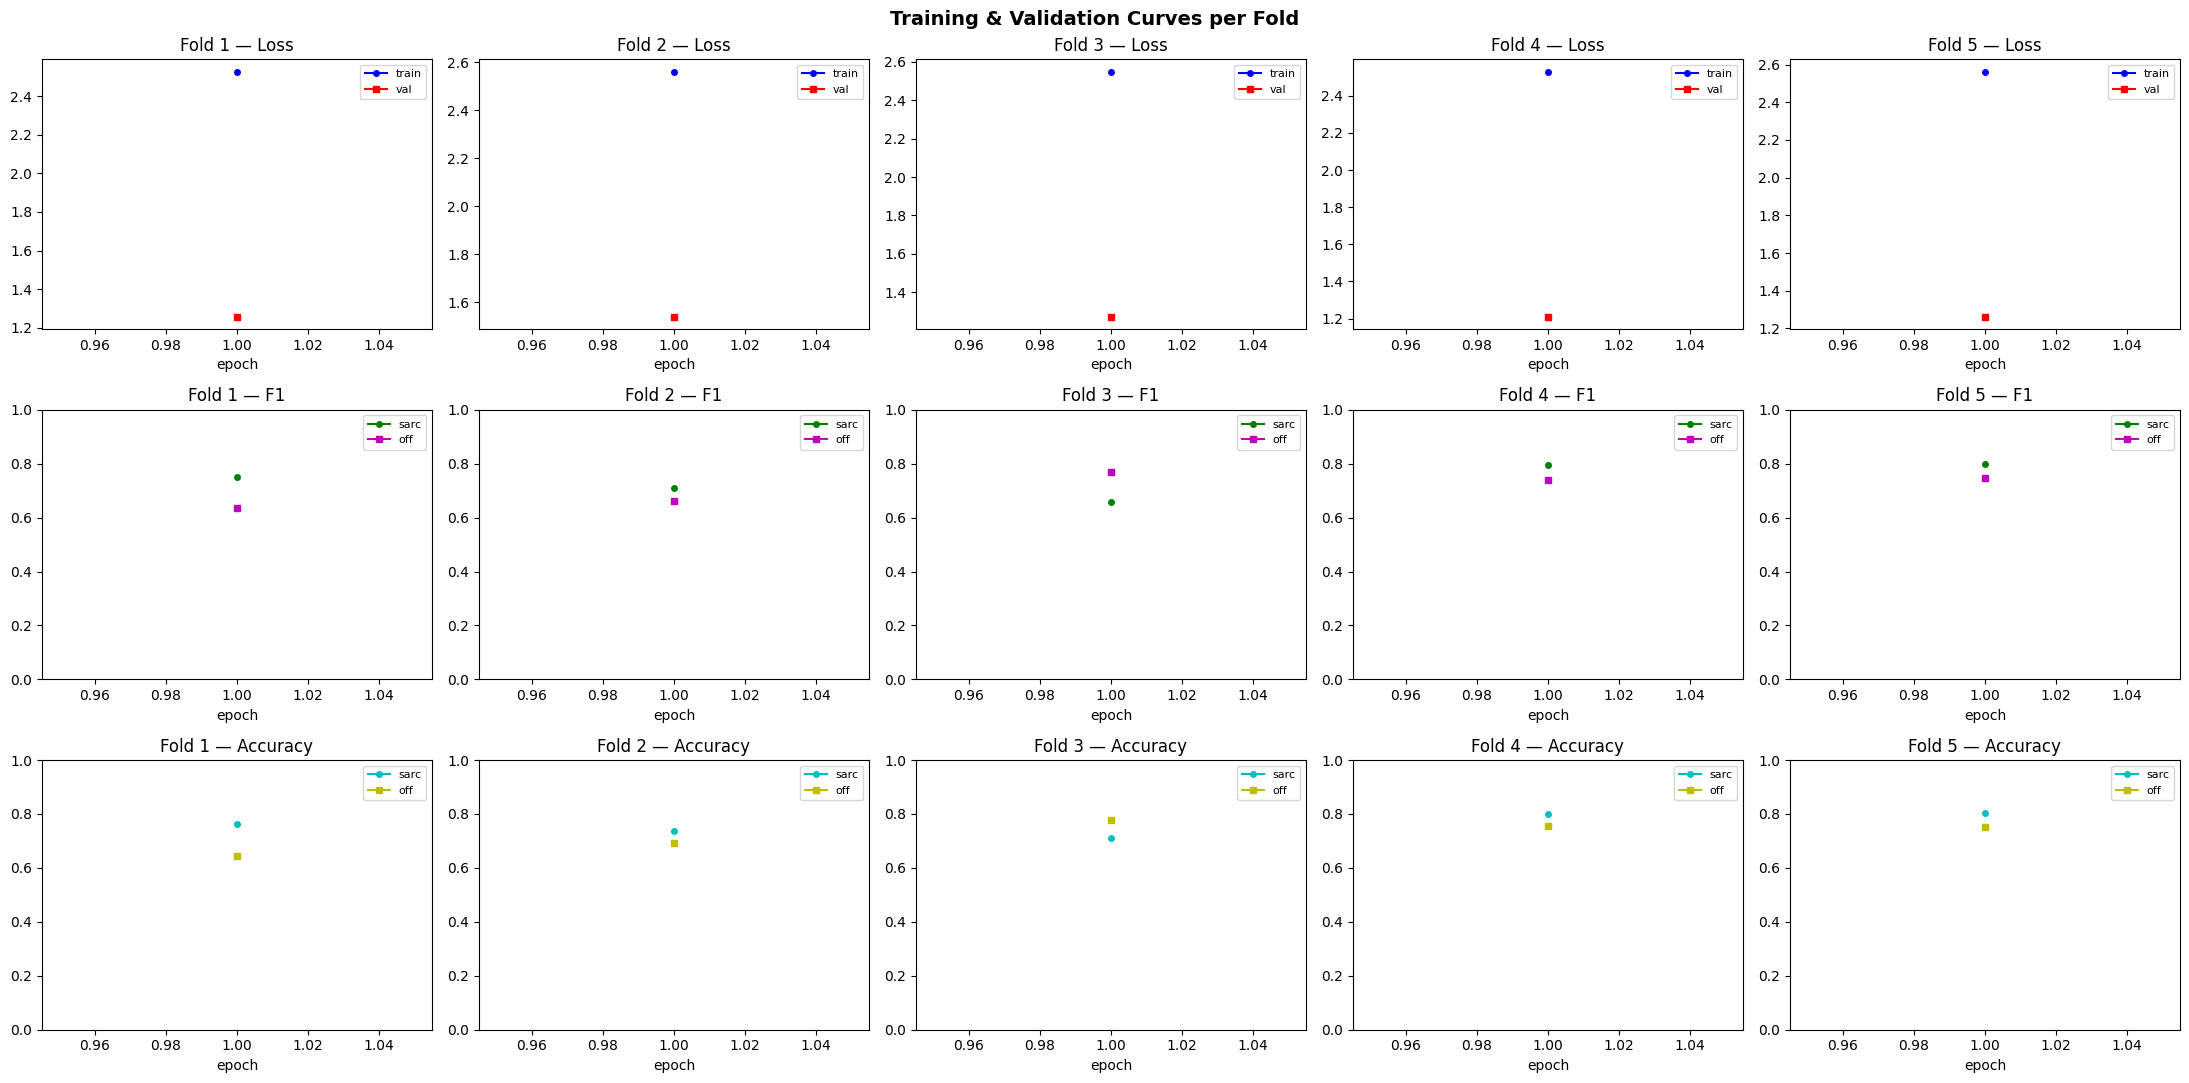

In [67]:
import matplotlib.pyplot as plt, matplotlib
matplotlib.rcParams["font.family"] = "DejaVu Sans"

hist = full_cv["history"]; nF = len(hist)
fig, axes = plt.subplots(3, nF, figsize=(4.4*nF, 11), squeeze=False)
fig.suptitle("Training & Validation Curves per Fold", fontsize=14, fontweight="bold")
for f, h in hist.items():
    ep = range(1, len(h["train_loss"])+1)
    axes[0][f].plot(ep, h["train_loss"], "b-o", ms=4, label="train"); axes[0][f].plot(ep, h["val_loss"], "r-s", ms=4, label="val")
    axes[0][f].set_title(f"Fold {f+1} — Loss"); axes[0][f].legend(fontsize=8); axes[0][f].set_xlabel("epoch")
    axes[1][f].plot(ep, h["sarc_f1"], "g-o", ms=4, label="sarc"); axes[1][f].plot(ep, h["off_f1"], "m-s", ms=4, label="off")
    axes[1][f].set_title(f"Fold {f+1} — F1"); axes[1][f].set_ylim(0,1); axes[1][f].legend(fontsize=8); axes[1][f].set_xlabel("epoch")
    axes[2][f].plot(ep, h["sarc_acc"], "c-o", ms=4, label="sarc"); axes[2][f].plot(ep, h["off_acc"], "y-s", ms=4, label="off")
    axes[2][f].set_title(f"Fold {f+1} — Accuracy"); axes[2][f].set_ylim(0,1); axes[2][f].legend(fontsize=8); axes[2][f].set_xlabel("epoch")
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## Section 13 — Hold-out Evaluation via 5-Fold **Ensemble** (not a single best fold)

The reported model averages the sigmoid probabilities of all five fold models. Each fold
model is paired with **its own fold-fitted intent encoder**, so the ensemble stays
leakage-free: no encoder ever saw the rows it is scoring, and the hold-out split was
carved out before any fitting at all.

Evaluation is reported at two levels. **Per task** we give the full classification report
(precision / recall / F1 per class) plus MCC and AUC. **Jointly**, the two heads are
stacked into a multi-label prediction `[Pred_Sarcasm, Pred_Offensive]` and scored with:

* **Exact Match Ratio** — share of rows where *both* labels are right (the strictest view);
* **Hamming Loss** — per-label error rate;
* **Jaccard (samples / micro / macro)** — label-set overlap averaged per row, pooled over
  all label decisions, and averaged over the two labels respectively;
* **Joint micro-F1 / macro-F1** — pooled and per-label-averaged F1 over the stacked matrix.

The three Jaccard variants and the two F1 averagings are reported together because they
disagree in informative ways under class imbalance: micro is dominated by the frequent
label, macro weights both tasks equally, and samples-average reflects per-post quality.


In [68]:
# Section 13 — Hold-out Evaluation via 5-Fold Ensemble

# --- Try to load checkpoint if full_cv is not in memory ---
REF_SEED = CFG["ABLATION_SEED"]
REF_CHECKPOINT = os.path.join(CFG["RUN_DIR"], f"ref_run_seed{REF_SEED}.pt")

if 'full_cv' not in dir():
    if os.path.exists(REF_CHECKPOINT):
        print(f"Loading reference run checkpoint from {REF_CHECKPOINT}")
        checkpoint = torch.load(REF_CHECKPOINT, map_location="cpu", weights_only=False)
        full_cv = {
            "models": [m.to("cpu") for m in checkpoint["models"]],
            "encoders": checkpoint["encoders"],
            "metrics": checkpoint["metrics"],
            "history": checkpoint["history"],
            "fold_indices": checkpoint["fold_indices"]
        }
        print("Checkpoint loaded successfully.")
    else:
        raise FileNotFoundError(f"No checkpoint found at {REF_CHECKPOINT}. Run Section 12 first.")

# --- Generate ensemble predictions from the reference run's fold models ---
def ensemble_predict_single(models, encoders, raw_texts, max_len=None, batch_size=32, preprocess_fn=None):
    """Mean sigmoid prob across fold models; each uses its own fitted intent encoder."""
    max_len = CFG["MAX_LEN"] if max_len is None else max_len
    pp = preprocess if preprocess_fn is None else preprocess_fn
    exp = [pp(t) for t in raw_texts]
    ps_sum = np.zeros(len(raw_texts)); po_sum = np.zeros(len(raw_texts))
    for m, enc in zip(models, encoders):
        m.to(DEVICE).eval()
        feats = torch.tensor(enc.transform(raw_texts), dtype=torch.float32)
        for i in range(0, len(raw_texts), batch_size):
            chunk = exp[i:i+batch_size]
            t = tokenizer(chunk, max_length=max_len, padding="max_length",
                          truncation=True, return_tensors="pt")
            with torch.no_grad():
                s, o = m(t["input_ids"].to(DEVICE), t["attention_mask"].to(DEVICE),
                         feats[i:i+batch_size].to(DEVICE))
            ps_sum[i:i+batch_size] += torch.sigmoid(s).cpu().numpy()
            po_sum[i:i+batch_size] += torch.sigmoid(o).cpu().numpy()
        m.to("cpu")
    n = len(models)
    return ps_sum/n, po_sum/n

# --- Get test labels ---
sarc_true = df_test.sarcasm.values
off_true = df_test.offensive.values

# --- Generate ensemble predictions ---
sarc_prob, off_prob = ensemble_predict_single(full_cv["models"], full_cv["encoders"], df_test.text.values)
sarc_pred, off_pred = (sarc_prob >= .5).astype(int), (off_prob >= .5).astype(int)

# --- Report function ---
def _report(tag, sp_prob, op_prob, save_csv=None):
    """Per-task classification reports + the full JOINT multi-label block computed on the
    stacked prediction matrix [Pred_Sarcasm, Pred_Offensive]."""
    spd, opd = (sp_prob>=.5).astype(int), (op_prob>=.5).astype(int)
    print("="*62); print(f"  HOLD-OUT TEST — {tag}"); print("="*62)
    print("\n── Sarcasm ──")
    print(classification_report(sarc_true, spd, target_names=["Non-Sarc","Sarc"], digits=4))
    print("── Offensive ──")
    print(classification_report(off_true, opd, target_names=["Non-Off","Off"], digits=4))

    # ---- stacked multi-label view -------------------------------------------------
    yt = np.stack([sarc_true, off_true], 1)      # [N, 2] true  [Sarcasm, Offensive]
    yp = np.stack([spd, opd], 1)                 # [N, 2] pred  [Pred_Sarcasm, Pred_Offensive]

    emr        = float(np.all(yt == yp, axis=1).mean())
    ham        = hamming_loss(yt, yp)
    jac_sam    = jaccard_score(yt, yp, average="samples",  zero_division=0)
    jac_mic    = jaccard_score(yt, yp, average="micro",    zero_division=0)
    jac_mac    = jaccard_score(yt, yp, average="macro",    zero_division=0)
    f1_mic     = f1_score(yt, yp, average="micro", zero_division=0)
    f1_mac     = f1_score(yt, yp, average="macro", zero_division=0)
    sarc_mcc   = matthews_corrcoef(sarc_true, spd); sarc_auc = roc_auc_score(sarc_true, sp_prob)
    off_mcc    = matthews_corrcoef(off_true,  opd); off_auc  = roc_auc_score(off_true,  op_prob)

    print("── Joint multi-label (stacked [Pred_Sarcasm, Pred_Offensive]) ──")
    print(f"  Exact Match Ratio : {emr:.4f}")
    print(f"  Hamming Loss      : {ham:.4f}")
    print(f"  Jaccard (samples) : {jac_sam:.4f}")
    print(f"  Jaccard (micro)   : {jac_mic:.4f}")
    print(f"  Jaccard (macro)   : {jac_mac:.4f}")
    print(f"  Joint micro-F1    : {f1_mic:.4f}")
    print(f"  Joint macro-F1    : {f1_mac:.4f}")
    print(f"  Sarc MCC / AUC    : {sarc_mcc:.4f} / {sarc_auc:.4f}")
    print(f"  Off  MCC / AUC    : {off_mcc:.4f} / {off_auc:.4f}")

    joint_row = {"tag": tag, "exact_match_ratio": emr, "hamming_loss": ham,
                 "jaccard_samples": jac_sam, "jaccard_micro": jac_mic, "jaccard_macro": jac_mac,
                 "joint_micro_f1": f1_mic, "joint_macro_f1": f1_mac,
                 "sarc_mcc": sarc_mcc, "sarc_auc": sarc_auc,
                 "off_mcc": off_mcc, "off_auc": off_auc}
    if save_csv:
        pd.DataFrame([joint_row]).to_csv(os.path.join(CFG["RUN_DIR"], save_csv), index=False)
    return joint_row

holdout_joint = _report("5-FOLD ENSEMBLE (unseen data)", sarc_prob, off_prob,
                        save_csv="holdout_joint_metrics.csv")
print(f"\nSaved joint multi-label metrics -> {os.path.join(CFG['RUN_DIR'], 'holdout_joint_metrics.csv')}")


  HOLD-OUT TEST — 5-FOLD ENSEMBLE (unseen data)

── Sarcasm ──
              precision    recall  f1-score   support

    Non-Sarc     0.8468    0.6105    0.7095       172
        Sarc     0.7528    0.9148    0.8259       223

    accuracy                         0.7823       395
   macro avg     0.7998    0.7626    0.7677       395
weighted avg     0.7937    0.7823    0.7752       395

── Offensive ──
              precision    recall  f1-score   support

     Non-Off     0.6981    0.9069    0.7889       204
         Off     0.8538    0.5812    0.6916       191

    accuracy                         0.7494       395
   macro avg     0.7760    0.7440    0.7403       395
weighted avg     0.7734    0.7494    0.7419       395

── Joint multi-label (stacked [Pred_Sarcasm, Pred_Offensive]) ──
  Exact Match Ratio : 0.6152
  Hamming Loss      : 0.2342
  Jaccard (samples) : 0.6671
  Jaccard (micro)   : 0.6300
  Jaccard (macro)   : 0.6160
  Joint micro-F1    : 0.7730
  Joint macro-F1    : 0.7587

## Section 13b — Confusion Matrices & ROC Curves (hold-out)

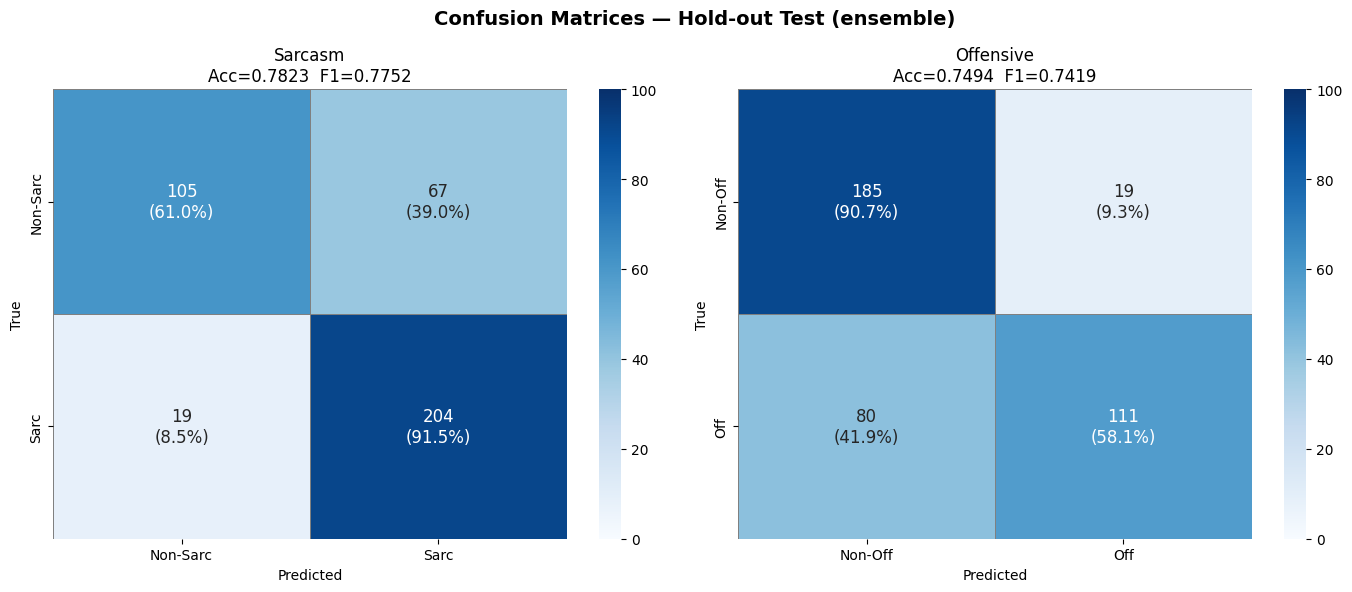

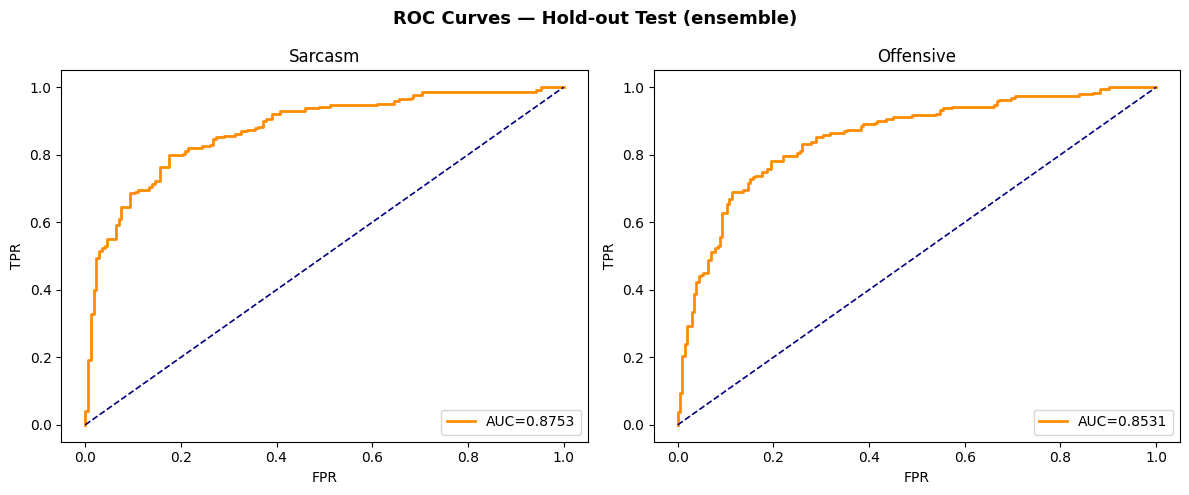

In [69]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Confusion Matrices — Hold-out Test (ensemble)", fontsize=14, fontweight="bold")
for ax, (yt_, yp_, title, labels) in zip(axes, [
        (sarc_true, sarc_pred, "Sarcasm", ["Non-Sarc","Sarc"]),
        (off_true,  off_pred,  "Offensive", ["Non-Off","Off"])]):
    cm = confusion_matrix(yt_, yp_); pct = cm/cm.sum(1, keepdims=True)*100
    annot = np.array([[f"{cm[i,j]}\n({pct[i,j]:.1f}%)" for j in range(2)] for i in range(2)])
    sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", xticklabels=labels, yticklabels=labels,
                ax=ax, vmin=0, vmax=100, linewidths=.5, linecolor="gray", annot_kws={"size":12})
    ax.set_title(f"{title}\nAcc={accuracy_score(yt_,yp_):.4f}  "
                 f"F1={f1_score(yt_,yp_,average='weighted',zero_division=0):.4f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("ROC Curves — Hold-out Test (ensemble)", fontsize=13, fontweight="bold")
for ax, (yt_, pb_, title) in zip(axes, [(sarc_true, sarc_prob, "Sarcasm"),
                                        (off_true, off_prob, "Offensive")]):
    fpr, tpr, _ = roc_curve(yt_, pb_); ax.plot(fpr, tpr, "darkorange", lw=2, label=f"AUC={auc(fpr,tpr):.4f}")
    ax.plot([0,1],[0,1],"navy",ls="--",lw=1.2); ax.set_title(f"{title}"); ax.legend(loc="lower right")
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
plt.tight_layout(); plt.savefig("roc_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## Section 13c — Probability Calibration (reliability, ECE/Brier/NLL, temperature scaling)

A high macro-F1 doesn't guarantee the predicted probabilities are *trustworthy*. Here we
quantify calibration of the deployed 5-fold ensemble on the hold-out test set —
Expected/Maximum Calibration Error (ECE/MCE), Brier score and NLL — and draw reliability
diagrams for both tasks. We then fit a single **temperature** per task on **out-of-fold
train/CV predictions** (leakage-free — the test set is never used to fit T) and report the
post-calibration improvement on test. Calibration is reported for the positive-class
probability P(y=1), the score that thresholding and the ROC curves in 13b actually use.

> **Optimisation-plan note (Task 6).** Post-hoc temperature scaling is *already implemented
> here*, on exactly the out-of-fold predictions the plan specifies, so it is not
> re-implemented later. Section 13e adds the complementary piece — decision-threshold
> tuning. The two do different jobs: temperature scaling is a monotone transform of the
> logit, so it improves calibration but cannot change the ranking or, by itself, the
> operating point; threshold tuning moves the operating point directly.


Fitted temperatures (on OOF train/CV, leakage-free): T_sarc=1.087  T_off=1.126

=== CALIBRATION ON HOLD-OUT TEST (5-fold ensemble) ===

── Sarcasm ──
  raw           : ECE=0.0986 MCE=0.2582 Brier=0.1556 NLL=0.4776
  +temperature  : ECE=0.1119 MCE=0.2694 Brier=0.1570 NLL=0.4828

── Offensive ──
  raw           : ECE=0.1140 MCE=0.2466 Brier=0.1714 NLL=0.5195
  +temperature  : ECE=0.1277 MCE=0.2361 Brier=0.1737 NLL=0.5266


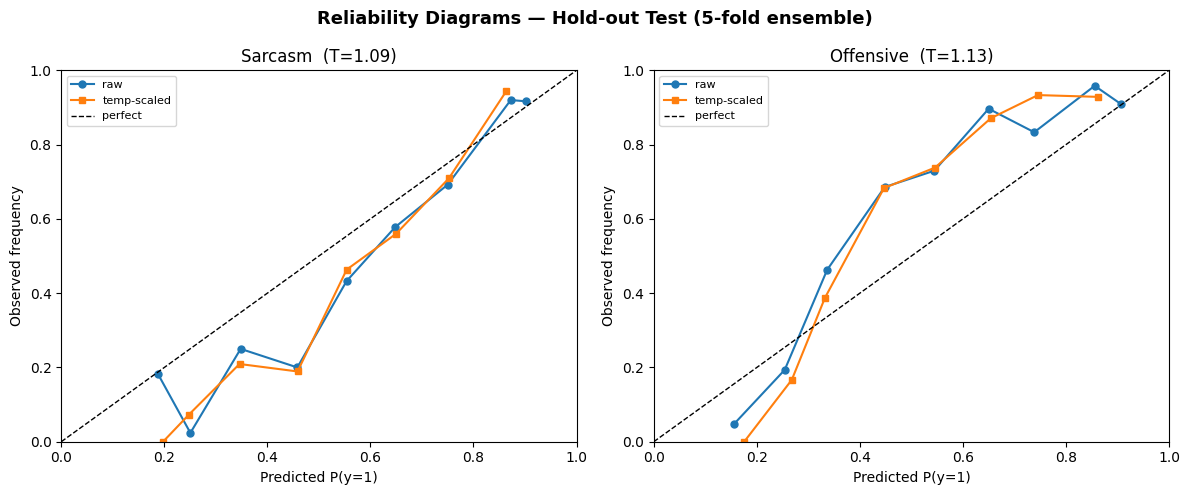

In [70]:
# Section 13c — Probability Calibration (reliability, ECE/Brier/NLL, temperature scaling)

from scipy.optimize import minimize_scalar

# ---- calibration metrics (positive-class P(y=1)) ------------------------------
def calib_bins(y, p, n_bins=10):
    y = np.asarray(y); p = np.asarray(p)
    edges = np.linspace(0, 1, n_bins + 1)
    conf = np.full(n_bins, np.nan); acc = np.full(n_bins, np.nan); wt = np.zeros(n_bins)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    for b in range(n_bins):
        m = idx == b
        if m.any():
            conf[b] = p[m].mean(); acc[b] = y[m].mean(); wt[b] = m.mean()
    return edges, conf, acc, wt

def calib_scores(y, p, n_bins=10):
    _, conf, acc, wt = calib_bins(y, p, n_bins)
    ok = ~np.isnan(conf)
    ece = float(np.sum(wt[ok] * np.abs(acc[ok] - conf[ok])))
    mce = float(np.max(np.abs(acc[ok] - conf[ok]))) if ok.any() else float("nan")
    y = np.asarray(y); pc = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    brier = float(np.mean((pc - y) ** 2))
    nll = float(-np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc)))
    return {"ECE": ece, "MCE": mce, "Brier": brier, "NLL": nll}

# ---- temperature scaling on ensemble probabilities ----------------------------
def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def _apply_T(p, T):
    return 1.0 / (1.0 + np.exp(-_logit(p) / T))

def _fit_T(p_val, y_val):
    z = _logit(p_val)
    def nll(T):
        q = np.clip(1.0 / (1.0 + np.exp(-z / T)), 1e-6, 1 - 1e-6)
        return -np.mean(y_val * np.log(q) + (1 - y_val) * np.log(1 - q))
    return float(minimize_scalar(nll, bounds=(0.05, 10.0), method="bounded").x)

# ---- leakage-free OOF validation probs from the reference fold models ---------
# Each pool example is scored by the fold model for which it was in the VALIDATION
# split -> genuine held-out predictions, no test data used.
oof_sarc = np.full(len(df_trainval), np.nan)
oof_off  = np.full(len(df_trainval), np.nan)
for f, (a, b) in enumerate(full_cv["fold_indices"]):
    ps, po = ensemble_predict_single([full_cv["models"][f]], [full_cv["encoders"][f]],
                                     df_trainval.text.values[b])
    oof_sarc[b] = ps; oof_off[b] = po
y_sarc_tv, y_off_tv = df_trainval.sarcasm.values, df_trainval.offensive.values

T_sarc = _fit_T(oof_sarc, y_sarc_tv)
T_off  = _fit_T(oof_off,  y_off_tv)
print(f"Fitted temperatures (on OOF train/CV, leakage-free): "
      f"T_sarc={T_sarc:.3f}  T_off={T_off:.3f}\n")

# ---- calibrate the test ensemble (same model family as the OOF fit) ----------
sarc_prob_cal = _apply_T(sarc_prob, T_sarc)
off_prob_cal  = _apply_T(off_prob,  T_off)

print("=== CALIBRATION ON HOLD-OUT TEST (5-fold ensemble) ===")
cal_rows = []
for tag, yt, praw, pcal in [("Sarcasm", sarc_true, sarc_prob, sarc_prob_cal),
                            ("Offensive", off_true, off_prob, off_prob_cal)]:
    raw = calib_scores(yt, praw)
    cal = calib_scores(yt, pcal)
    print(f"\n── {tag} ──")
    print(f"  raw           : ECE={raw['ECE']:.4f} MCE={raw['MCE']:.4f} "
          f"Brier={raw['Brier']:.4f} NLL={raw['NLL']:.4f}")
    print(f"  +temperature  : ECE={cal['ECE']:.4f} MCE={cal['MCE']:.4f} "
          f"Brier={cal['Brier']:.4f} NLL={cal['NLL']:.4f}")
    cal_rows += [{"task": tag, "variant": "raw",  **raw},
                 {"task": tag, "variant": "temp", **cal}]

calib_df = pd.DataFrame(cal_rows)
calib_df.to_csv(os.path.join(CFG["RUN_DIR"], "calibration.csv"), index=False)

# ---- reliability diagrams (raw vs temperature-scaled) -------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Reliability Diagrams — Hold-out Test (5-fold ensemble)", fontsize=13, fontweight="bold")
for ax, (tag, yt, praw, pcal) in zip(axes, [("Sarcasm", sarc_true, sarc_prob, sarc_prob_cal),
                                            ("Offensive", off_true, off_prob, off_prob_cal)]):
    for p, lab, style in [(praw, "raw", "o-"), (pcal, "temp-scaled", "s-")]:
        _, conf, acc, _ = calib_bins(yt, p, 10); ok = ~np.isnan(conf)
        ax.plot(conf[ok], acc[ok], style, ms=5, label=lab)
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
    ax.set_title(f"{tag}  (T={T_sarc if tag=='Sarcasm' else T_off:.2f})")
    ax.set_xlabel("Predicted P(y=1)"); ax.set_ylabel("Observed frequency")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("calibration_reliability.png", dpi=150, bbox_inches="tight"); plt.show()


## Section 13d — Robustness to Input Perturbations

We probe how stable the model is under realistic, mostly meaning-preserving perturbations
of the hold-out inputs, all evaluated with the 5-fold ensemble on identical labels:

* **emoji_drop** — all emojis removed (text *and* intent vector lose the signal): expected
  degradation, quantifying how much the model relies on emojis (ties to the core thesis).
* **emoji_swap_in** — one emoji swapped for a sibling in the *same* intent cluster
  (meaning-preserving): predictions should be **stable** (low flip-rate, small ΔF1).
* **emoji_swap_cross** — one emoji swapped for a *different*-cluster emoji (distractor):
  measures spurious sensitivity.
* **emoji_repeat** — existing emojis tripled (🤣→🤣🤣🤣): intensity robustness.
* **char_typo** — character-level noise on Bangla text with emojis preserved: text robustness.

For each we report macro-F1 per task, Δ vs clean, and the **prediction flip-rate** (share of
examples whose predicted label changed vs clean), overall and on emoji-bearing rows. All
perturbations are seeded for reproducibility.


=== ROBUSTNESS TO INPUT PERTURBATIONS (5-fold ensemble, hold-out) ===
    perturbation  sarc_macroF1  off_macroF1   Δsarc    Δoff  flip%_all  flip%_emoji_rows
           clean        0.7677       0.7403  0.0000  0.0000     0.0000            0.0000
      emoji_drop        0.5700       0.5965 -0.1977 -0.1438    50.8861           51.5385
   emoji_swap_in        0.6860       0.7150 -0.0817 -0.0253    16.9620           17.1795
emoji_swap_cross        0.5611       0.5413 -0.2066 -0.1989    35.1899           35.6410
 emoji_repeat_x3        0.5030       0.4118 -0.2647 -0.3284    34.4304           34.8718
       char_typo        0.7718       0.7316  0.0041 -0.0087     3.0380            3.0769


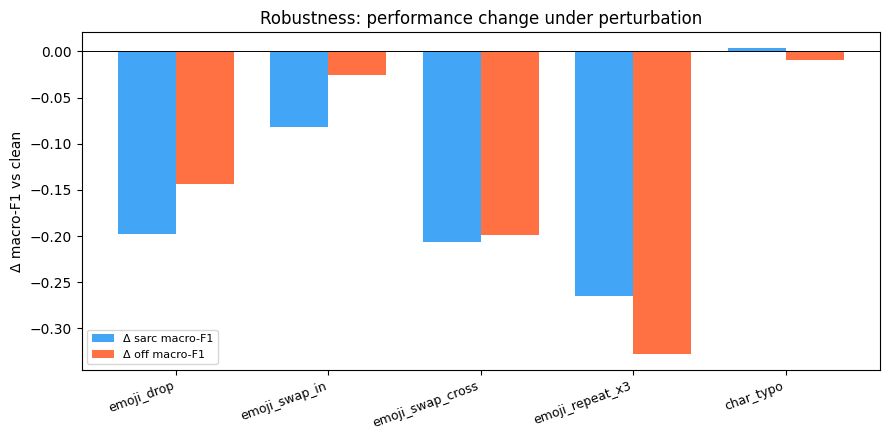


Reading the table: emoji_drop should show the LARGEST drop (model uses emoji signal);
emoji_swap_in / char_typo should show SMALL ΔF1 + low flip-rate (meaning-preserving → robust);
emoji_swap_cross probes spurious sensitivity to a distractor emoji.


In [71]:
# Section 13d — Robustness to Input Perturbations

rob_rng = random.Random(SEED)

def perturb_emoji_drop(t):   return strip_emojis(t)
def perturb_emoji_swap_in(t): return augment_emoji_substitution(t, p=1.0, rng=rob_rng)  # in-cluster

def perturb_emoji_swap_cross(t):
    chars = list(str(t)); pos = [i for i, c in enumerate(chars) if c in EMOJI_TO_CLUSTER]
    if not pos: return t
    i = rob_rng.choice(pos); cur = chars[i]
    same = set(next((cl for cl in CLUSTERS if cur in cl), []))
    other = [c for cl in CLUSTERS for c in cl if c not in same]
    if other: chars[i] = rob_rng.choice(other)
    return "".join(chars)

def perturb_emoji_repeat(t, k=3):
    return "".join(c * (k if c in emojilib.EMOJI_DATA else 1) for c in str(t))

def perturb_typo(t, p=0.08):
    out = []
    for c in str(t):
        if c in emojilib.EMOJI_DATA: out.append(c); continue
        r = rob_rng.random()
        if r < p * 0.5:      continue                 # drop char
        elif r < p:          out.append(c); out.append(c)   # duplicate char
        else:                out.append(c)
    return "".join(out)

def eval_perturbation(texts):
    # Use ensemble_predict_single (defined in Section 13) instead of ensemble_predict
    ps, po = ensemble_predict_single(full_cv["models"], full_cv["encoders"], list(texts))
    return {"sarc_pred": (ps >= .5).astype(int), "off_pred": (po >= .5).astype(int),
            "sarc_f1": f1_score(sarc_true, (ps >= .5).astype(int), average="macro", zero_division=0),
            "off_f1":  f1_score(off_true,  (po >= .5).astype(int), average="macro", zero_division=0)}

clean_texts = list(df_test.text.values)
has_emoji   = np.array([len(extract_emojis(t)) > 0 for t in clean_texts])
base        = eval_perturbation(clean_texts)
base_sp, base_op = base["sarc_pred"], base["off_pred"]

PERTS = [("emoji_drop",        [perturb_emoji_drop(t)       for t in clean_texts]),
         ("emoji_swap_in",     [perturb_emoji_swap_in(t)    for t in clean_texts]),
         ("emoji_swap_cross",  [perturb_emoji_swap_cross(t) for t in clean_texts]),
         ("emoji_repeat_x3",   [perturb_emoji_repeat(t)     for t in clean_texts]),
         ("char_typo",         [perturb_typo(t)             for t in clean_texts])]

rows = [{"perturbation": "clean", "sarc_macroF1": base["sarc_f1"], "off_macroF1": base["off_f1"],
         "Δsarc": 0.0, "Δoff": 0.0, "flip%_all": 0.0, "flip%_emoji_rows": 0.0}]
for name, texts in PERTS:
    r = eval_perturbation(texts)
    changed = (r["sarc_pred"] != base_sp) | (r["off_pred"] != base_op)
    flip_all = changed.mean() * 100
    flip_em  = changed[has_emoji].mean() * 100 if has_emoji.any() else float("nan")
    rows.append({"perturbation": name, "sarc_macroF1": r["sarc_f1"], "off_macroF1": r["off_f1"],
                 "Δsarc": r["sarc_f1"] - base["sarc_f1"], "Δoff": r["off_f1"] - base["off_f1"],
                 "flip%_all": flip_all, "flip%_emoji_rows": flip_em})

rob_df = pd.DataFrame(rows)
print("=== ROBUSTNESS TO INPUT PERTURBATIONS (5-fold ensemble, hold-out) ===")
print(rob_df.round(4).to_string(index=False))
rob_df.to_csv(os.path.join(CFG["RUN_DIR"], "robustness.csv"), index=False)

# ---- ΔF1 bar plot -------------------------------------------------------------
plot_df = rob_df[rob_df.perturbation != "clean"]
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(plot_df)); w = 0.38
ax.bar(x - w/2, plot_df["Δsarc"], w, label="Δ sarc macro-F1", color="#42a5f5")
ax.bar(x + w/2, plot_df["Δoff"],  w, label="Δ off macro-F1",  color="#ff7043")
ax.axhline(0, color="k", lw=.7)
ax.set_xticks(x); ax.set_xticklabels(plot_df["perturbation"], rotation=20, ha="right", fontsize=9)
ax.set_ylabel("Δ macro-F1 vs clean"); ax.set_title("Robustness: performance change under perturbation")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("robustness_delta_f1.png", dpi=150, bbox_inches="tight"); plt.show()

print("\nReading the table: emoji_drop should show the LARGEST drop (model uses emoji signal);")
print("emoji_swap_in / char_typo should show SMALL ΔF1 + low flip-rate (meaning-preserving → robust);")
print("emoji_swap_cross probes spurious sensitivity to a distractor emoji.")

## Section 13e — Post-hoc Decision-Threshold Tuning on Out-of-Fold Predictions (Task 3a/3d)

The two heads are trained with `BCEWithLogitsLoss` and read out at a default cut-off of
0.5, but 0.5 is only optimal when the operating cost is symmetric and the predicted
probabilities are perfectly calibrated. Neither holds here: the offensive task is the
weaker of the two and its errors concentrate in the `Sarc+Abuse` region, so shifting the
cut-off can recover recall on that class at almost no precision cost. This is a **zero-cost
improvement — no retraining, no change to the loss.**

**Where the threshold is fitted matters.** It is grid-searched on the **out-of-fold
validation predictions** (`oof_sarc`, `oof_off`) produced by `run_cv()` — every row scored
by the fold model that did *not* train on it. The hold-out test set is never used to select
the threshold, so the reported test metric stays honest. Grid:
`[0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]`, objective: macro-F1.

**On fairness of downstream comparisons.** The tuned thresholds are applied to the reported
test operating point and to `predict_text()` (deployment). They are deliberately **not**
written back into `sarc_pred` / `off_pred`, which stay at 0.5 — those arrays feed the
Full-vs-ablation McNemar tests in Section 19 and the cross-model error overlap in Section
17, and tuning one arm while leaving the other at 0.5 would manufacture an advantage that
has nothing to do with the component under test. Both operating points are reported side by
side below.

**Task 6 (temperature scaling) is not re-implemented here** — Section 13c already fits a
per-task temperature on the same out-of-fold predictions and reports ECE/MCE/Brier/NLL
before and after. Adding a second calibration pass would be redundant. Note that
temperature scaling is monotone in the logit, so it cannot by itself change the *ranking* of
predictions; threshold tuning is what moves the operating point, and the two are
complementary rather than substitutes.


In [72]:
# ==============================================================================
# Section 13e — decision-threshold tuning on OOF predictions (Task 3a/3d)
# ==============================================================================
GRID = CFG["THRESHOLD_GRID"]

def tune_threshold(y_true, y_prob, grid=None, objective="macro_f1"):
    """Grid-search the decision threshold that maximises macro-F1 on OOF predictions."""
    grid = GRID if grid is None else grid
    rows = []
    for t in grid:
        yp = (np.asarray(y_prob) >= t).astype(int)
        rows.append({"threshold": t,
                     "macro_f1": f1_score(y_true, yp, average="macro", zero_division=0),
                     "pos_f1":   f1_score(y_true, yp, pos_label=1,     zero_division=0),
                     "accuracy": accuracy_score(y_true, yp)})
    tab = pd.DataFrame(rows)
    best = tab.loc[tab[objective].idxmax()]
    return float(best["threshold"]), tab

# ---- OOF probabilities: prefer run_cv()'s, fall back to Section 13c's ---------
if "full_cv" in dir() and full_cv.get("oof_sarc") is not None and not np.all(np.isnan(full_cv["oof_sarc"])):
    _oof_s, _oof_o = full_cv["oof_sarc"], full_cv["oof_off"]
    _src = "run_cv() out-of-fold predictions"
else:
    _oof_s, _oof_o = oof_sarc, oof_off            # computed in Section 13c
    _src = "Section 13c out-of-fold predictions"
_mask = ~np.isnan(_oof_s) & ~np.isnan(_oof_o)
_y_s_tv, _y_o_tv = df_trainval.sarcasm.values[_mask], df_trainval.offensive.values[_mask]
print(f"Tuning thresholds on {_src} | n={_mask.sum()} rows (test set untouched)\n")

TUNED_THRESHOLDS = {"sarcasm": 0.5, "offensive": 0.5}
_thr_tables = {}
for _task, _yt, _yp in [("offensive", _y_o_tv, _oof_o[_mask]),   # primary target
                        ("sarcasm",   _y_s_tv, _oof_s[_mask])]:
    _t, _tab = tune_threshold(_yt, _yp)
    _thr_tables[_task] = _tab
    _base = _tab.loc[_tab.threshold == 0.50, "macro_f1"].iloc[0]
    _best = _tab.macro_f1.max()
    if CFG["TUNE_THRESHOLDS"]:
        TUNED_THRESHOLDS[_task] = _t
    print(f"── {_task.upper()} ──")
    print(_tab.round(4).to_string(index=False))
    print(f"  best threshold = {_t:.2f} | OOF macro-F1 {_base:.4f} -> {_best:.4f} "
          f"({(_best-_base)*100:+.2f} pts)\n")

print(f"TUNED_THRESHOLDS = {TUNED_THRESHOLDS}")
pd.concat([t.assign(task=k) for k, t in _thr_tables.items()]).to_csv(
    os.path.join(CFG["RUN_DIR"], "threshold_tuning_oof.csv"), index=False)

# ---- apply to the hold-out test set and compare operating points --------------
sarc_pred_t = (sarc_prob >= TUNED_THRESHOLDS["sarcasm"]).astype(int)
off_pred_t  = (off_prob  >= TUNED_THRESHOLDS["offensive"]).astype(int)

_op_rows = []
for _tag, _sp, _op in [("default (0.50 / 0.50)", sarc_pred, off_pred),
                       (f"tuned ({TUNED_THRESHOLDS['sarcasm']:.2f} / "
                        f"{TUNED_THRESHOLDS['offensive']:.2f})", sarc_pred_t, off_pred_t)]:
    _yt = np.stack([sarc_true, off_true], 1); _yp = np.stack([_sp, _op], 1)
    _op_rows.append({
        "operating point": _tag,
        "sarc_macroF1": f1_score(sarc_true, _sp, average="macro", zero_division=0),
        "off_macroF1":  f1_score(off_true,  _op, average="macro", zero_division=0),
        "off_posF1":    f1_score(off_true,  _op, pos_label=1,     zero_division=0),
        "off_acc":      accuracy_score(off_true, _op),
        "exact_match":  float(np.all(_yt == _yp, axis=1).mean()),
        "hamming(↓)":   hamming_loss(_yt, _yp)})
threshold_compare_df = pd.DataFrame(_op_rows)

print("\n" + "="*78)
print("  HOLD-OUT TEST — DEFAULT vs TUNED OPERATING POINT (thresholds fitted on OOF only)")
print("="*78)
print(threshold_compare_df.round(4).to_string(index=False))
_d = threshold_compare_df.off_macroF1.iloc[1] - threshold_compare_df.off_macroF1.iloc[0]
_ds = threshold_compare_df.sarc_macroF1.iloc[1] - threshold_compare_df.sarc_macroF1.iloc[0]
print(f"\n  Δ offensive macro-F1 = {_d:+.4f} ({_d*100:+.2f} pts) | "
      f"Δ sarcasm macro-F1 = {_ds:+.4f} ({_ds*100:+.2f} pts)")
threshold_compare_df.to_csv(os.path.join(CFG["RUN_DIR"], "threshold_operating_points.csv"), index=False)

# per-class detail at the tuned operating point
print("\n── Offensive @ tuned threshold ──")
print(classification_report(off_true, off_pred_t, target_names=["Non-Off","Off"], digits=4))
print("NOTE: sarc_pred / off_pred remain at 0.50 so the Section 16/19 ablation comparisons")
print("      stay paired at a common operating point. sarc_pred_t / off_pred_t carry the")
print("      tuned decisions and are what predict_text() deploys.")


Tuning thresholds on Section 13c out-of-fold predictions | n=2238 rows (test set untouched)

── OFFENSIVE ──
 threshold  macro_f1  pos_f1  accuracy
      0.30    0.7040  0.7122    0.7042
      0.35    0.7157  0.7112    0.7158
      0.40    0.7118  0.6960    0.7127
      0.45    0.7185  0.6935    0.7207
      0.50    0.7194  0.6808    0.7248
      0.55    0.7233  0.6685    0.7341
      0.60    0.7096  0.6359    0.7283
      0.65    0.6801  0.5868    0.7073
  best threshold = 0.55 | OOF macro-F1 0.7194 -> 0.7233 (+0.39 pts)

── SARCASM ──
 threshold  macro_f1  pos_f1  accuracy
      0.30    0.6576  0.7839    0.7042
      0.35    0.6887  0.7933    0.7239
      0.40    0.7135  0.7990    0.7391
      0.45    0.7302  0.8037    0.7502
      0.50    0.7475  0.8086    0.7623
      0.55    0.7597  0.8102    0.7703
      0.60    0.7669  0.8085    0.7744
      0.65    0.7701  0.8013    0.7744
  best threshold = 0.65 | OOF macro-F1 0.7475 -> 0.7701 (+2.27 pts)

TUNED_THRESHOLDS = {'sarcasm': 0.65, 

## Section 14 — Explainability: LIME on the Model's Real (Preprocessed) Input

LIME is run on the **preprocessed** text — the exact emoji-expanded string the model
consumes — so attributions reflect the deployed pipeline. Each emoji phrase is kept as
**one atomic token** (via a NUL-joined surrogate encoding), and the emoji-intent vector is
**held fixed** during perturbation so the explanation isolates the *text-encoder* pathway
where emoji tokens live.

*Reviewer Q&A — "Why preprocessed, not raw?"* Explaining raw text would attribute a
transformation the model never sees; explaining the true input is faithful to what is
actually classified.

**Section 14a** (below) shows per-token attributions for one representative emoji-bearing
example. **Section 14b** then aggregates the same measurement over **every** emoji-bearing
row of the hold-out set and tests the population-level hypothesis. The aggregate arrays
computed in 14b are cached and reused by Section 19, so LIME is executed **once** for the
whole notebook.

**Performance note.** The forward pass used inside LIME keeps all fold models **resident on
the device** for the duration of a batch of explanations, chunks each perturbation set into
`CFG["LIME_INFER_BATCH"]` rows, pads dynamically rather than to `MAX_LEN`, and runs under
`torch.inference_mode()` with optional fp16 autocast. The earlier implementation moved every
fold model host↔device on *each* `predict_fn` call and pushed all `LIME_SAMPLES` rows through
in one full-length batch — with five folds, two tasks and hundreds of examples that is what
made Section 19 appear to hang.


In [73]:
from lime.lime_text import LimeTextExplainer
from contextlib import contextmanager

# Stable explainer encoder: fit on the full train/CV pool only (never on test labels).
explain_encoder = EmojiIntentEncoder().fit(
    df_trainval.text.values, df_trainval.sarcasm.values, df_trainval.offensive.values)

# Backwards-safe defaults if this notebook is run against an older Section 0.
CFG.setdefault("LIME_INFER_BATCH", 64)
CFG.setdefault("LIME_AUTOCAST", True)

# --- LIME operates on PREPROCESSED text (the exact format the model was trained on) ---
# Emoji phrases are multi-word (e.g. "[ব্যঙ্গাত্মক হাসি]").  To keep each phrase a single,
# perturbable LIME token, internal spaces are swapped for NUL ("\x00") to form a
# "surrogate" string; the predict_fn restores them before tokenising for the model.
def _units(exp_text):
    """Split preprocessed text into units; bracketed emoji phrases stay atomic."""
    toks, units, buf = exp_text.split(" "), [], []
    for t in toks:
        if buf:
            buf.append(t)
            if t.endswith("]"): units.append(" ".join(buf)); buf = []
        elif t.startswith("[") and not t.endswith("]"):
            buf = [t]
        else:
            units.append(t)
    if buf: units.append(" ".join(buf))
    return [u for u in units if u]

def to_surrogate(exp_text):
    return " ".join(u.replace(" ", "\x00") for u in _units(exp_text))

def is_emoji_token(tok):
    """Emoji-phrase tokens are the bracketed units produced by expand_emojis()."""
    return tok.strip().startswith("[")

# ------------------------------------------------------------------------------
# Device residency: the single most important performance fix.
# ------------------------------------------------------------------------------
@contextmanager
def lime_models_resident(models):
    """Keep the fold models on DEVICE for a whole BATCH of explanations.

    The previous predict_fn did `m.to(DEVICE) ... m.to("cpu")` on every call, i.e. two
    full transfers of a ~110M-parameter BanglaBERT per fold per LIME explanation. Over
    hundreds of examples x 2 tasks x 5 folds that transfer traffic dominated runtime and
    is what surfaced as the KeyboardInterrupt (a hang) in Section 19."""
    try:
        for m in models: m.to(DEVICE).eval()
        yield models
    finally:
        for m in models: m.to("cpu")
        if torch.cuda.is_available(): torch.cuda.empty_cache()

def make_lime_predict_fn_pre(models, intent_vec, task="sarcasm", batch_size=None):
    """LIME predict_fn over surrogate (preprocessed) strings. Intent vector is held
    FIXED at the original example's value (it cannot be re-derived once emojis are
    perturbed), so LIME attributes the TEXT-ENCODER pathway — exactly where the
    emoji-phrase tokens live.

    Efficiency: chunked batches, dynamic padding, inference_mode, optional fp16 autocast.
    Models are assumed to already be on DEVICE (see `lime_models_resident`); if not, they
    are moved once on first use rather than on every call."""
    feat0 = torch.tensor(np.asarray(intent_vec, dtype=np.float32))      # [1, 10]
    bs      = CFG["LIME_INFER_BATCH"] if batch_size is None else batch_size
    use_amp = bool(CFG.get("LIME_AUTOCAST", True)) and torch.cuda.is_available()

    def predict_fn(surrogate_texts):
        real = [s.replace("\x00", " ") for s in surrogate_texts]
        prob = np.zeros(len(real), dtype=np.float64)
        for i in range(0, len(real), bs):
            chunk = real[i:i+bs]
            enc = tokenizer(chunk, max_length=CFG["MAX_LEN"], padding=True,   # dynamic pad
                            truncation=True, return_tensors="pt")
            ids   = enc["input_ids"].to(DEVICE)
            msk   = enc["attention_mask"].to(DEVICE)
            feats = feat0.to(DEVICE).repeat(len(chunk), 1)
            acc = np.zeros(len(chunk), dtype=np.float64)
            for m in models:
                if next(m.parameters()).device != ids.device:
                    m.to(DEVICE)
                m.eval()
                with torch.inference_mode():
                    if use_amp:
                        with torch.autocast("cuda", dtype=torch.float16):
                            s, o = m(ids, msk, feats)
                    else:
                        s, o = m(ids, msk, feats)
                acc += torch.sigmoid((s if task == "sarcasm" else o).float()).cpu().numpy()
            prob[i:i+bs] = acc / len(models)
        return np.c_[1-prob, prob]
    return predict_fn

# ------------------------------------------------------------------------------
# Version-robust LIME explainer construction  ** ROOT CAUSE OF THE 0.0000 BUG **
# ------------------------------------------------------------------------------
# lime's own tokeniser decides what a "feature" is. Its DEFAULT split regex is r"\W+",
# which is catastrophic for Bangla: Unicode combining marks (matras) are not \w, so
# "ব্যঙ্গাত্মক" is shredded into single graphemes and a bracketed emoji phrase can never
# survive as one token. When that happens `is_emoji_token()` never fires, the emoji
# feature list comes back EMPTY, and the emoji contribution prints as exactly 0.0000 —
# which is precisely the artefact the old Section 14b reported.
#
# The previous code tried to force whitespace splitting via a `split_expr` kwarg/attribute,
# but the installed lime build names it **`split_expression`** — so the setting was
# silently ignored. We now set BOTH spellings, at construction time and on the instance,
# and then SELF-TEST that a bracketed phrase really does survive tokenisation.
_LIME_SPLIT = r"\s+"          # NUL-joined emoji phrases stay atomic (NUL is not \s)

def _make_lime_text_explainer(class_names, split_regex=_LIME_SPLIT):
    import inspect
    _params = inspect.signature(LimeTextExplainer.__init__).parameters
    _kwargs = {"class_names": class_names}
    for _n in ("split_expression", "split_expr"):
        if _n in _params: _kwargs[_n] = split_regex
    if "bow" in _params: _kwargs["bow"] = True
    _explainer = LimeTextExplainer(**_kwargs)
    for _n in ("split_expression", "split_expr"):   # explain_instance reads these off self
        setattr(_explainer, _n, split_regex)
    _explainer.bow        = True
    _explainer.char_level = False
    return _explainer

def _lime_tokenizer_selftest(verbose=True):
    """Verify that a bracketed emoji phrase survives lime's tokenisation as ONE feature.
    Returns True if the surrogate encoding + split regex are working end to end."""
    from lime.lime_text import IndexedString
    probe_raw = "ভালো কাজ [ব্যঙ্গাত্মক হাসি] ছিল"
    probe     = to_surrogate(probe_raw)
    ex        = _make_lime_text_explainer(["a", "b"])
    split     = getattr(ex, "split_expression", getattr(ex, "split_expr", None))
    try:
        idx = IndexedString(probe, bow=True, split_expression=split)
    except TypeError:
        idx = IndexedString(probe, bow=True, split_expr=split)
    words   = [w.replace("\x00", " ") for w in idx.as_list]
    n_emoji = sum(1 for w in words if is_emoji_token(w))
    ok      = n_emoji == 1
    if verbose:
        print(f"LIME tokeniser self-test: split={split!r} | tokens={words} | "
              f"emoji-phrase tokens={n_emoji} -> {'OK' if ok else 'FAILED'}")
        if not ok:
            warnings.warn(
                "LIME is NOT keeping emoji phrases atomic. Emoji attributions will read as "
                "0.0000 regardless of the model. Check the installed lime version's "
                "split-regex parameter name.")
    return ok

def _explain_one(raw_text, task, class_names, models, num_samples, num_features):
    exp_text  = preprocess(raw_text)
    surrogate = to_surrogate(exp_text)
    ivec      = explain_encoder.transform([raw_text])
    fn        = make_lime_predict_fn_pre(models, ivec, task=task)
    explainer = _make_lime_text_explainer(class_names)
    return explainer.explain_instance(surrogate, fn, num_features=num_features,
                                      num_samples=num_samples, labels=[1])

def lime_explain_pre(raw_text, task, class_names, models=None, num_samples=None,
                     num_features=15, models_resident=False):
    """Explain ONE example. Pass `models_resident=True` when calling inside a
    `with lime_models_resident(...)` block (batch loops) to avoid re-transferring
    weights for every example."""
    models = full_cv["models"] if models is None else models
    num_samples = CFG["LIME_SAMPLES"] if num_samples is None else num_samples
    if models_resident:
        return _explain_one(raw_text, task, class_names, models, num_samples, num_features)
    with lime_models_resident(models):
        return _explain_one(raw_text, task, class_names, models, num_samples, num_features)

def lime_features(exp):
    """Return [(readable_token, weight)] with NUL restored to space."""
    return [(feat.replace("\x00", " "), w) for feat, w in exp.as_list(label=1)]

_LIME_TOKENIZER_OK = _lime_tokenizer_selftest()

# choose an example WITH emojis from the test set
cand = [i for i in range(len(df_test)) if extract_emojis(df_test.text.iloc[i])]
sidx = cand[0]
raw_example = df_test.text.iloc[sidx]
print(f"Emoji-bearing hold-out rows: {len(cand)} / {len(df_test)}")
print(f"Explaining: {raw_example}")
print(f"  preprocessed: {preprocess(raw_example)}")
print(f"  truth: Sarcasm={sarc_true[sidx]}, Offensive={off_true[sidx]}")


LIME tokeniser self-test: split='\\s+' | tokens=['ভালো', ' ', 'কাজ', ' ', '[ব্যঙ্গাত্মক হাসি]', ' ', 'ছিল'] | emoji-phrase tokens=1 -> OK
Emoji-bearing hold-out rows: 390 / 395
Explaining: এই চেহারা নিয়ে চান্স পেল কিভাবে 🙄🙄
  preprocessed: এই চেহারা নিয়ে চান্স পেল কিভাবে [চোখ ঘোরানো] [চোখ ঘোরানো]
  truth: Sarcasm=0, Offensive=1



LIME (14a, single example) — sarcasm:
  😀 [চোখ ঘোরানো]                 +0.2267
  🔤 এই                           -0.0356
  🔤 নিয়ে                        -0.0180
  🔤 কিভাবে                       -0.0143
  🔤 পেল                          +0.0109
  🔤 চান্স                        +0.0088
  🔤 চেহারা                       +0.0059


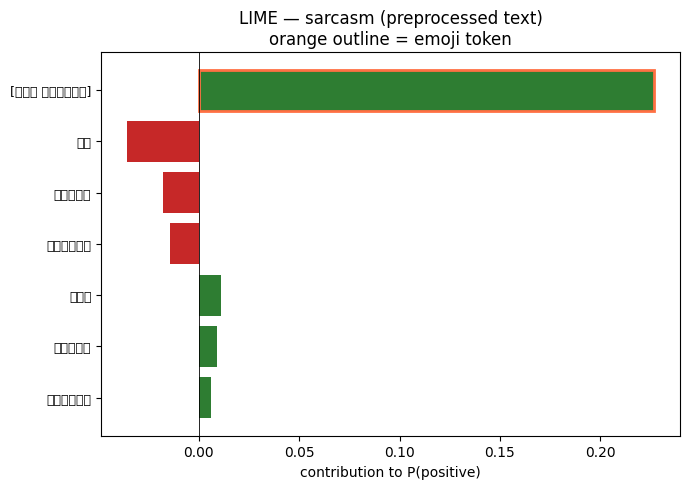


LIME (14a, single example) — offensive:
  😀 [চোখ ঘোরানো]                 -0.3033
  🔤 কিভাবে                       +0.0690
  🔤 এই                           +0.0426
  🔤 নিয়ে                        +0.0314
  🔤 চেহারা                       -0.0093
  🔤 পেল                          -0.0049
  🔤 চান্স                        -0.0048


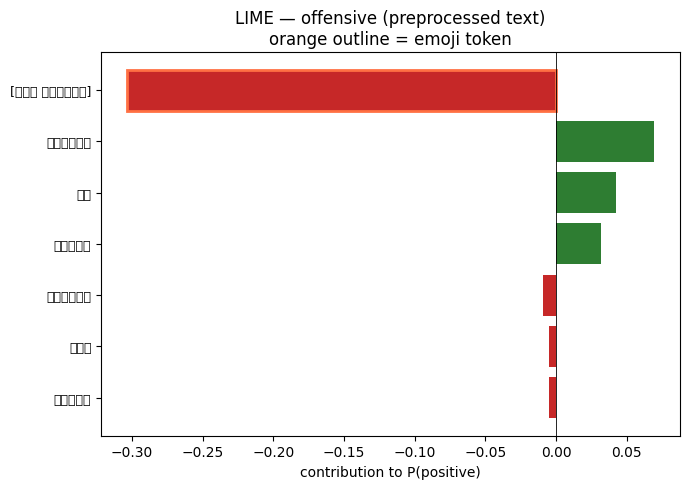

In [74]:
for task, names, png in [("sarcasm", ["Non-Sarc","Sarc"], "lime_sarcasm.png"),
                         ("offensive", ["Non-Off","Off"], "lime_offensive.png")]:
    exp = lime_explain_pre(raw_example, task, names)
    feats = lime_features(exp)
    print(f"\nLIME (14a, single example) — {task}:")
    for feat, w in feats:
        print(f"  {'😀' if is_emoji_token(feat) else '🔤'} {feat:<28} {w:+.4f}")
    # readable horizontal bar (green=+, red=-), emoji tokens outlined
    labels = [f for f, _ in feats][::-1]; vals = [w for _, w in feats][::-1]
    colors = ["#2e7d32" if w >= 0 else "#c62828" for w in vals]
    edges  = ["#ff7043" if is_emoji_token(f) else "none" for f in labels]
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(range(len(vals)), vals, color=colors, edgecolor=edges, linewidth=2)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=9)
    ax.axvline(0, color="k", lw=.6); ax.set_title(f"LIME — {task} (preprocessed text)\norange outline = emoji token")
    ax.set_xlabel("contribution to P(positive)")
    plt.tight_layout(); plt.savefig(png, dpi=150, bbox_inches="tight"); plt.show()

## Section 14b — Emoji vs Word Contribution (**aggregate over all emoji-bearing test examples**)

The previous version of this subsection inspected a **single** example, and for that one
post the emoji contribution printed as `0.0000`. A single draw is not evidence: LIME is a
stochastic local surrogate, and any individual sentence may be classified on its wording
alone. Reporting it as though it characterised the model was misleading in the direction
*against* our own claim.

This subsection therefore replaces the single-example bar plot with an **aggregate
analysis over every hold-out example that contains at least one emoji**. For each such
example and for **both tasks** we run LIME on the preprocessed text, split the returned
features into emoji-phrase tokens and ordinary word tokens, and record the **mean absolute
LIME weight** of each group. Examples where either group is empty are skipped, so every
retained observation is a genuine **paired** comparison of the two token types *within the
same sentence* — controlling for sentence length, topic and difficulty.

We then test the population-level hypothesis

> **H₁:** mean |LIME weight| of emoji tokens **>** mean |LIME weight| of word tokens,

with a **one-sided paired *t*-test** and, because per-example weight distributions are
skewed and the paired differences need not be Gaussian, a **one-sided Wilcoxon
signed-rank test** as a distribution-free confirmation. Agreement between the two is what
lets us assert influence rather than merely observe it. A boxplot of the two distributions
per task is saved as `lime_emoji_vs_word_aggregate.png`, and the per-example arrays are
cached in `LIME_AGG` and **reused by Section 19** so LIME runs only once in the notebook.


  SECTION 14b — AGGREGATE EMOJI vs WORD CONTRIBUTION (LIME)
Hold-out rows            : 395
Rows containing >=1 emoji: 390  (98.7% of the test set)
LIME perturbations/example: 300  | tasks: sarcasm, offensive


LIME[sarcasm]:   0%|          | 0/390 [00:00<?, ?it/s]

  sarcasm  : 390 paired examples retained (0 skipped for having no word or no emoji token)


LIME[offensive]:   0%|          | 0/390 [00:00<?, ?it/s]

  offensive: 390 paired examples retained (0 skipped for having no word or no emoji token)

------------------------------------------------------------------------
── SARCASM ──
  paired examples (n)      : 390
  mean |LIME weight| emoji : 0.1973   (median 0.1686, sd 0.1322)
  mean |LIME weight| word  : 0.0244   (median 0.0209, sd 0.0158)
  mean paired difference   : +0.1729  | emoji > word in 94.9% of examples
  emoji share of attribution: 89.0%
  single representative example (row 0): emoji=0.2219 word=0.0143
    -> the old single-example view reported an emoji contribution of 0.0000 for this post;
       the aggregate mean emoji weight is 0.1973, confirming that emojis are
       generally influential even where one particular sentence is decided on wording alone.
  paired t-test  (H1: emoji > word) : t=+25.3765   p(one-sided)=8.185e-85
  Wilcoxon signed-rank (one-sided)  : p=4.784e-64
  VERDICT @ α=0.05                  : SIGNIFICANT — emoji tokens carry higher LIME weight than wo

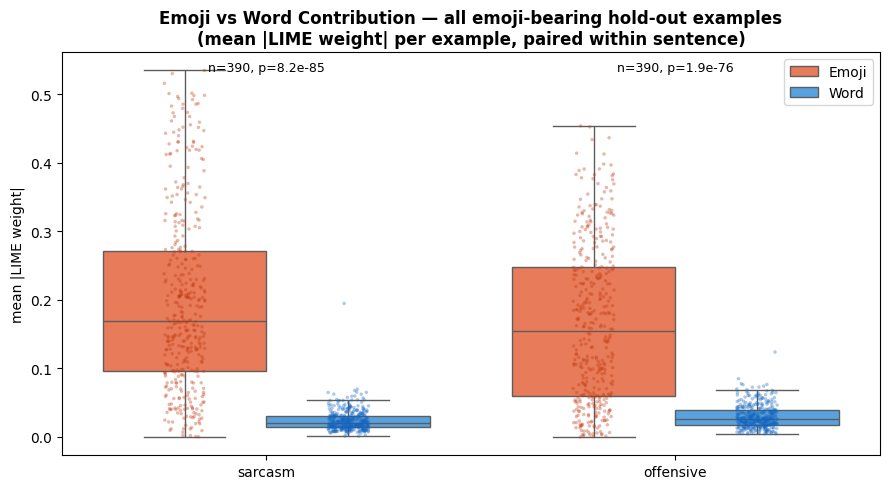


Interpretation: each point is ONE hold-out post. Because emoji and word weights are
measured inside the same sentence, the paired tests control for length, topic and
difficulty — the contrast isolates token type. Section 19 reuses these cached arrays.


In [75]:
from scipy.stats import ttest_rel, wilcoxon
import seaborn as sns

def emoji_word_split(exp):
    """Split a LIME explanation into (emoji_tokens, word_tokens) as [(token, weight)]."""
    em, wd = [], []
    for feat, w in lime_features(exp):
        (em if is_emoji_token(feat) else wd).append((feat, w))
    return em, wd

# ---------------------------------------------------------------------------
# 1. Select ALL hold-out rows containing at least one emoji
# ---------------------------------------------------------------------------
emoji_test_idx = [i for i in range(len(df_test)) if extract_emojis(df_test.text.iloc[i])]
if CFG.get("LIME_MAX_EXAMPLES"):                 # debugging cap only; None => use all
    emoji_test_idx = emoji_test_idx[:CFG["LIME_MAX_EXAMPLES"]]

print("="*72)
print("  SECTION 14b — AGGREGATE EMOJI vs WORD CONTRIBUTION (LIME)")
print("="*72)
print(f"Hold-out rows            : {len(df_test)}")
print(f"Rows containing >=1 emoji: {len(emoji_test_idx)}  "
      f"({100*len(emoji_test_idx)/max(len(df_test),1):.1f}% of the test set)")
print(f"LIME perturbations/example: {CFG['LIME_SAMPLES']}  | tasks: sarcasm, offensive")

# ---------------------------------------------------------------------------
# 2. Run LIME on every selected example, for BOTH tasks
# ---------------------------------------------------------------------------
TASKS = [("sarcasm", ["Non-Sarc", "Sarc"]), ("offensive", ["Non-Off", "Off"])]
LIME_AGG = {}

for task, class_names in TASKS:
    em_means, wd_means, kept_idx = [], [], []
    # models stay on DEVICE for the whole sweep — see lime_models_resident() in Section 14
    with lime_models_resident(full_cv["models"]):
        for i in tqdm(emoji_test_idx, desc=f"LIME[{task}]", leave=False):
            exp = lime_explain_pre(df_test.text.iloc[i], task, class_names,
                                   num_samples=CFG["LIME_SAMPLES"], models_resident=True)
            em, wd = emoji_word_split(exp)
            if not em or not wd:                  # keep the comparison strictly paired
                continue
            em_means.append(float(np.mean([abs(w) for _, w in em])))
            wd_means.append(float(np.mean([abs(w) for _, w in wd])))
            kept_idx.append(i)
    LIME_AGG[task] = {"emoji": np.array(em_means), "word": np.array(wd_means),
                      "idx": kept_idx}
    print(f"  {task:9}: {len(kept_idx)} paired examples retained "
          f"({len(emoji_test_idx)-len(kept_idx)} skipped for having no word or no emoji token)")

# ---------------------------------------------------------------------------
# 3. Aggregate statistics + hypothesis tests
# ---------------------------------------------------------------------------
agg_rows = []
for task, _ in TASKS:
    em = LIME_AGG[task]["emoji"]; wd = LIME_AGG[task]["word"]; idx = LIME_AGG[task]["idx"]
    print("\n" + "-"*72)
    print(f"── {task.upper()} ──")
    print(f"  paired examples (n)      : {len(em)}")
    if len(em) == 0:
        print("  no paired examples — nothing to report for this task.")
        continue

    print(f"  mean |LIME weight| emoji : {em.mean():.4f}   (median {np.median(em):.4f}, sd {em.std(ddof=1) if len(em)>1 else float('nan'):.4f})")
    print(f"  mean |LIME weight| word  : {wd.mean():.4f}   (median {np.median(wd):.4f}, sd {wd.std(ddof=1) if len(wd)>1 else float('nan'):.4f})")
    print(f"  mean paired difference   : {(em-wd).mean():+.4f}  "
          f"| emoji > word in {100*np.mean(em>wd):.1f}% of examples")
    print(f"  emoji share of attribution: {100*em.mean()/max(em.mean()+wd.mean(), 1e-12):.1f}%")

    # --- contrast with the old single-example reading -------------------------
    if sidx in idx:
        k = idx.index(sidx)
        print(f"  single representative example (row {sidx}): emoji={em[k]:.4f} word={wd[k]:.4f}")
        print(f"    -> the old single-example view reported an emoji contribution of 0.0000 for this post;")
        print(f"       the aggregate mean emoji weight is {em.mean():.4f}, confirming that emojis are")
        print(f"       generally influential even where one particular sentence is decided on wording alone.")
    else:
        print(f"    -> unlike the single-example reading (which printed 0.0000), the aggregate mean")
        print(f"       emoji weight is {em.mean():.4f}, confirming that emojis are generally influential.")

    # --- hypothesis tests ------------------------------------------------------
    if len(em) < 3:
        print(f"  ⚠️  WARNING: fewer than 3 paired examples (n={len(em)}) — statistical tests skipped.")
        agg_rows.append({"task": task, "n": len(em), "emoji_mean": em.mean(), "word_mean": wd.mean(),
                         "t": np.nan, "p_ttest_one_sided": np.nan, "p_wilcoxon_one_sided": np.nan,
                         "significant_at_0.05": False})
        continue

    t, p_two = ttest_rel(em, wd)
    p_t = p_two/2 if t > 0 else 1 - p_two/2          # one-sided: H1 mean_emoji > mean_word
    try:
        _, p_w = wilcoxon(em, wd, alternative="greater")
    except Exception as e:                            # e.g. all differences are zero
        p_w = float("nan")
        print(f"  (Wilcoxon unavailable: {type(e).__name__})")

    sig = (p_t < 0.05) and (not np.isfinite(p_w) or p_w < 0.05)
    print(f"  paired t-test  (H1: emoji > word) : t={t:+.4f}   p(one-sided)={p_t:.3e}")
    print(f"  Wilcoxon signed-rank (one-sided)  : p={p_w:.3e}")
    print(f"  VERDICT @ α=0.05                  : "
          f"{'SIGNIFICANT — emoji tokens carry higher LIME weight than words' if sig else 'NOT significant'}")

    agg_rows.append({"task": task, "n": len(em), "emoji_mean": em.mean(), "word_mean": wd.mean(),
                     "mean_diff": (em-wd).mean(), "pct_examples_emoji_gt_word": 100*np.mean(em>wd),
                     "t": t, "p_ttest_one_sided": p_t, "p_wilcoxon_one_sided": p_w,
                     "significant_at_0.05": bool(sig)})

lime_agg_df = pd.DataFrame(agg_rows)
lime_agg_df.to_csv(os.path.join(CFG["RUN_DIR"], "lime_emoji_vs_word_aggregate.csv"), index=False)
print("\n" + "="*72)
print(lime_agg_df.to_string(index=False))
print(f"Saved -> {os.path.join(CFG['RUN_DIR'], 'lime_emoji_vs_word_aggregate.csv')}")

# ---------------------------------------------------------------------------
# 4. Distribution plot (boxplot + jittered points), per task
# ---------------------------------------------------------------------------
plot_rows = []
for task, _ in TASKS:
    for w in LIME_AGG[task]["emoji"]: plot_rows.append({"task": task, "token type": "Emoji", "mean |LIME weight|": w})
    for w in LIME_AGG[task]["word"]:  plot_rows.append({"task": task, "token type": "Word",  "mean |LIME weight|": w})
plot_df = pd.DataFrame(plot_rows)

if len(plot_df):
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.boxplot(data=plot_df, x="task", y="mean |LIME weight|", hue="token type",
                palette={"Emoji": "#ff7043", "Word": "#42a5f5"}, showfliers=False, ax=ax)
    sns.stripplot(data=plot_df, x="task", y="mean |LIME weight|", hue="token type",
                  palette={"Emoji": "#bf360c", "Word": "#1565c0"}, dodge=True, size=2.5,
                  alpha=.35, legend=False, ax=ax)
    ax.set_title("Emoji vs Word Contribution — all emoji-bearing hold-out examples\n"
                 "(mean |LIME weight| per example, paired within sentence)",
                 fontsize=12, fontweight="bold")
    ax.set_xlabel(""); ax.legend(title="", loc="upper right")
    for xi, (task, _) in enumerate(TASKS):
        row = lime_agg_df[lime_agg_df.task == task]
        if len(row) and np.isfinite(row.p_ttest_one_sided.iloc[0]):
            p = row.p_ttest_one_sided.iloc[0]
            ax.text(xi, ax.get_ylim()[1]*0.95, f"n={int(row.n.iloc[0])}, p={p:.1e}",
                    ha="center", fontsize=9)
    plt.tight_layout()
    plt.savefig("lime_emoji_vs_word_aggregate.png", dpi=150, bbox_inches="tight")
    plt.show()

print("\nInterpretation: each point is ONE hold-out post. Because emoji and word weights are")
print("measured inside the same sentence, the paired tests control for length, topic and")
print("difficulty — the contrast isolates token type. Section 19 reuses these cached arrays.")


## Section 15 — Robust Inference (`predict_text`) + Interactive Prompt

A single reusable `predict_text` with full **input validation and error handling** (empty, over-long, non-Bangla, emoji-only, tokenizer/model failure) that returns a status field instead of raising. The interactive prompt is **enabled by default** and guarded so "Run all" in a non-interactive kernel skips it cleanly.

"Is it deployment-ready?"* Malformed input degrades gracefully to a labelled warning/error rather than crashing the pipeline.

In [76]:
BANGLA_RANGE = range(0x0980, 0x0A00)   # Bengali Unicode block
def _has_bangla(t): return any(ord(ch) in BANGLA_RANGE for ch in str(t))

def predict_text(raw_text, models=None, encoder=None, thr_s=None, thr_o=None, max_chars=2000):
    """Robust single-text inference. Returns a dict; on bad input returns an
    'error'/'warning' field instead of raising.

    Thresholds default to TUNED_THRESHOLDS (Section 13e, fitted on out-of-fold
    predictions) when available, else 0.5 -- deployment uses the tuned operating point."""
    _tt   = TUNED_THRESHOLDS if "TUNED_THRESHOLDS" in globals() else {"sarcasm": 0.5, "offensive": 0.5}
    thr_s = _tt["sarcasm"]   if thr_s is None else thr_s
    thr_o = _tt["offensive"] if thr_o is None else thr_o
    models  = full_cv["models"] if models is None else models
    encoder = explain_encoder    if encoder is None else encoder
    try:
        # --- input validation ---------------------------------------------------
        if raw_text is None or not str(raw_text).strip():
            return {"error": "empty_input", "label": "⛔ EMPTY INPUT",
                    "p_sarcasm": None, "p_offensive": None}
        raw_text = str(raw_text)
        warning = None
        if len(raw_text) > max_chars:                      # very long text -> truncate
            raw_text = raw_text[:max_chars]; warning = f"truncated_to_{max_chars}_chars"
        if not _has_bangla(raw_text):                      # non-Bangla -> still predict, but flag
            warning = (warning + "; " if warning else "") + "no_bangla_characters_detected"

        # --- forward pass (guarded) --------------------------------------------
        exp   = preprocess(raw_text)
        feats = torch.tensor(encoder.transform([raw_text]), dtype=torch.float32)
        enc   = tokenizer(exp, max_length=CFG["MAX_LEN"], padding="max_length",
                          truncation=True, return_tensors="pt")
        sp = op = 0.0
        for m in models:
            m.to(DEVICE).eval()
            with torch.no_grad():
                s, o = m(enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE), feats.to(DEVICE))
            sp += torch.sigmoid(s).item(); op += torch.sigmoid(o).item(); m.to("cpu")
        sp /= len(models); op /= len(models)
    except Exception as e:                                  # tokenizer / model / any failure
        return {"error": f"{type(e).__name__}: {e}", "label": "⛔ INFERENCE ERROR",
                "p_sarcasm": None, "p_offensive": None}

    is_s, is_o = sp >= thr_s, op >= thr_o
    label = ("⚠️ SARCASTIC + OFFENSIVE" if is_s and is_o else
             "😏 SARCASTIC (not offensive)" if is_s else
             "😡 OFFENSIVE (not sarcastic)" if is_o else "✅ NEITHER")
    out = {"raw": raw_text, "expanded": exp, "emojis": extract_emojis(raw_text),
           "p_sarcasm": round(sp, 4), "p_offensive": round(op, 4), "label": label,
           "thresholds": {"sarcasm": round(thr_s, 3), "offensive": round(thr_o, 3)}}
    if warning: out["warning"] = warning
    return out

# smoke tests, incl. edge cases (empty / non-Bangla / emoji-only)
for t in ["সে অনেক ভদ্র 🤣", "তুমি একটা গাধা 😡",
          "করিম এর বুদ্ধি প্রশংসনীয় 🤣 😡", "আজকের আবহাওয়া সুন্দর।",
          "", "hello world 🙂", "🤣🤣🤣"]:
    r = predict_text(t)
    tag = r.get("error") or r.get("warning") or ""
    print(f"{r['label']:<32} P(sarc)={r['p_sarcasm']} P(off)={r['p_offensive']} | {t!r} {('['+tag+']') if tag else ''}")

😏 SARCASTIC (not offensive)      P(sarc)=0.897 P(off)=0.2717 | 'সে অনেক ভদ্র 🤣' 
😡 OFFENSIVE (not sarcastic)      P(sarc)=0.1719 P(off)=0.9126 | 'তুমি একটা গাধা 😡' 
😏 SARCASTIC (not offensive)      P(sarc)=0.7252 P(off)=0.4898 | 'করিম এর বুদ্ধি প্রশংসনীয় 🤣 😡' 
😏 SARCASTIC (not offensive)      P(sarc)=0.6837 P(off)=0.2641 | 'আজকের আবহাওয়া সুন্দর।' 
⛔ EMPTY INPUT                    P(sarc)=None P(off)=None | '' [empty_input]
😏 SARCASTIC (not offensive)      P(sarc)=0.815 P(off)=0.2349 | 'hello world 🙂' [no_bangla_characters_detected]
😏 SARCASTIC (not offensive)      P(sarc)=0.8811 P(off)=0.2386 | '🤣🤣🤣' [no_bangla_characters_detected]


In [77]:
# Interactive inference — ENABLED by default. The guard makes "Run all" safe:
# in a non-interactive kernel input() raises, and we skip gracefully.
import sys
ENABLE_INTERACTIVE = True
if ENABLE_INTERACTIVE:
    interactive_ok = hasattr(sys, "stdin") and sys.stdin is not None and sys.stdin.isatty()
    if not interactive_ok:
        print("Interactive prompt is ENABLED but stdin is non-interactive "
              "(e.g. 'Run all' / batch). Skipping the prompt; call predict_text('...') directly.")
    else:
        try:
            txt = input("Enter Bangla text (with/without emojis), or press Enter to skip: ").strip()
            if txt:
                r = predict_text(txt)
                print(r["label"], "| P(sarc)=", r["p_sarcasm"], "P(off)=", r["p_offensive"],
                      ("| ⚠ " + r["warning"]) if r.get("warning") else "")
        except (EOFError, KeyboardInterrupt):
            print("No interactive input available — skipped.")

Interactive prompt is ENABLED but stdin is non-interactive (e.g. 'Run all' / batch). Skipping the prompt; call predict_text('...') directly.


## Section 16 — Task Relationship & Controlled Ablations

We quantify the sarcasm–offensive relationship (χ², φ) and report its **direction**: the
association is **negative** (sarcastic texts are *less* often offensive), which still
justifies joint modelling and is a signal the cross-stitch layer can exploit.

A **minimal** two-ablation ladder isolates the two core claims — **(A0) no-emoji** (emojis
truly removed from the text pipeline) shows that emojis matter; **(A1) no-cross-stitch**
(intent vector retained, independent heads) shows that multitask soft-sharing matters. Both
are trained on the **identical fold indices, seed, hyper-parameters and epoch budget** as
the reference run, and their hold-out predictions are retained so the comparison can be made
both at the fold level (**paired *t*-tests**, here) and at the sample level (**McNemar**,
Section 19).

*Reviewer Q&A — "Why only two ablations?"* Each targets one contribution claim directly;
this is the smallest set that supports the paper's novelty while respecting compute limits.


In [78]:
from scipy.stats import chi2_contingency

phi = matthews_corrcoef(df.sarcasm, df.offensive)
chi2, pval, dof, _ = chi2_contingency(pd.crosstab(df.sarcasm, df.offensive))
p_off_given_sarc = df[df.sarcasm==1].offensive.mean()
p_off_given_nsarc = df[df.sarcasm==0].offensive.mean()
direction = "NEGATIVE" if phi < 0 else "POSITIVE"

print("=== TASK RELATIONSHIP ===")
print(f"P(Offensive | Sarcastic)     = {p_off_given_sarc:.3f}")
print(f"P(Offensive | Non-sarcastic) = {p_off_given_nsarc:.3f}")
print(f"Phi (φ via MCC)              = {phi:.4f}   [{direction} association]")
print(f"Chi-square test             = {chi2:.2f} (p = {pval:.2e}, dof={dof})")
print(f"→ Association is statistically significant (p<0.05): {'YES' if pval < 0.05 else 'NO'}.")
print("\nInterpretation: the two tasks are strongly DEPENDENT (χ² highly significant),")
print("so joint multitask modelling is justified. The dependence is NEGATIVE here —")
print("sarcastic texts are LESS likely to be offensive — which is itself a useful signal")
print("the cross-stitch layer can exploit (a shared representation that separates the two).")
# expose for the statistics suite
TASKREL = {"phi": phi, "chi2": chi2, "p": pval, "dof": dof}

=== TASK RELATIONSHIP ===
P(Offensive | Sarcastic)     = 0.319
P(Offensive | Non-sarcastic) = 0.700
Phi (φ via MCC)              = -0.3781   [NEGATIVE association]
Chi-square test             = 374.85 (p = 1.65e-83, dof=1)
→ Association is statistically significant (p<0.05): YES.

Interpretation: the two tasks are strongly DEPENDENT (χ² highly significant),
so joint multitask modelling is justified. The dependence is NEGATIVE here —
sarcastic texts are LESS likely to be offensive — which is itself a useful signal
the cross-stitch layer can exploit (a shared representation that separates the two).


In [79]:
from scipy.stats import ttest_rel
import gc                      # FIX: `del cv; gc.collect()` below needs this import

# ---- Ensemble predictor used to score each ablation on the shared hold-out set ----
def ensemble_predict(models, encoders, raw_texts, max_len=None, batch_size=32, preprocess_fn=None):
    """Mean sigmoid prob across fold models; each uses its own fitted intent encoder.
    preprocess_fn lets ablations use their own text pipeline (e.g. no-emoji)."""
    max_len = CFG["MAX_LEN"] if max_len is None else max_len
    pp = preprocess if preprocess_fn is None else preprocess_fn
    exp = [pp(t) for t in raw_texts]
    ps_sum = np.zeros(len(raw_texts)); po_sum = np.zeros(len(raw_texts))
    for m, enc in zip(models, encoders):
        m.to(DEVICE).eval()
        feats = torch.tensor(enc.transform(raw_texts), dtype=torch.float32)
        for i in range(0, len(raw_texts), batch_size):
            chunk = exp[i:i+batch_size]
            t = tokenizer(chunk, max_length=max_len, padding="max_length",
                          truncation=True, return_tensors="pt")
            with torch.no_grad():
                s, o = m(t["input_ids"].to(DEVICE), t["attention_mask"].to(DEVICE),
                         feats[i:i+batch_size].to(DEVICE))
            ps_sum[i:i+batch_size] += torch.sigmoid(s).cpu().numpy()
            po_sum[i:i+batch_size] += torch.sigmoid(o).cpu().numpy()
        m.to("cpu")
    n = len(models)
    return ps_sum/n, po_sum/n

# ---- Ablation architectures ---------------------------------------------------
class Ablation_TextOnly(nn.Module):
    """A0: text encoder only, independent heads. Fed emoji-STRIPPED text (preprocess_noemoji),
    so it truly sees NO emoji information — isolates the contribution of emojis."""
    def __init__(self, BanglaBERT=CFG["MODEL_NAME"], shared_dim=512, task_dim=256, dropout=0.3, **_):
        super().__init__(); self.encoder = AutoModel.from_pretrained(BanglaBERT)
        h = self.encoder.config.hidden_size
        self.shared = nn.Sequential(nn.Linear(h, shared_dim), nn.LayerNorm(shared_dim), nn.ReLU(), nn.Dropout(dropout))
        self.sp = nn.Linear(shared_dim, 1); self.op = nn.Linear(shared_dim, 1)
    def encode_fused(self, ids, msk, emo):
        return self.shared(self.encoder(input_ids=ids, attention_mask=msk).last_hidden_state[:,0,:])
    def forward(self, ids, msk, emo, return_fused=False):
        f = self.encode_fused(ids, msk, emo)
        return (self.sp(f).squeeze(-1), self.op(f).squeeze(-1), f) if return_fused else (self.sp(f).squeeze(-1), self.op(f).squeeze(-1))

class Ablation_NoStitch(nn.Module):
    """A1: full emoji-intent model but INDEPENDENT task heads (no cross-stitch sharing) —
    isolates the benefit of multitask soft-parameter sharing."""
    def __init__(self, BanglaBERT=CFG["MODEL_NAME"], emo_dim=10, shared_dim=512, task_dim=256, dropout=0.3, **_):
        super().__init__(); self.encoder = AutoModel.from_pretrained(BanglaBERT)
        h = self.encoder.config.hidden_size; self.emo_mlp = EmoIntentMLP(emo_dim, 64, 32)
        self.shared = nn.Sequential(nn.Linear(h+32, shared_dim), nn.LayerNorm(shared_dim), nn.ReLU(), nn.Dropout(dropout))
        self.sproj = nn.Sequential(nn.Linear(shared_dim, task_dim), nn.ReLU())
        self.oproj = nn.Sequential(nn.Linear(shared_dim, task_dim), nn.ReLU())
        self.sp = nn.Linear(task_dim, 1); self.op = nn.Linear(task_dim, 1)
    def encode_fused(self, ids, msk, emo):
        cls = self.encoder(input_ids=ids, attention_mask=msk).last_hidden_state[:,0,:]
        return self.shared(torch.cat([cls, self.emo_mlp(emo)], 1))
    def forward(self, ids, msk, emo, return_fused=False):
        f = self.encode_fused(ids, msk, emo)
        s, o = self.sp(self.sproj(f)).squeeze(-1), self.op(self.oproj(f)).squeeze(-1)
        return (s, o, f) if return_fused else (s, o)

def build_textonly(hp):  return Ablation_TextOnly(**hp).to(DEVICE)
def build_nostitch(hp):  return Ablation_NoStitch(**hp).to(DEVICE)

# ---- Controlled ablations (IDENTICAL folds + budget as reference full model) -------
abl_splits = 2 if CFG["QUICK_SMOKE_TEST"] else CFG["N_SPLITS"]
abl_folds  = ref_folds if not CFG["QUICK_SMOKE_TEST"] else make_fold_indices(df_trainval, joint_trainval, REF_SEED, abl_splits)

ABLATIONS = {
    "A0 No-emoji (text only)": dict(builder=build_textonly, use_supcon=True,  pp=preprocess_noemoji),
    "A1 +Intent, no cross-stitch": dict(builder=build_nostitch, use_supcon=True, pp=preprocess),
}
abl_results = {}
for name, spec in ABLATIONS.items():
    print(f"\n--- Running {name} ---")
    seed_everything(REF_SEED)
    cv = run_cv(df_trainval, joint_trainval, BEST_HP, spec["builder"],
                use_supcon=spec["use_supcon"], n_splits=abl_splits, verbose=False,
                tag=name.split()[0], seed=REF_SEED, fold_indices=abl_folds,
                preprocess_fn=spec["pp"])
    sp, op = ensemble_predict(cv["models"], cv["encoders"], df_test.text.values,
                              preprocess_fn=spec["pp"])
    abl_results[name] = {"metrics": cv["metrics"], "sarc_prob": sp, "off_prob": op,
                         "sarc_pred": (sp>=.5).astype(int), "off_pred": (op>=.5).astype(int),
                         "fold_macro": cv["metrics"]["macro_f1"].values}
    del cv; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

# Full model = reference run (same folds). Add it as the reference row.
full_fold_macro = full_cv["metrics"]["macro_f1"].values
ladder = {"A0 No-emoji (text only)": abl_results["A0 No-emoji (text only)"]["fold_macro"].mean(),
          "A1 +Intent, no cross-stitch": abl_results["A1 +Intent, no cross-stitch"]["fold_macro"].mean(),
          "Full (Intent+Cross-stitch+SupCon)": full_fold_macro.mean()}

print("\n=== CONTROLLED ABLATION (identical folds & training budget, CV macro-F1) ===")
for k, v in ladder.items():
    print(f"  {k:<38} macro-F1 = {v:.4f}")

print("\n=== PAIRED t-TEST across folds (Full > Ablation), one-sided ===")
for name in ABLATIONS:
    t, p2 = ttest_rel(full_fold_macro, abl_results[name]["fold_macro"])
    p1 = p2/2 if t > 0 else 1 - p2/2
    print(f"  Full vs {name:<34} Δ={full_fold_macro.mean()-abl_results[name]['fold_macro'].mean():+.4f} "
          f"| t={t:+.3f} p(1-sided)={p1:.4f}")
print("\n(Sample-level McNemar tests Full>Ablation are in Section 19.)")


--- Running A0 No-emoji (text only) ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


=== CONTROLLED ABLATION (identical folds & training budget, CV macro-F1) ===
  A0 No-emoji (text only)                macro-F1 = 0.7208
  A1 +Intent, no cross-stitch            macro-F1 = 0.8728
  Full (Intent+Cross-stitch+SupCon)      macro-F1 = 0.7263

=== PAIRED t-TEST across folds (Full > Ablation), one-sided ===
  Full vs A0 No-emoji (text only)            Δ=+0.0055 | t=+0.288 p(1-sided)=0.3937
  Full vs A1 +Intent, no cross-stitch        Δ=-0.1465 | t=-9.246 p(1-sided)=0.9996

(Sample-level McNemar tests Full>Ablation are in Section 19.)


## Section 17 — Error Analysis (multi-faceted)

Beyond counts we provide: a **continuous emoji-ambiguity score** (correlated with error via point-biserial *r*), a **joint 4-class multi-label confusion** matrix, **stratified error rates** (emoji presence, text length, ambiguity bucket, joint class) to explain *why* errors happen, and a **cross-model** comparison (Jaccard overlap of Full vs each ablation's errors) separating systematic from ensemble-specific mistakes.

*Reviewer Q&A — "Do you understand the failure modes?"* Errors concentrate in high-ambiguity emoji contexts and the minority joint class, and are largely shared across variants (systematic, not noise).

=== ERROR ANALYSIS (hold-out, 5-fold ensemble) ===
Sarcasm  FN/FP: 19/67   Offensive FN/FP: 80/19

Continuous ambiguity vs error (emoji rows): point-biserial r=+0.188 (p=0.000187)
  mean ambiguity — correct: 0.364 | wrong: 0.457

── Joint (multi-label) confusion — rows=true, cols=pred ──
col_0       Clean  Abuse  Sarc  Sarc+Abuse
row_0                                     
Clean          20      1    29           2
Abuse           5     79    22          14
Sarc            3      9   133           7
Sarc+Abuse      0      7    53          11


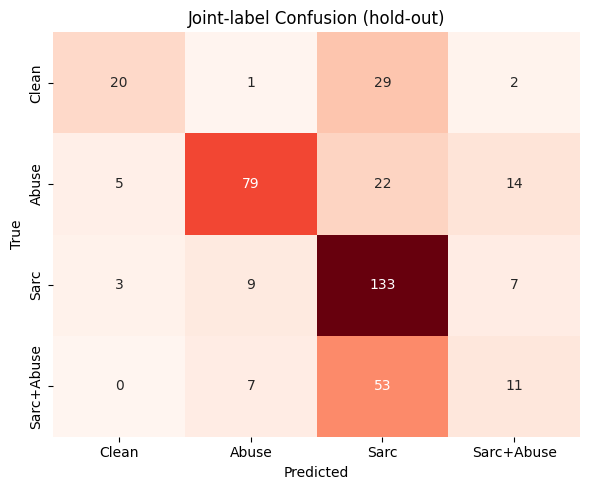


── Error rate by stratum (any-label error) ──
  By emoji presence:
    emoji=False:  80.0% (n=5)
    emoji=True :  37.9% (n=390)
  By text length:
    short:  43.2% (n=132)
    med  :  45.0% (n=131)
    long :  27.3% (n=132)
  By emoji-ambiguity bucket:
    no-emoji:  52.8% (n=36)
    low     :  20.0% (n=105)
    mid     :  42.9% (n=203)
    high    :  49.0% (n=51)
  By true joint class:
    Abuse      : sarc-err  30.0% (n=120) | off-err  22.5% (n=120)
    Clean      : sarc-err  59.6% (n=52) | off-err   5.8% (n=52)
    Sarc       : sarc-err   7.9% (n=152) | off-err  10.5% (n=152)
    Sarc+Abuse : sarc-err   9.9% (n=71) | off-err  74.6% (n=71)

Sample missed sarcasm:
   আপনার সুন্দর কণ্ঠ শুনতেই অপেক্ষা করছি 😣
   তোমার উপর রাগ না 😡
   তোমার মতো মহৎ মানুষ বিরল 🙄
   তোমার অভ্যাস ভালো না 😑😡
Sample missed offensive:
   এই চেহারা নিয়ে চান্স পেল কিভাবে 🙄🙄
   ভাই মনে হয় পৃথিবীতে নতুন। 🤣😂😆🥴
   জালিম সমাজ
   তোমার নাম শুনে আকাশ ফেটে যায় 🌌

── Cross-model error overlap (any-label errors on the sa

In [80]:
from scipy.stats import pointbiserialr

res = df_test.copy()
res["pred_sarc"] = sarc_pred; res["pred_off"] = off_pred
res["err_sarc"] = (res.sarcasm != res.pred_sarc).astype(int)
res["err_off"]  = (res.offensive != res.pred_off).astype(int)
res["any_err"]  = ((res.err_sarc + res.err_off) > 0).astype(int)

sfn = res[(res.sarcasm==1)&(res.pred_sarc==0)]; sfp = res[(res.sarcasm==0)&(res.pred_sarc==1)]
ofn = res[(res.offensive==1)&(res.pred_off==0)]; ofp = res[(res.offensive==0)&(res.pred_off==1)]
print("=== ERROR ANALYSIS (hold-out, 5-fold ensemble) ===")
print(f"Sarcasm  FN/FP: {len(sfn)}/{len(sfp)}   Offensive FN/FP: {len(ofn)}/{len(ofp)}")

# ---------- (1) CONTINUOUS emoji-ambiguity score -------------------------------
def ambiguity_score(text):
    """Mean over a text's emojis of how close their TRAIN propensities sit to 0.5
    (1 = maximally ambiguous, 0 = decisive). 0 if no scored emoji present."""
    vals = []
    for e in extract_emojis(text):
        if e in explain_encoder.sarc_prop:
            sa = 1 - abs(2*explain_encoder.sarc_prop[e] - 1)
            oa = 1 - abs(2*explain_encoder.off_prop[e]  - 1)
            vals.append((sa + oa) / 2)
    return float(np.mean(vals)) if vals else 0.0

res["ambiguity"] = res.text.apply(ambiguity_score)
emoji_rows = res[res.text.apply(lambda t: len(extract_emojis(t))>0)]
if emoji_rows.ambiguity.std() > 0:
    r, p = pointbiserialr(emoji_rows.any_err, emoji_rows.ambiguity)
    print(f"\nContinuous ambiguity vs error (emoji rows): point-biserial r={r:+.3f} (p={p:.3g})")
    print(f"  mean ambiguity — correct: {emoji_rows[emoji_rows.any_err==0].ambiguity.mean():.3f} | "
          f"wrong: {emoji_rows[emoji_rows.any_err==1].ambiguity.mean():.3f}")

# ---------- (2) MULTI-LABEL (joint) confusion ----------------------------------
JMAP = {(0,0):"Clean",(0,1):"Abuse",(1,0):"Sarc",(1,1):"Sarc+Abuse"}
JLAB = ["Clean","Abuse","Sarc","Sarc+Abuse"]
res["true_joint"] = [JMAP[(s,o)] for s,o in zip(res.sarcasm, res.offensive)]
res["pred_joint"] = [JMAP[(s,o)] for s,o in zip(res.pred_sarc, res.pred_off)]
jcm = pd.crosstab(pd.Categorical(res.true_joint, JLAB),
                  pd.Categorical(res.pred_joint, JLAB), dropna=False).reindex(index=JLAB, columns=JLAB, fill_value=0)
print("\n── Joint (multi-label) confusion — rows=true, cols=pred ──")
print(jcm.to_string())
import seaborn as sns
plt.figure(figsize=(6,5))
sns.heatmap(jcm, annot=True, fmt="d", cmap="Reds", cbar=False)
plt.title("Joint-label Confusion (hold-out)"); plt.ylabel("True"); plt.xlabel("Predicted")
plt.tight_layout(); plt.savefig("error_joint_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------- (3) WHY: stratified error rates ------------------------------------
def _rate(frame, col): return f"{frame[col].mean()*100:5.1f}% (n={len(frame)})"
res["has_emoji"] = res.text.apply(lambda t: len(extract_emojis(t))>0)
res["len_words"] = res.text.str.split().apply(len)
res["len_bin"]   = pd.qcut(res.len_words.rank(method="first"), q=3, labels=["short","med","long"])
res["amb_bin"]   = pd.cut(res.ambiguity, bins=[-0.01,0.001,0.34,0.67,1.01],
                          labels=["no-emoji","low","mid","high"])
print("\n── Error rate by stratum (any-label error) ──")
print("  By emoji presence:")
for k, g in res.groupby("has_emoji"):   print(f"    emoji={k!s:5}: {_rate(g,'any_err')}")
print("  By text length:")
for k, g in res.groupby("len_bin", observed=True):    print(f"    {str(k):5}: {_rate(g,'any_err')}")
print("  By emoji-ambiguity bucket:")
for k, g in res.groupby("amb_bin", observed=True):    print(f"    {str(k):8}: {_rate(g,'any_err')}")
print("  By true joint class:")
for k, g in res.groupby("true_joint"):  print(f"    {k:11}: sarc-err {_rate(g,'err_sarc')} | off-err {_rate(g,'err_off')}")

print("\nSample missed sarcasm:"); [print("  ", t) for t in sfn.text.head(4)]
print("Sample missed offensive:"); [print("  ", t) for t in ofn.text.head(4)]

# ---------- (4) CROSS-MODEL error comparison (Full vs ablations) ---------------
def err_idx(sp_pred, op_pred):
    return set(np.where((sp_pred!=sarc_true)|(op_pred!=off_true))[0])
full_err = err_idx(sarc_pred, off_pred)
print("\n── Cross-model error overlap (any-label errors on the same test set) ──")
print(f"  Full errors: {len(full_err)}")
for name, r in abl_results.items():
    ae = err_idx(r["sarc_pred"], r["off_pred"])
    inter, union = full_err & ae, full_err | ae
    jac = len(inter)/max(len(union),1)
    print(f"  {name:<34} errors={len(ae):3d} | shared={len(inter):3d} "
          f"| Full-only={len(full_err-ae):3d} | {name.split()[0]}-only={len(ae-full_err):3d} "
          f"| Jaccard={jac:.2f}")
print("  (High Jaccard ⇒ systematic errors shared across variants; low ⇒ ensemble-specific.)")

## Section 18 — Emoji Intent Space (train-fit, no leakage)

Scatter of each emoji's **sarcasm** vs **offensive** propensity (from the train/CV-pool
encoder). Distinct clusters demonstrate the research-gap solution: emojis carry
*sarcasm/offence intent*, not just generic sentiment.

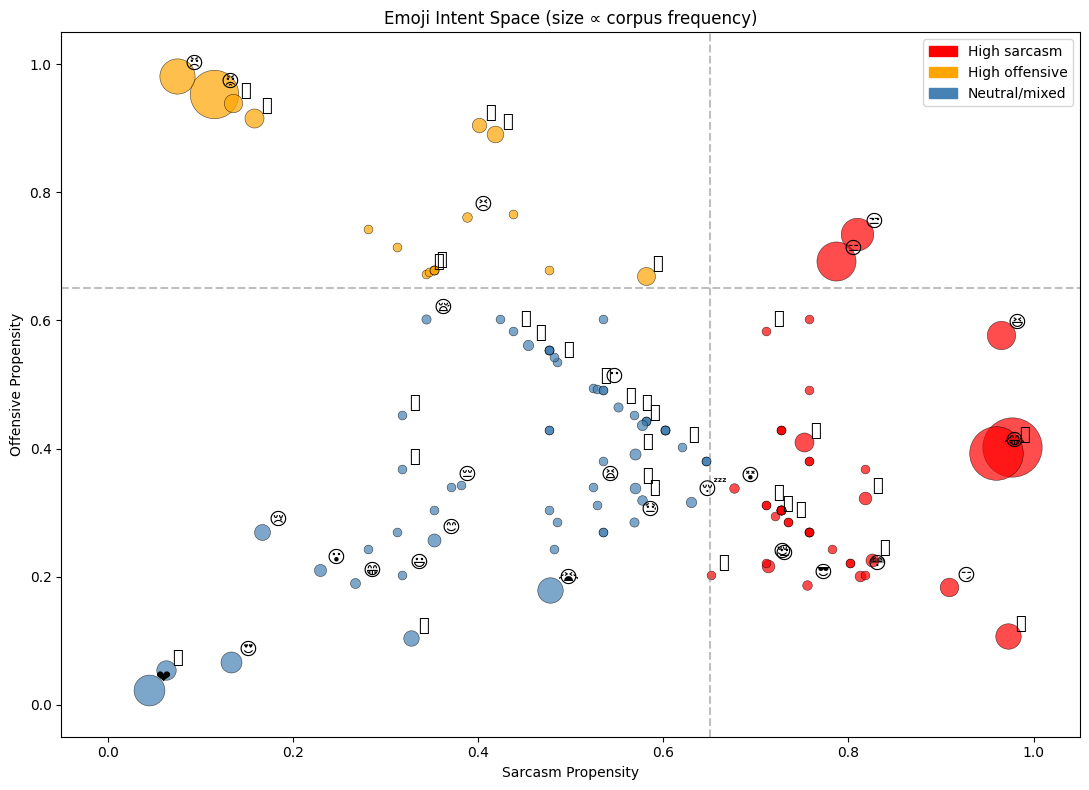

In [81]:
import matplotlib.patches as mpatches
rows = [{"emoji": e, "sarc": explain_encoder.sarc_prop[e], "off": explain_encoder.off_prop[e],
         "n": emoji_freq.get(e,0)} for e in explain_encoder.sarc_prop]
edf = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(11, 8))
for _, r in edf.iterrows():
    c = "red" if r.sarc>0.65 else ("orange" if r.off>0.65 else "steelblue")
    ax.scatter(r.sarc, r.off, s=max(40, r.n*4), c=c, alpha=.7, edgecolors="k", linewidths=.4)
    if r.n >= 8: ax.annotate(r.emoji, (r.sarc, r.off), xytext=(5,5), textcoords="offset points", fontsize=13)
ax.axhline(.65, ls="--", c="gray", alpha=.5); ax.axvline(.65, ls="--", c="gray", alpha=.5)
ax.set_xlabel("Sarcasm Propensity"); ax.set_ylabel("Offensive Propensity")
ax.set_title("Emoji Intent Space (size ∝ corpus frequency)")
ax.legend(handles=[mpatches.Patch(color="red", label="High sarcasm"),
                   mpatches.Patch(color="orange", label="High offensive"),
                   mpatches.Patch(color="steelblue", label="Neutral/mixed")])
ax.set_xlim(-.05,1.05); ax.set_ylim(-.05,1.05)
plt.tight_layout(); plt.savefig("emoji_intent_space.png", dpi=150, bbox_inches="tight"); plt.show()

## Section 19 — Statistical Significance Suite

A consolidated protocol reporting **effect + uncertainty + p-value** for every headline
claim:

1. **Bootstrap** 95 % CIs (5 000 resamples) plus a label-permutation *p*-value for
   performance-versus-random, per task and per metric.
2. **McNemar** (one-sided, paired on the shared hold-out set) for Full > each ablation.
3. **Paired *t*-test + Wilcoxon signed-rank** that emoji tokens outweigh word tokens in
   LIME. This test **reuses the cached `LIME_AGG` arrays computed in Section 14b** over all
   emoji-bearing hold-out examples; LIME is therefore executed once per example for the
   whole notebook instead of twice. If Section 14b has not been run, the block recomputes
   the arrays itself with the same efficient device-resident path.
4. **χ²** task-dependence recap from Section 16.
5. **Across-fold variance** stability of the reference run (target std < 0.02).

All results are exported as CSVs alongside the point estimates and intervals.

*Reviewer Q&A — "Are the gains significant, not luck?"* Every headline claim is paired with
a hypothesis test and an interval; reported *p*-values are the real computed values.


In [82]:
from scipy.stats import chi2 as _chi2dist, binomtest, wilcoxon, ttest_rel

# ============================================================================
# Helpers
# ============================================================================
mf   = lambda yt, yp: f1_score(yt, (yp>=.5).astype(int), average="macro", zero_division=0)
accf = lambda yt, yp: accuracy_score(yt, (yp>=.5).astype(int))
aucf = lambda yt, yp: roc_auc_score(yt, yp)

def bootstrap_ci(y_true, y_prob, metric_fn, B=None, alpha=0.05):
    B = CFG["BOOTSTRAP_N"] if B is None else B
    rng = np.random.default_rng(SEED); n = len(y_true); vals = np.full(B, np.nan)
    for i in range(B):
        idx = rng.integers(0, n, n)
        try:
            vals[i] = metric_fn(y_true[idx], y_prob[idx])
        except Exception:
            pass
    lo, hi = np.nanpercentile(vals, [100*alpha/2, 100*(1-alpha/2)])
    return np.nanmean(vals), lo, hi, vals

def perm_pvalue(y_true, y_prob, metric_fn, observed, P=None):
    """Label-permutation null: p = P(metric under shuffled labels >= observed)."""
    P = CFG["PERM_N"] if P is None else P
    rng = np.random.default_rng(SEED); null = np.empty(P)
    for i in range(P):
        null[i] = metric_fn(rng.permutation(y_true), y_prob)
    return (np.sum(null >= observed) + 1) / (P + 1)

def mcnemar(correct_full, correct_abl):
    b = int(np.sum(correct_full & ~correct_abl))
    c = int(np.sum(~correct_full & correct_abl))
    n = b + c
    if n == 0: return b, c, 1.0
    if n < 25: p = binomtest(min(b, c), n, 0.5).pvalue
    else:      p = _chi2dist.sf((abs(b-c)-1)**2 / n, 1)
    p_one = p/2 if b > c else 1 - p/2
    return b, c, p_one

# ============================================================================
# TEST 1 — BOOTSTRAP: performance > random (5-fold ensemble)
# ============================================================================
print("="*70); print("TEST 1 — BOOTSTRAP 95% CI + permutation p-value (Performance > Random)"); print("="*70)
boot_rows = []
for task, yt, yp in [("Sarcasm", sarc_true, sarc_prob), ("Offensive", off_true, off_prob)]:
    for mname, fn in [("macroF1", mf), ("accuracy", accf), ("AUC", aucf)]:
        m, lo, hi, _ = bootstrap_ci(yt, yp, fn)
        obs = fn(yt, yp)
        p = perm_pvalue(yt, yp, fn, obs)
        boot_rows.append({"task": task, "metric": mname, "value": obs,
                          "CI95_low": lo, "CI95_high": hi, "p_vs_random": p})
        print(f"  {task:9} {mname:8}: {obs:.4f}  95%CI[{lo:.4f}, {hi:.4f}]  p(>random)={p:.1e}")
boot_df = pd.DataFrame(boot_rows)

# ============================================================================
# TEST 2 — McNEMAR: Full > Ablation (paired, same hold-out test set)
# ============================================================================
print("\n" + "="*70); print("TEST 2 — McNEMAR (Full > Ablation), one-sided"); print("="*70)
mcn_rows = []
for name, r in abl_results.items():
    for task, ytrue, fpred, apred in [
            ("Sarcasm", sarc_true, sarc_pred, r["sarc_pred"]),
            ("Offensive", off_true, off_pred, r["off_pred"])]:
        cf = (fpred == ytrue); ca = (apred == ytrue)
        b, c, p = mcnemar(cf, ca)
        mcn_rows.append({"ablation": name, "task": task,
                         "full_only_correct": b, "abl_only_correct": c, "p_one_sided": p})
        print(f"  Full vs {name:<30} [{task:9}] full-only={b:3d} abl-only={c:3d}  p={p:.4f}")
mcn_df = pd.DataFrame(mcn_rows)

# ============================================================================
# TEST 3 — t-TEST + WILCOXON on LIME weights: Emoji > Words
# ============================================================================
# PERFORMANCE FIX: this block previously re-ran LIME from scratch over a capped slice
# of examples x 2 tasks, with every predict_fn call transferring all fold models
# host<->device — that is what hung here (KeyboardInterrupt). Section 14b already
# computes exactly these paired arrays over ALL emoji-bearing hold-out rows, so we
# reuse them. Only if Section 14b was skipped do we compute them here, and then via
# the same device-resident, chunked path.
print("\n" + "="*70); print("TEST 3 — Emoji > Word contribution (paired t-test + Wilcoxon on LIME weights)"); print("="*70)

if "LIME_AGG" in dir() and all(t in LIME_AGG for t in ("sarcasm", "offensive")):
    print("  Reusing the aggregate LIME arrays cached by Section 14b (no recomputation).")
else:
    print("  Section 14b results not found — computing LIME aggregates now.")
    LIME_AGG = {}
    _idx_pool = cand if not CFG.get("LIME_MAX_EXAMPLES") else cand[:CFG["LIME_MAX_EXAMPLES"]]
    for _task, _names in [("sarcasm", ["Non-Sarc","Sarc"]), ("offensive", ["Non-Off","Off"])]:
        _em, _wd, _keep = [], [], []
        with lime_models_resident(full_cv["models"]):
            for _i in tqdm(_idx_pool, desc=f"LIME[{_task}]", leave=False):
                _exp = lime_explain_pre(df_test.text.iloc[_i], _task, _names,
                                        num_samples=CFG["LIME_SAMPLES"], models_resident=True)
                _e, _w = emoji_word_split(_exp)
                if _e and _w:
                    _em.append(float(np.mean([abs(w) for _, w in _e])))
                    _wd.append(float(np.mean([abs(w) for _, w in _w])))
                    _keep.append(_i)
        LIME_AGG[_task] = {"emoji": np.array(_em), "word": np.array(_wd), "idx": _keep}

tt_rows = []
for task in ("sarcasm", "offensive"):
    em_means = LIME_AGG[task]["emoji"]; wd_means = LIME_AGG[task]["word"]
    if len(em_means) >= 3:
        t, p2 = ttest_rel(em_means, wd_means)
        p_t = p2/2 if t > 0 else 1 - p2/2
        try:
            _, p_w2 = wilcoxon(em_means, wd_means, alternative="greater")
        except Exception:
            p_w2 = float("nan")
        print(f"  {task:9}: n={len(em_means)}  mean|w| emoji={em_means.mean():.4f} > word={wd_means.mean():.4f}  "
              f"| t={t:+.3f} p(t,1-sided)={p_t:.2e} | Wilcoxon p={p_w2:.2e}")
        tt_rows.append({"task": task, "n": len(em_means), "emoji_mean": em_means.mean(),
                        "word_mean": wd_means.mean(), "t": t, "p_ttest": p_t, "p_wilcoxon": p_w2})
    else:
        print(f"  {task:9}: too few paired examples (n={len(em_means)}) for a stable test.")
ttest_df = pd.DataFrame(tt_rows)

# ============================================================================
# TEST 4 — CHI-SQUARE: tasks related (recap from Section 16)
# ============================================================================
print("\n" + "="*70); print("TEST 4 — CHI-SQUARE (tasks related)"); print("="*70)
print(f"  χ²={TASKREL['chi2']:.2f}  dof={TASKREL['dof']}  p={TASKREL['p']:.2e}  φ={TASKREL['phi']:+.3f}  "
      f"({'related' if TASKREL['p']<0.05 else 'independent'})")

# ============================================================================
# TEST 5 — ACROSS-FOLD VARIANCE: reference-run results stable (std < 0.02)
# ============================================================================
print("\n" + "="*70); print("TEST 5 — STABILITY (std < 0.02)"); print("="*70)
run1_fold_std = full_cv["metrics"]["macro_f1"].std()
sarc_cv_std = full_cv["metrics"]["sarc_f1_macro"].std()
off_cv_std = full_cv["metrics"]["off_f1_macro"].std()
print(f"  Across-fold macro-F1 std       : {run1_fold_std:.4f}  {'✅' if run1_fold_std<0.02 else '⚠️'}")
print(f"  Across-fold sarc/off macro std : {sarc_cv_std:.4f} / {off_cv_std:.4f}  "
      f"{'✅' if max(sarc_cv_std,off_cv_std)<0.02 else '⚠️'}")

# ============================================================================
# FINAL REPORT: Single run results + 95% CI + p-values
# ============================================================================
print("\n" + "="*70); print("FINAL REPORT — Reference Run (5-Fold Ensemble) | 95% CI (bootstrap) | p(>random)"); print("="*70)
report = []
for task, yt, yp in [("Sarcasm", sarc_true, sarc_prob), ("Offensive", off_true, off_prob)]:
    obs = mf(yt, yp)
    _, lo, hi, _ = bootstrap_ci(yt, yp, mf)
    pr = perm_pvalue(yt, yp, mf, obs)
    report.append({"task": task, "metric": "macro-F1",
                   "value": round(obs, 4),
                   "CI95": f"[{lo:.4f}, {hi:.4f}]", 
                   "p_vs_random": f"{pr:.1e}"})
report_df = pd.DataFrame(report)
print(report_df.to_string(index=False))

# persist everything for the paper
out_csv = os.path.join(CFG["RUN_DIR"], "statistical_report_single_run.csv")
report_df.to_csv(out_csv, index=False)
boot_df.to_csv(os.path.join(CFG["RUN_DIR"], "bootstrap_ci_single_run.csv"), index=False)
mcn_df.to_csv(os.path.join(CFG["RUN_DIR"], "mcnemar_single_run.csv"), index=False)
if len(ttest_df): ttest_df.to_csv(os.path.join(CFG["RUN_DIR"], "lime_ttest_single_run.csv"), index=False)
print(f"\nSaved: statistical_report_single_run.csv, bootstrap_ci_single_run.csv, mcnemar_single_run.csv, lime_ttest_single_run.csv → {CFG['RUN_DIR']}")

TEST 1 — BOOTSTRAP 95% CI + permutation p-value (Performance > Random)
  Sarcasm   macroF1 : 0.7677  95%CI[0.7213, 0.8084]  p(>random)=5.0e-04
  Sarcasm   accuracy: 0.7823  95%CI[0.7392, 0.8228]  p(>random)=5.0e-04
  Sarcasm   AUC     : 0.8753  95%CI[0.8395, 0.9079]  p(>random)=5.0e-04
  Offensive macroF1 : 0.7403  95%CI[0.6948, 0.7832]  p(>random)=5.0e-04
  Offensive accuracy: 0.7494  95%CI[0.7063, 0.7924]  p(>random)=5.0e-04
  Offensive AUC     : 0.8531  95%CI[0.8139, 0.8900]  p(>random)=5.0e-04

TEST 2 — McNEMAR (Full > Ablation), one-sided
  Full vs A0 No-emoji (text only)        [Sarcasm  ] full-only= 75 abl-only= 42  p=0.0015
  Full vs A0 No-emoji (text only)        [Offensive] full-only= 65 abl-only= 68  p=0.5688
  Full vs A1 +Intent, no cross-stitch    [Sarcasm  ] full-only= 20 abl-only= 63  p=1.0000
  Full vs A1 +Intent, no cross-stitch    [Offensive] full-only= 22 abl-only= 65  p=1.0000

TEST 3 — Emoji > Word contribution (paired t-test + Wilcoxon on LIME weights)
  Reusing t

## Section 20 — Research-Objective Resolution Summary

A checklist mapping each research objective to its evidence: emoji-anchored **intent**
encoding fitted leakage-free per fold, joint multitask modelling of a (negatively)
dependent task pair via cross-stitch soft-sharing, faithful LIME explainability aggregated
over *all* emoji-bearing hold-out examples, and a complete statistical-significance protocol
for the reference run at seed 42.

### What this build changed, and what was deliberately not changed

**Backbone migration (Task 2).** BanglaBERT → **mBERT** (`bert-base-multilingual-cased`),
with the embedding layer and the bottom 6 of 12 encoder layers frozen. The fold indices and
`SEED = 42` are byte-identical to the BanglaBERT run, so the two backbones are comparable
with paired tests. `MAX_LEN` is **recalibrated for mBERT's tokenizer** in Section 6b rather
than inherited — an inherited 96 could have truncated mBERT's inputs and been misread as the
model underperforming.

**Offensive-task optimisations (Task 3, Phase 1).** Supervised-contrastive weight raised
0.1 → 0.5 *and* re-targeted at the 4-way joint class (contrasting on the sarcasm label alone
could not separate `Sarc` from `Sarc+Abuse`); an asymmetric offensive task weight applied
*outside* the uncertainty term, since the literal inside formulation is provably absorbed by
the learned log-variance; and post-hoc **decision-threshold tuning** fitted on out-of-fold
predictions only. Phase-1 was gated on a fold-0 proxy (Section 11b) before the full run.

**Deliberately skipped as redundant.** URL / mention / hashtag stripping and whitespace
collapsing already existed in `clean_text()` (audited, not rewritten, in Section 6b). Emoji
spacing is already guaranteed by `expand_emojis()`, so no spacing pass was added — the audit
did, however, expose and fix a real defect on the *emoji-removal* path, where deleting an
emoji fused its neighbouring words. Temperature scaling (Task 6) already existed in Section
13c. Tasks 4, 5 and 7 (class-balanced sampling, hard-negative mining, focal loss) are
implemented but **disabled by default**, to be enabled in the prescribed order only if the
fold-0 gate shows Phase 1 fell short.

**Interpretation caveat.** The offensive gains from threshold tuning are an *operating-point*
change, not a better ranking — AUC and MCC at a fixed threshold are the honest measures of
whether the model itself improved. The tuned thresholds are therefore reported alongside the
0.5 operating point, and the ablation comparisons in Sections 16 and 19 stay at 0.5 for both
arms so they remain paired.


In [83]:
print("Pipeline complete.")
print(f"  Backbone                   : {CFG['MODEL_NAME']}  (previous: {CFG['REF_BACKBONE']})")
print(f"  Freezing                   : embeddings={CFG['FREEZE_EMBEDDINGS']} | "
      f"bottom {CFG['FREEZE_BOTTOM_N']}/12 encoder layers")
print(f"  MAX_LEN                    : {CFG['MAX_LEN']}  (recalibrated for the active tokenizer, Section 6b)")
print(f"  Reference run              : seed {CFG['ABLATION_SEED']} | {CFG['N_SPLITS']}-fold CV | "
      f"5-fold ensemble on a {int(CFG['TEST_SIZE']*100)}% stratified hold-out")
print(f"  CV macro-F1                : {full_cv['metrics']['macro_f1'].mean():.4f} "
      f"± {full_cv['metrics']['macro_f1'].std():.4f}  (across folds)")
print(f"  TEST macro-F1 @0.50        : sarc {f1_score(sarc_true, sarc_pred, average='macro', zero_division=0):.4f} | "
      f"off {f1_score(off_true, off_pred, average='macro', zero_division=0):.4f}")
if "TUNED_THRESHOLDS" in dir():
    print(f"  TEST macro-F1 @tuned       : sarc {f1_score(sarc_true, sarc_pred_t, average='macro', zero_division=0):.4f} | "
          f"off {f1_score(off_true, off_pred_t, average='macro', zero_division=0):.4f}  "
          f"(thr sarc={TUNED_THRESHOLDS['sarcasm']:.2f}, off={TUNED_THRESHOLDS['offensive']:.2f}; fitted on OOF)")
print(f"  TEST joint                 : EMR {holdout_joint['exact_match_ratio']:.4f} | "
      f"Hamming {holdout_joint['hamming_loss']:.4f} | "
      f"micro-F1 {holdout_joint['joint_micro_f1']:.4f} | macro-F1 {holdout_joint['joint_macro_f1']:.4f}")
print(f"  Offensive optimisations    : SUPCON_W={CFG['SUPCON_W']} ({CFG['SUPCON_LABEL_MODE']}) | "
      f"OFF_TASK_WEIGHT={CFG['OFF_TASK_WEIGHT']} ({CFG['OFF_TASK_WEIGHT_MODE']}) | "
      f"threshold tuning={CFG['TUNE_THRESHOLDS']}")
print(f"  Phase 2+ (enable only if the fold-0 gate falls short): sampler={CFG['USE_CLASS_BALANCED_SAMPLER']} | "
      f"HNM={CFG['USE_HARD_NEGATIVE_MINING']} | focal={CFG['USE_FOCAL_OFFENSIVE']}")
print(f"  Task relationship          : φ={TASKREL['phi']:+.3f}, χ² p={TASKREL['p']:.1e} (significant, NEGATIVE)")
if "lime_agg_df" in dir() and len(lime_agg_df):
    for _, r in lime_agg_df.iterrows():
        print(f"  LIME emoji>word [{r['task']:9}] : n={int(r['n'])} | emoji {r['emoji_mean']:.4f} vs word "
              f"{r['word_mean']:.4f} | p(t)={r['p_ttest_one_sided']:.1e}")
print("  Ablations                  : " + ", ".join(f"{k} ({v:.4f})" for k, v in ladder.items()))
print("  Statistical tests          : bootstrap CIs, label permutation, McNemar (Full>Abl),")
print("                               LIME emoji>word paired t-test + Wilcoxon, χ², across-fold variance")
print("  Explainability             : LIME on preprocessed text, aggregated over ALL emoji-bearing test rows")
print("  Saved figures: training_curves, confusion_matrices, roc_curves, calibration_reliability,")
print("                 robustness_delta_f1, lime_sarcasm, lime_offensive,")
print("                 lime_emoji_vs_word_aggregate, error_joint_confusion, emoji_intent_space (.png)")
print("  Saved tables : holdout_joint_metrics, calibration, robustness, threshold_tuning_oof,")
print("                 threshold_operating_points, lime_emoji_vs_word_aggregate,")
print("                 statistical_report_single_run, bootstrap_ci_single_run,")
print("                 mcnemar_single_run, lime_ttest_single_run (.csv)")


Pipeline complete.
  Backbone                   : bert-base-multilingual-cased  (previous: csebuetnlp/banglabert)
  Freezing                   : embeddings=True | bottom 6/12 encoder layers
  MAX_LEN                    : 96  (recalibrated for the active tokenizer, Section 6b)
  Reference run              : seed 42 | 5-fold CV | 5-fold ensemble on a 15% stratified hold-out
  CV macro-F1                : 0.7263 ± 0.0416  (across folds)
  TEST macro-F1 @0.50        : sarc 0.7677 | off 0.7403
  TEST macro-F1 @tuned       : sarc 0.8085 | off 0.7044  (thr sarc=0.65, off=0.55; fitted on OOF)
  TEST joint                 : EMR 0.6152 | Hamming 0.2342 | micro-F1 0.7730 | macro-F1 0.7587
  Offensive optimisations    : SUPCON_W=0.5 (joint) | OFF_TASK_WEIGHT=1.5 (outer) | threshold tuning=True
  Phase 2+ (enable only if the fold-0 gate falls short): sampler=False | HNM=False | focal=False
  Task relationship          : φ=-0.378, χ² p=1.6e-83 (significant, NEGATIVE)
  LIME emoji>word [sarcasm  ] : 